# IMU Multisensor Estimation — a deeply explained Jupyter notebook

This notebook turns the supplied `aekf_rts.py`, `run_general_multisensor_dynamic.py`, and `imu_gifs.py` logic into one navigable teaching document. The aim is not merely to run the pipeline, but to make the **reason each operation exists, the dimensions of every important quantity, the model assumptions, and the effect of algorithmic choices** explicit.

We will follow one sample from raw sensor channels through a 15-state adaptive EKF, an extended Rauch–Tung–Striebel (RTS) smoother, covariance-weighted sensor registration, joint gravity/gyro fusion, Earth-frame projection, multisensor information fusion, optional second RTS smoothing, numerical integration, and animated diagnostics.

## A critical units check before running anything

The supplied loader reads columns named `sN_acc_x [mg]`, etc., and then multiplies the values by `G0 = 9.80665`. Its inline comment says the *stored values are actually in g-units*, despite the header. Thus a stationary axis near `1.0` becomes about `9.81 m/s²`. If your actual data are literal milli-g values (for example, roughly `1000` at rest), the physically correct conversion is `raw * G0 / 1000`, not `raw * G0`. The notebook preserves the supplied behavior, but flags the ambiguity rather than silently changing it.

The gyro columns are interpreted as degrees/second and converted to radians/second. The script assumes all IMUs in a CSV have synchronized samples and a common constant `dt`.

## Suggested reading order

1. Build geometric intuition and inspect the gravity-versus-gyro registration experiment.
2. Study the state vector, measurement equations, EKF update order, and RTS smoother.
3. Follow the geometry and full-covariance Wahba registration code.
4. Follow Earth-frame covariance projection and information fusion.
5. Inspect the position/angular integration and GIF visualization.
6. Run the pipeline on your own CSV file only after checking units and assumptions.

The code cells preserve the supplied implementation where possible. The CLI wrapper is replaced by a notebook-friendly `run_batch(...)` function, and the GIF renderer is embedded so the notebook does not require a separate `imu_gifs.py` file.

## 1. The complete pipeline at a glance

```text
CSV channels (accelerometer + gyroscope per IMU)
       │  unit conversion; synchronized rows
       ▼
15-state adaptive EKF per IMU: x = [a_B, w_B, b_a, b_w, g_B]
       │  forward filtering, state covariance, adaptive noise history
       ▼
Extended RTS smoother per IMU
       │  smoothed x_k and P_k
       ▼
Constant registration C_i: sensor-i frame → s1 reference-body frame
       │  weighted SVD initial guess + full-covariance Gauss–Newton on SO(3)
       ▼
Joint [g,w] information consensus in the reference body frame
       │
       ├── integrate common angular rate → attitude baseline
       └── correct tilt from gravity without injecting arbitrary yaw twists
       ▼
Per-IMU projection to Earth XYZ + conditional covariance propagation
       ▼
Full 6×6 information fusion of [a_E, w_E] at each time
       │
       ├── optional second 6-state RTS temporal regularizer
       ▼
Integrate final acceleration/rate → v, p, angular position
       ▼
Plots, diagnostics, compressed arrays, and one GIF per IMU
```

**Frame notation used throughout:** `B` means the relevant body/sensor frame; `E` means the Earth frame. `C_i` maps sensor `i` coordinates into the reference `s1` body frame. `R_hist[k]` maps the reference body coordinates to Earth coordinates. Their product `R_hist[k] @ C_i` maps sensor `i` directly to Earth.

**Main physical assumptions in the supplied pipeline:** constant relative mounting rotations during one file; synchronized sensor samples; the IMUs measure the same rigid body's angular velocity; and either coincident sensor origins or negligible lever-arm acceleration. For a non-negligible offset `r_i`, the acceleration difference contains `α × r_i + ω × (ω × r_i)`, which must be corrected before acceleration fusion.

## 2. Imports, dimensions, constants, and state indexing

A good notebook starts by making conventions explicit. We use SI units internally: metres, seconds, metres/second², and radians/second. A rotation matrix is 3×3, a single state has 15 values, and the stacked gravity/rate vector has 6 values.

The dictionary `SL` is the single source of truth for the state layout. Using named slices is safer than repeatedly writing numeric offsets such as `x[12:15]`, especially in a filter with multiple 3-vectors.

In [1]:
from __future__ import annotations  # kept here as documentation; no later cell relies on future-import semantics

import argparse
import re
import warnings
from collections import deque
from dataclasses import dataclass
from pathlib import Path
from typing import Dict, List, Optional, Sequence, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from scipy.spatial.transform import Rotation as Rot

# Physical and numerical constants.
G0 = 9.80665                  # conventional standard gravity, m/s^2
DT_FALLBACK = 1.0 / 104.0    # fallback sample period, seconds
DEFAULT_ALIGN_S = 10.0       # initial stationary interval, seconds
SECOND_RTS_DEFAULT = True
SECOND_RTS_R_INFLATION = 10.0
SECOND_RTS_Q_SCALE = 1.0
REGISTRATION_STRIDE = 5
REGISTRATION_MIN_ACTIVE_DPS = 1.0
EIG_FLOOR = 1e-10
R0_WINDOW_S = 5.0

# EKF state length and named vector slices: x = [a, w, ba, bw, g].
I3 = np.eye(3)
N_X = 15
SL = {
    "a":  slice(0, 3),     # true linear acceleration in the sensor/body frame
    "w":  slice(3, 6),     # true angular velocity in that frame
    "ba": slice(6, 9),     # accelerometer bias
    "bw": slice(9, 12),    # gyroscope bias
    "g":  slice(12, 15),   # gravity acceleration vector expressed in body axes
}
IU = {3: np.triu_indices(3)}  # upper-triangle indices for 3x3 blocks (retained from source)

AXES = ("X", "Y", "Z")
COLORS = {"fused": "black", "fused_rts": "tab:purple", "gravity": "tab:cyan"}
QTY = {
    "a": ("acceleration", "aE", 1e6, r"$\mu$m/s$^2$"),
    "w": ("angular velocity", "wE", 1e3 * np.degrees(1.0), "mdps"),
    "ba": ("accelerometer bias", "baE", 1e6, r"$\mu$m/s$^2$"),
    "bw": ("gyroscope bias", "bwE", 1e3 * np.degrees(1.0), "mdps"),
    "g": ("gravity vector", "gE", 1e6, r"$\mu$m/s$^2$"),
    "v": ("velocity", "v", 1e3, "mm/s"),
    "p": ("position", "p", 1e3, "mm"),
    "theta": ("angular position", "theta", 1e3 * np.degrees(1.0), "mdeg"),
}

# Column patterns are anchored: a column must match the whole expected name.
ACC_RE = re.compile(r"^(s\d+)_acc_([xyz]) \[mg\]$")
GYR_RE = re.compile(r"^(s\d+)_gyro_([xyz]) \[dps\]$")

### Read the state slices as a table

| Slice | Meaning | Units | Why it is in the state |
|---|---|---|---|
| `SL["a"]` | true linear acceleration `a_B` | m/s² | Separates translational acceleration from gravity and accelerometer bias. |
| `SL["w"]` | true angular velocity `w_B` | rad/s | Lets the model distinguish actual rotation from gyro bias. |
| `SL["ba"]` | accelerometer bias `b_a` | m/s² | Captures a slowly varying sensor offset. |
| `SL["bw"]` | gyro bias `b_w` | rad/s | Captures a slowly varying gyro offset. |
| `SL["g"]` | gravity vector in body coordinates `g_B` | m/s² | Its direction changes in body coordinates as the sensor rotates, providing tilt information. |

A state covariance is 15×15, not merely five independent 3×3 matrices. Off-diagonal blocks express dependencies—for example, a gravity estimate may be correlated with angular velocity because the gravity dynamics are driven by `w`.

## 3. Geometric primitives: cross products and rotations

These routines are small, but they carry the most important geometric ideas. A rotation matrix cannot be updated by treating its nine entries as unconstrained Euclidean coordinates: that would generally destroy orthogonality. Instead, we represent a small rotation by a 3-vector and apply the exponential map.

### `skew`

**Purpose.** Constructs the skew-symmetric matrix representing a cross product.

**Mathematical / physical interpretation.** For any vectors, `[v]_× u = v × u`. This lets cross products and rotation derivatives be written as matrix products.

**Why the implementation is structured this way.** The matrix must be skew-symmetric: its transpose is its negative. This property is useful when deriving infinitesimal rotations.

**Execution walk-through.** The bullets below are a guide to each top-level operation and important branch/loop. After reading them, run the source cell and inspect the values/shapes at a breakpoint or by adding a temporary print.

- **Assignment** — `v = …`: evaluate `np.asarray(v, float)` and store the result in `v`. Check the shape and units of the right-hand side.
- **Return** — return `np.array([ [0.0, -v[2], v[1]], [v[2], 0.0, -v[0]], [-v[1], v[0], 0.0], ])` to the caller; this is the function’s output contract.

In [2]:
def skew(v: np.ndarray) -> np.ndarray:
    """Return [v]_x such that [v]_x u = v x u."""
    v = np.asarray(v, float)
    return np.array([
        [0.0,  -v[2],  v[1]],
        [v[2],  0.0, -v[0]],
        [-v[1], v[0],  0.0],
    ])

### `rk4_phi`

**Purpose.** Implements the `rk4_phi` step used by the pipeline.

**Mathematical / physical interpretation.** The equations and data shapes are defined by the function signature, docstring, and the call sites in the pipeline.

**Why the implementation is structured this way.** The walk-through below identifies the main Python statements in execution order. Follow the array dimensions as well as the values; almost every bug in this part of the pipeline is a shape, frame, or units mismatch.

**Execution walk-through.** The bullets below are a guide to each top-level operation and important branch/loop. After reading them, run the source cell and inspect the values/shapes at a breakpoint or by adding a temporary print.

- **Assignment** — `n = …`: evaluate `A.shape[0]` and store the result in `n`. Check the shape and units of the right-hand side.
- **Assignment** — `M = …`: evaluate `dt * A` and store the result in `M`. Check the shape and units of the right-hand side.
- **Assignment** — `M2 = …`: evaluate `M @ M` and store the result in `M2`. Check the shape and units of the right-hand side.
- **Return** — return `np.eye(n) + M + 0.5 * M2 + (M2 @ M) / 6.0 + (M2 @ M2) / 24.0` to the caller; this is the function’s output contract.

In [3]:
def rk4_phi(A: np.ndarray, dt: float) -> np.ndarray:
    """RK4 polynomial map for x_dot = A x with constant A over dt."""
    n = A.shape[0]
    M = dt * A
    M2 = M @ M
    return (
        np.eye(n)
        + M
        + 0.5 * M2
        + (M2 @ M) / 6.0
        + (M2 @ M2) / 24.0
    )

## 4. The adaptive EKF configuration object

`AEKFConfig` is a dataclass: it groups parameters by meaning and gives each parameter a name. The standard-deviation vectors have exact lengths:

- `P0_std`: 15 values for the initial state uncertainty.
- `Q0_std`: 15 values describing process variation (interpreted differently for fast and slow states).
- `R0_std`: 6 values ordered `[accelerometer xyz, gyroscope xyz]`.

The filter later squares these standard deviations before using them as covariance entries. This distinction matters: variance has squared units.

In [4]:
@dataclass
class AEKFConfig:
    dt: float
    G0: float = 9.80665

    # Gauss-Markov time constants for a and w.
    tau_a: float = 2.0
    tau_w: float = 2.0

    # Initial state/covariance scales, all length 15:
    # [a(3), w(3), ba(3), bw(3), g(3)].
    P0_std: Optional[np.ndarray] = None

    # Adaptive process-variance vector, length 15:
    # a,w = piecewise-white-noise jump stds;
    # ba,bw,g = random-walk stds.
    Q0_std: Optional[np.ndarray] = None

    # Measurement stds [acc xyz, gyro xyz].
    R0_std: Optional[np.ndarray] = None

    # Optional gravity-magnitude pseudo-measurement ||g|| = G0.
    # Set to 0 to disable it.
    sigma_gnorm: float = 0.05

    # Adaptive noise.
    enable_adaptive: bool = True
    window: int = 100
    b: float = 0.98
    min_eig_floor: float = 1e-12

    # Stationary floors for adaptive process / measurement stds.
    Q_min_std: Optional[np.ndarray] = None   # length 15
    R_min_std: Optional[np.ndarray] = None   # length 6

    # Selective adaptation.  In dynamic experiments the gyro residual contains
    # real angular motion, so adapting R_gyr directly from that residual can
    # create a positive-feedback failure: large motion -> large R_gyr -> small
    # K_w -> w stays near zero -> still-large innovation.  Keep gyro R fixed by
    # default for dynamic runs, while still allowing acceleration/R and a,w Q
    # adaptation.
    adapt_gyro_R: bool = True
    adapt_bias_process: bool = True

    # Guards for the angular-rate process model.  These are jump standard
    # deviations in rad/s.  The minimum prevents a too-small imported prior
    # from making w effectively deterministic at zero.
    min_w_jump_std: float = 0.0
    max_w_jump_std: Optional[float] = None

## 5. The 15-state adaptive EKF and extended RTS smoother

### Measurement equations first

The state is

\[
 x_B = [a_B,\;\omega_B,\;b_a,\;b_\omega,\;g_B] \in \mathbb{R}^{15}.
\]

The supplied filter uses three physical sensor channels plus an optional scalar pseudo-measurement:

\[
 z_\omega = \omega_B + b_\omega + v_\omega,
 \qquad
 z_a = a_B + b_a - g_B + v_a,
 \qquad
 \|g_B\| = G_0 + v_{\|g\|}.
\]

The minus sign before gravity is not arbitrary. In this implementation, `g_B` is a *gravity acceleration vector* that points down. An accelerometer at rest reports specific force pointing approximately up, so with true linear acceleration zero, `z_a ≈ -g_B + b_a`.

### Process model intuition

- `a` and `w` follow first-order Gauss–Markov decay: `a⁺ ≈ exp(-dt/tau_a) a`, `w⁺ ≈ exp(-dt/tau_w) w`, plus process noise.
- `b_a`, `b_w`, and `g` are allowed to vary more slowly through random-walk-style process noise.
- Gravity evolves in body coordinates according to `g_dot = -w × g`. If the body rotates while the Earth gravity vector is fixed, the *coordinates* of gravity in the rotating body frame must change.
- A change in angular rate therefore also perturbs gravity. `build_Q()` models a corresponding cross-covariance instead of assuming all 15 process-noise components are independent.

### Sample processing order

Each `step()` performs: **predict → gyro update → gravity propagation → record the pre-accelerometer state for the smoother → accelerometer/gravity-norm update → adapt noise → record filtered state**. The order is important because the extended RTS transition matrix must match the actual sequence of substeps.

The class is kept as one class definition so methods share the same `self.x`, `self.P`, adaptive-noise state, and recorded histories. A detailed method-by-method guide follows the code cell.

In [5]:
class AEKFRTS:
    """15-state adaptive EKF with an extended RTS smoother."""

    def __init__(self, cfg: AEKFConfig, x0: np.ndarray):
        self.cfg = cfg
        self.x = np.asarray(x0, float).copy()

        if self.x.shape != (N_X,):
            raise ValueError(f"x0 must have shape ({N_X},), got {self.x.shape}")

        # Initial gravity is allowed to be slightly off-norm, but normalize
        # it when nonzero because gravity magnitude is known.
        gnorm = np.linalg.norm(self.x[SL["g"]])
        if gnorm > 0:
            self.x[SL["g"]] *= cfg.G0 / gnorm

        self.P = np.diag(self._check_vec(cfg.P0_std, N_X, "P0_std") ** 2)

        q0_std = self._check_vec(cfg.Q0_std, N_X, "Q0_std")
        self.q = q0_std ** 2
        if cfg.min_w_jump_std > 0.0:
            self.q[SL["w"]] = np.maximum(
                self.q[SL["w"]], cfg.min_w_jump_std ** 2
            )

        R0 = self._check_vec(cfg.R0_std, 6, "R0_std")
        self.R_acc = R0[0:3].copy() ** 2
        self.R_gyr = R0[3:6].copy() ** 2

        qmin = (
            np.zeros(N_X)
            if cfg.Q_min_std is None
            else self._check_vec(cfg.Q_min_std, N_X, "Q_min_std")
        )
        rmin = (
            np.zeros(6)
            if cfg.R_min_std is None
            else self._check_vec(cfg.R_min_std, 6, "R_min_std")
        )

        d_inf = 1.0 - cfg.b
        self.Q_min_sq = qmin * d_inf
        self.R_min_sq = rmin * d_inf

        self.fa = np.exp(-cfg.dt / cfg.tau_a)
        self.fw = np.exp(-cfg.dt / cfg.tau_w)

        self.g_earth = np.array([0.0, 0.0, -cfg.G0])

        self.hist_g = deque(maxlen=cfg.window)
        self.hist_a = deque(maxlen=cfg.window)
        self.step_i = 0

        # Arrays populated by step(..., record=True).
        self._xf = []
        self._Pf = []
        self._xp = []
        self._Pp = []
        self._Phi = []
        self._qhist = []

        # One-step linearization objects used by the composite transition.
        self._F1 = np.eye(N_X)
        self._IKH1 = np.eye(N_X)
        self._F3 = np.eye(N_X)

    # ------------------------------------------------------------------ utils
    @staticmethod
    def _check_vec(v, n, name):
        if v is None:
            raise ValueError(f"{name} must be supplied")
        a = np.asarray(v, float)
        if a.shape != (n,):
            raise ValueError(f"{name} must have shape ({n},), got {a.shape}")
        return a

    def sigmas(self) -> np.ndarray:
        """Current adaptive stds [s_a(3), s_w(3), s_ba(3), s_bw(3), s_g(3)]."""
        return np.sqrt(np.maximum(self.q, 0.0))

    def reset_recording(self):
        self._xf.clear()
        self._Pf.clear()
        self._xp.clear()
        self._Pp.clear()
        self._Phi.clear()
        self._qhist.clear()

    # ------------------------------------------------------------ process Q
    def build_Q(self) -> np.ndarray:
        """Closed-form PWN-style process covariance.

        The a/w jump noises also drive the body-frame gravity through
            g_dot = -w x g
        so the same angular-rate jump is correlated with g.
        """
        dt = self.cfg.dt
        g = self.x[SL["g"]]

        G = np.zeros((N_X, 6))

        # Acceleration jump.
        G[SL["a"], 0:3] = I3

        # Angular-rate jump.
        G[SL["w"], 3:6] = I3

        # First-order effect of angular-rate jump on gravity over dt.
        G[SL["g"], 3:6] = dt * skew(g)

        s2 = np.concatenate([
            self.q[SL["a"]],
            self.q[SL["w"]],
        ])

        Q = (G * s2) @ G.T

        # Independent random walks for biases and gravity-model mismatch.
        rw_idx = np.r_[6:15]
        Q[rw_idx, rw_idx] += self.q[rw_idx]

        return 0.5 * (Q + Q.T)

    # --------------------------------------------------------------- EKF step
    def step(self, acc: np.ndarray, gyro: np.ndarray, record: bool = True):
        """Process one IMU sample.

        Returns:
            x_f, P_f
        """
        acc = np.asarray(acc, float).reshape(3)
        gyro = np.asarray(gyro, float).reshape(3)

        # 1) predict a,w, biases + process Q
        self._predict()

        # 2) gyro update
        nu_g, K_g = self._update_gyro(gyro)

        # 3) propagate gravity using updated w
        self._propagate_gravity()

        if record:
            # Composite linearized map from posterior(k-1) to the
            # pre-accelerometer state of sample k.
            self._Phi.append(self._F3 @ self._IKH1 @ self._F1)
            self._xp.append(self.x.copy())
            self._Pp.append(self.P.copy())

        # 4) accelerometer + optional gravity-norm update
        nu_a, K_a = self._update_acc(acc)

        # 5) adaptive noise update
        self._adapt(nu_g, K_g, nu_a, K_a)

        self.step_i += 1

        if record:
            self._xf.append(self.x.copy())
            self._Pf.append(self.P.copy())
            self._qhist.append(self.q.copy())

        return self.x.copy(), self.P.copy()

    def run(self, acc: np.ndarray, gyro: np.ndarray, do_smooth: bool = True):
        """Run the full sequence and optionally RTS-smooth it."""
        acc = np.asarray(acc, float)
        gyro = np.asarray(gyro, float)
        if acc.ndim != 2 or acc.shape[1] != 3:
            raise ValueError("acc must have shape (N,3)")
        if gyro.shape != acc.shape:
            raise ValueError("gyro must have the same shape as acc")

        self.reset_recording()

        for k in range(len(acc)):
            self.step(acc[k], gyro[k], record=True)

        out = {
            "xf": np.asarray(self._xf),
            "Pf": np.asarray(self._Pf),
            "qhist": np.asarray(self._qhist),
        }

        if do_smooth:
            xs, Ps = self.smooth()
            out["xs"] = xs
            out["Ps"] = Ps

        return out

    # --------------------------------------------------------------- predict
    def _predict(self):
        x = self.x
        f = np.ones(N_X)
        f[SL["a"]] = self.fa
        f[SL["w"]] = self.fw

        F = np.diag(f)
        self._F1 = F

        Q = self.build_Q()

        x[SL["a"]] *= self.fa
        x[SL["w"]] *= self.fw

        self.P = F @ self.P @ F.T + Q
        self.P = 0.5 * (self.P + self.P.T)

    # -------------------------------------------------------- generic update
    def _correct(self, nu: np.ndarray, H: np.ndarray, Rdiag: np.ndarray):
        PHt = self.P @ H.T
        S = H @ PHt
        S = 0.5 * (S + S.T)
        S[np.diag_indices_from(S)] += Rdiag

        # Solve S K^T = H P rather than explicitly inverting S.
        K = np.linalg.solve(S, PHt.T).T

        self.x += K @ nu

        # Joseph form keeps P positive semidefinite better than
        # P <- (I-KH)P alone.
        I_KH = np.eye(N_X) - K @ H
        self.P = I_KH @ self.P @ I_KH.T + (K * Rdiag) @ K.T
        self.P = 0.5 * (self.P + self.P.T)

        return K

    # ------------------------------------------------------------- gyro meas
    def _update_gyro(self, gyro: np.ndarray):
        x = self.x

        nu = gyro - (x[SL["w"]] + x[SL["bw"]])

        H = np.zeros((3, N_X))
        H[:, SL["w"]] = I3
        H[:, SL["bw"]] = I3

        K = self._correct(nu, H, self.R_gyr)

        self._IKH1 = np.eye(N_X) - K @ H
        return nu, K

    # -------------------------------------------------------- gravity dyn
    def _propagate_gravity(self):
        """Propagate g_{k+1} = Exp(-[w]x dt) g_k using RK4 polynomial."""
        dt = self.cfg.dt
        x = self.x

        w = x[SL["w"]]
        g = x[SL["g"]]

        A = -skew(w)
        Phi_g = rk4_phi(A, dt)

        F = np.eye(N_X)
        F[SL["g"], SL["g"]] = Phi_g

        # d/dw_j of g^+ through the same second-order expansion used
        # in the lean quaternion/gravity implementation.
        for j in range(3):
            e = np.zeros(3)
            e[j] = 1.0
            Aj = -skew(e)

            F[SL["g"], 3 + j] = (
                dt * (Aj @ g)
                + 0.5 * dt * dt * (A @ (Aj @ g) + Aj @ (A @ g))
            )

        self._F3 = F

        x[SL["g"]] = Phi_g @ g

        self.P = F @ self.P @ F.T
        self.P = 0.5 * (self.P + self.P.T)

    # ------------------------------------------------------------- acc meas
    def _update_acc(self, acc: np.ndarray):
        x = self.x

        a = x[SL["a"]]
        ba = x[SL["ba"]]
        g = x[SL["g"]]

        # Main accelerometer measurement:
        #   acc = a + ba - g + v_a
        h = [a + ba - g]
        H_rows = []

        H0 = np.zeros((3, N_X))
        H0[:, SL["a"]] = I3
        H0[:, SL["ba"]] = I3
        H0[:, SL["g"]] = -I3
        H_rows.append(H0)

        # Optional known gravity magnitude ||g|| = G0.
        # This replaces the old quaternion-norm / gravity-attitude constraints.
        if self.cfg.sigma_gnorm > 0.0:
            gn = np.linalg.norm(g)
            if gn < 1e-12:
                # Degenerate only if initialization is pathological.
                h_g = self.cfg.G0
                Hg = np.zeros((1, N_X))
            else:
                h_g = gn
                Hg = np.zeros((1, N_X))
                Hg[0, SL["g"]] = g / gn

            h.append(np.array([h_g]))
            H_rows.append(Hg)

        h = np.concatenate(h)
        H = np.vstack(H_rows)

        z = np.zeros_like(h)
        z[0:3] = acc
        if self.cfg.sigma_gnorm > 0.0:
            z[3] = self.cfg.G0

        nu = z - h

        Rdiag = (
            np.concatenate([
                self.R_acc,
                [self.cfg.sigma_gnorm ** 2],
            ])
            if self.cfg.sigma_gnorm > 0.0
            else self.R_acc.copy()
        )

        K = self._correct(nu, H, Rdiag)
        return nu, K

    # ------------------------------------------------------------- adaptive
    def _adapt(
        self,
        nu_g: np.ndarray,
        K_g: np.ndarray,
        nu_a: np.ndarray,
        K_a: np.ndarray,
    ):
        cfg = self.cfg
        if not cfg.enable_adaptive:
            return

        # Only the physical 3-axis measurement residuals participate in
        # adaptive R; the gravity magnitude pseudo-measurement stays fixed.
        nu_a_phys = nu_a[:3]
        K_a_phys = K_a[:, :3]

        self.hist_g.append(nu_g)
        self.hist_a.append(nu_a_phys)

        Fg = np.mean(np.square(np.asarray(self.hist_g)), axis=0)
        Fa = np.mean(np.square(np.asarray(self.hist_a)), axis=0)

        d_k = (1.0 - cfg.b) / max(
            1.0 - cfg.b ** (self.step_i + 1),
            cfg.min_eig_floor,
        )

        temp = (
            np.einsum("ij,j,ij->i", K_g, Fg, K_g)
            + np.einsum("ij,j,ij->i", K_a_phys, Fa, K_a_phys)
        )

        old_q_std = np.sqrt(np.maximum(self.q, 0.0))
        target_q_std = np.sqrt(np.maximum(temp, 0.0))
        new_q_std = old_q_std.copy()

        # The physical fast states are a and w.  Bias random walks must not be
        # allowed to learn the deterministic dynamic motion.
        fast_idx = np.r_[np.arange(SL["a"].start, SL["a"].stop),
                         np.arange(SL["w"].start, SL["w"].stop)]
        new_q_std[fast_idx] = (
            (1.0 - d_k) * old_q_std[fast_idx]
            + d_k * target_q_std[fast_idx]
        )

        if cfg.adapt_bias_process:
            slow_idx = np.r_[np.arange(SL["ba"].start, SL["ba"].stop),
                             np.arange(SL["bw"].start, SL["bw"].stop),
                             np.arange(SL["g"].start, SL["g"].stop)]
            new_q_std[slow_idx] = (
                (1.0 - d_k) * old_q_std[slow_idx]
                + d_k * target_q_std[slow_idx]
            )

        # Apply configured floors and optional upper guard to angular-rate Q.
        if cfg.min_w_jump_std > 0.0:
            new_q_std[SL["w"]] = np.maximum(
                new_q_std[SL["w"]], cfg.min_w_jump_std
            )
        if cfg.max_w_jump_std is not None:
            new_q_std[SL["w"]] = np.minimum(
                new_q_std[SL["w"]], cfg.max_w_jump_std
            )

        new_q_std += self.Q_min_sq
        self.q = new_q_std ** 2

        # Adapt accelerometer measurement noise, but do not mistake dynamic
        # gyro innovations for changes in sensor noise unless explicitly asked.
        old_r_std = np.sqrt(np.maximum(np.concatenate([self.R_acc, self.R_gyr]), 0.0))
        target_r_std = np.sqrt(np.maximum(np.concatenate([Fa, Fg]), 0.0))
        new_r_std = old_r_std.copy()
        new_r_std[:3] = (
            (1.0 - d_k) * old_r_std[:3]
            + d_k * target_r_std[:3]
        )
        if cfg.adapt_gyro_R:
            new_r_std[3:6] = (
                (1.0 - d_k) * old_r_std[3:6]
                + d_k * target_r_std[3:6]
            )
        new_r_std += self.R_min_sq

        self.R_acc = new_r_std[:3] ** 2
        if cfg.adapt_gyro_R:
            self.R_gyr = new_r_std[3:6] ** 2

    # -------------------------------------------------------------- RTS
    @staticmethod
    def _psd_inverse(P: np.ndarray, eig_floor: float = 1e-10) -> np.ndarray:
        """Stable inverse for an approximately PSD covariance."""
        P = 0.5 * (P + P.T)
        s = np.sqrt(np.maximum(np.diag(P), 1e-300))
        Dinv = np.diag(1.0 / s)

        C = Dinv @ P @ Dinv
        C = 0.5 * (C + C.T)

        eig, V = np.linalg.eigh(C)
        Cinv = (V / np.maximum(eig, eig_floor)) @ V.T

        return Dinv @ Cinv @ Dinv

    def smooth(self, eig_floor: float = 1e-10) -> Tuple[np.ndarray, np.ndarray]:
        """Run the extended RTS smoother on the recorded trajectory."""
        if len(self._xf) == 0:
            raise RuntimeError("No recorded trajectory. Call step(..., record=True) first.")

        xf = np.asarray(self._xf)
        Pf = np.asarray(self._Pf)
        xp = np.asarray(self._xp)
        Pp = np.asarray(self._Pp)
        Phi = np.asarray(self._Phi)

        n = len(xf)
        xs = xf.copy()
        Ps = Pf.copy()

        for k in range(n - 2, -1, -1):
            Pn = Pp[k + 1]
            Pinv = self._psd_inverse(Pn, eig_floor)

            C = Pf[k] @ Phi[k + 1].T @ Pinv

            xs[k] = xf[k] + C @ (xs[k + 1] - xp[k + 1])
            Ps[k] = Pf[k] + C @ (Ps[k + 1] - Pn) @ C.T
            Ps[k] = 0.5 * (Ps[k] + Ps[k].T)

        return xs, Ps

    # ----------------------------------------------------------- initialization
    @staticmethod
    def stationary_initial_state(
        acc_mean: np.ndarray,
        gyro_mean: np.ndarray,
        G0: float = 9.80665,
    ) -> np.ndarray:
        """Build a sensible x0 from a stationary interval."""
        acc_mean = np.asarray(acc_mean, float).reshape(3)
        gyro_mean = np.asarray(gyro_mean, float).reshape(3)

        n = np.linalg.norm(acc_mean)
        if n < 1e-12:
            raise ValueError("acc_mean is too small to infer gravity direction")

        # At rest: acc ≈ -g + ba, with true a = 0.
        g0 = -G0 * acc_mean / n

        x0 = np.zeros(N_X)
        x0[SL["a"]] = 0.0
        x0[SL["w"]] = 0.0
        x0[SL["ba"]] = acc_mean + g0
        x0[SL["bw"]] = gyro_mean
        x0[SL["g"]] = g0
        return x0

    # -------------------------------------------------------- postprocessing
    @staticmethod
    def _R_from_gravity(g_body: np.ndarray, G0: float) -> np.ndarray:
        """Body->Earth rotation from gravity, with yaw fixed to zero."""
        g = np.asarray(g_body, float).reshape(3)
        n = np.linalg.norm(g)
        if n < 1e-12:
            return np.eye(3)
        g = G0 * g / n
        gx, gy, gz = g
        h = max(np.hypot(gy, gz), 1e-15)
        pitch = np.arctan2(gx, h)
        roll = np.arctan2(-gy, -gz)
        cp, sp = np.cos(pitch), np.sin(pitch)
        cr, sr = np.cos(roll), np.sin(roll)
        Ry = np.array([[cp, 0.0, sp], [0.0, 1.0, 0.0], [-sp, 0.0, cp]])
        Rx = np.array([[1.0, 0.0, 0.0], [0.0, cr, -sr], [0.0, sr, cr]])
        return Ry @ Rx

    @staticmethod
    def reconstruct_navigation(
        xs: np.ndarray,
        dt: float,
        G0: float = 9.80665,
        v0: Optional[np.ndarray] = None,
        p0: Optional[np.ndarray] = None,
    ) -> dict:
        """Post-process a smoothed 15-state trajectory in the requested frame.

        At every sample k, R_k is recomputed from the smoothed body gravity
        g_B(k), with Earth-Z aligned to gravity and yaw=0 as the coordinate
        convention. The same R_k projects both a_B(k) and w_B(k).

        This intentionally does NOT integrate a quaternion/attitude state.
        The returned rotation matrices/quaternions are only a derived
        representation of the accumulated Earth-frame angular velocity.
        """
        xs = np.asarray(xs, float)
        if xs.ndim != 2 or xs.shape[1] != N_X:
            raise ValueError(f"xs must have shape (N,{N_X})")

        n = len(xs)
        R = np.empty((n, 3, 3))
        q_xyzw = np.empty((n, 4))
        a_earth = np.empty((n, 3))
        w_earth = np.empty((n, 3))
        theta = np.empty((n, 3))

        for k in range(n):
            R[k] = AEKFRTS._R_from_gravity(xs[k, SL["g"]], G0)
            a_earth[k] = R[k] @ xs[k, SL["a"]]
            w_earth[k] = R[k] @ xs[k, SL["w"]]

        # Angular accumulation is done only after tracking/smoothing.
        Racc = np.empty_like(R)
        Racc[0] = np.eye(3)
        theta[0] = 0.0
        for k in range(n - 1):
            w_mid = 0.5 * (w_earth[k] + w_earth[k + 1])
            dR = Rot.from_rotvec(w_mid * dt).as_matrix()
            Racc[k + 1] = dR @ Racc[k]
            theta[k + 1] = Rot.from_matrix(Racc[k + 1]).as_rotvec()
        q_xyzw[:] = Rot.from_matrix(Racc).as_quat()

        v = np.zeros((n, 3))
        p = np.zeros((n, 3))
        if v0 is not None:
            v[0] = np.asarray(v0, float).reshape(3)
        if p0 is not None:
            p[0] = np.asarray(p0, float).reshape(3)
        for k in range(n - 1):
            v[k + 1] = v[k] + 0.5 * dt * (a_earth[k] + a_earth[k + 1])
            p[k + 1] = p[k] + 0.5 * dt * (v[k] + v[k + 1])

        return {
            "R_gravity": R,
            "R": Racc,
            "q_xyzw": q_xyzw,
            "theta": theta,
            "a_earth": a_earth,
            "w_earth": w_earth,
            "v": v,
            "p": p,
        }

### Method `AEKFRTS.__init__`

Stores the configuration and initial state; normalizes the initial gravity magnitude when possible; forms the diagonal initial covariance from standard deviations; stores squared process/measurement noise; precomputes Gauss–Markov decay factors; and initializes the histories needed by the RTS backward pass.

**Important effects / invariants to track:** `self.x` is a 15-vector; `self.P` is 15×15 and should remain approximately symmetric positive semidefinite; measurement Jacobians have 3 or 4 rows depending on the gravity-norm pseudo-measurement; recorded arrays must stay aligned by sample index.

**Statement-level guide.**

- **Assignment** — `self.cfg = …`: evaluate `cfg` and store the result in `self.cfg`. Check the shape and units of the right-hand side.
- **Assignment** — `self.x = …`: evaluate `np.asarray(x0, float).copy()` and store the result in `self.x`. Check the shape and units of the right-hand side.
- **Conditional** — evaluate `self.x.shape != (N_X,)`. This branch protects special cases or chooses an algorithmic path.
  - **Raise** — `raise ValueError(f"x0 must have shape ({N_X},), got {self.x.shape}")`. Stop early with a clear failure instead of silently propagating invalid data.
- **Assignment** — `gnorm = …`: evaluate `np.linalg.norm(self.x[SL["g"]])` and store the result in `gnorm`. Check the shape and units of the right-hand side.
- **Conditional** — evaluate `gnorm > 0`. This branch protects special cases or chooses an algorithmic path.
  - **In-place-style update** — `self.x[SL['g']] Mult …`: update the existing value rather than creating a new named output.
- **Assignment** — `self.P = …`: evaluate `np.diag(self._check_vec(cfg.P0_std, N_X, "P0_std") ** 2)` and store the result in `self.P`. Check the shape and units of the right-hand side.
- **Assignment** — `q0_std = …`: evaluate `self._check_vec(cfg.Q0_std, N_X, "Q0_std")` and store the result in `q0_std`. Check the shape and units of the right-hand side.
- **Assignment** — `self.q = …`: evaluate `q0_std ** 2` and store the result in `self.q`. Check the shape and units of the right-hand side.
- **Conditional** — evaluate `cfg.min_w_jump_std > 0.0`. This branch protects special cases or chooses an algorithmic path.
  - **Assignment** — `self.q[SL['w']] = …`: evaluate `np.maximum( self.q[SL["w"]], cfg.min_w_jump_std ** 2 )` and store the result in `self.q[SL['w']]`. Check the shape and units of the right-hand side.
- **Assignment** — `R0 = …`: evaluate `self._check_vec(cfg.R0_std, 6, "R0_std")` and store the result in `R0`. Check the shape and units of the right-hand side.
- **Assignment** — `self.R_acc = …`: evaluate `R0[0:3].copy() ** 2` and store the result in `self.R_acc`. Check the shape and units of the right-hand side.
- **Assignment** — `self.R_gyr = …`: evaluate `R0[3:6].copy() ** 2` and store the result in `self.R_gyr`. Check the shape and units of the right-hand side.
- **Assignment** — `qmin = …`: evaluate `np.zeros(N_X) if cfg.Q_min_std is None else self._check_vec(cfg.Q_min_std, N_X, "Q_min_std")` and store the result in `qmin`. Check the shape and units of the right-hand side.
- **Assignment** — `rmin = …`: evaluate `np.zeros(6) if cfg.R_min_std is None else self._check_vec(cfg.R_min_std, 6, "R_min_std")` and store the result in `rmin`. Check the shape and units of the right-hand side.
- **Assignment** — `d_inf = …`: evaluate `1.0 - cfg.b` and store the result in `d_inf`. Check the shape and units of the right-hand side.
- **Assignment** — `self.Q_min_sq = …`: evaluate `qmin * d_inf` and store the result in `self.Q_min_sq`. Check the shape and units of the right-hand side.
- **Assignment** — `self.R_min_sq = …`: evaluate `rmin * d_inf` and store the result in `self.R_min_sq`. Check the shape and units of the right-hand side.
- **Assignment** — `self.fa = …`: evaluate `np.exp(-cfg.dt / cfg.tau_a)` and store the result in `self.fa`. Check the shape and units of the right-hand side.
- **Assignment** — `self.fw = …`: evaluate `np.exp(-cfg.dt / cfg.tau_w)` and store the result in `self.fw`. Check the shape and units of the right-hand side.
- **Assignment** — `self.g_earth = …`: evaluate `np.array([0.0, 0.0, -cfg.G0])` and store the result in `self.g_earth`. Check the shape and units of the right-hand side.
- **Assignment** — `self.hist_g = …`: evaluate `deque(maxlen=cfg.window)` and store the result in `self.hist_g`. Check the shape and units of the right-hand side.
- **Assignment** — `self.hist_a = …`: evaluate `deque(maxlen=cfg.window)` and store the result in `self.hist_a`. Check the shape and units of the right-hand side.
- **Assignment** — `self.step_i = …`: evaluate `0` and store the result in `self.step_i`. Check the shape and units of the right-hand side.
- **Assignment** — `self._xf = …`: evaluate `[]` and store the result in `self._xf`. Check the shape and units of the right-hand side.
- **Assignment** — `self._Pf = …`: evaluate `[]` and store the result in `self._Pf`. Check the shape and units of the right-hand side.
- **Assignment** — `self._xp = …`: evaluate `[]` and store the result in `self._xp`. Check the shape and units of the right-hand side.
- **Assignment** — `self._Pp = …`: evaluate `[]` and store the result in `self._Pp`. Check the shape and units of the right-hand side.
- **Assignment** — `self._Phi = …`: evaluate `[]` and store the result in `self._Phi`. Check the shape and units of the right-hand side.
- **Assignment** — `self._qhist = …`: evaluate `[]` and store the result in `self._qhist`. Check the shape and units of the right-hand side.
- **Assignment** — `self._F1 = …`: evaluate `np.eye(N_X)` and store the result in `self._F1`. Check the shape and units of the right-hand side.
- **Assignment** — `self._IKH1 = …`: evaluate `np.eye(N_X)` and store the result in `self._IKH1`. Check the shape and units of the right-hand side.
- **Assignment** — `self._F3 = …`: evaluate `np.eye(N_X)` and store the result in `self._F3`. Check the shape and units of the right-hand side.

### Method `AEKFRTS._check_vec`

Centralizes configuration shape validation so malformed standard-deviation vectors fail before entering matrix algebra.

**Important effects / invariants to track:** `self.x` is a 15-vector; `self.P` is 15×15 and should remain approximately symmetric positive semidefinite; measurement Jacobians have 3 or 4 rows depending on the gravity-norm pseudo-measurement; recorded arrays must stay aligned by sample index.

**Statement-level guide.**

- **Conditional** — evaluate `v is None`. This branch protects special cases or chooses an algorithmic path.
  - **Raise** — `raise ValueError(f"{name} must be supplied")`. Stop early with a clear failure instead of silently propagating invalid data.
- **Assignment** — `a = …`: evaluate `np.asarray(v, float)` and store the result in `a`. Check the shape and units of the right-hand side.
- **Conditional** — evaluate `a.shape != (n,)`. This branch protects special cases or chooses an algorithmic path.
  - **Raise** — `raise ValueError(f"{name} must have shape ({n},), got {a.shape}")`. Stop early with a clear failure instead of silently propagating invalid data.
- **Return** — return `a` to the caller; this is the function’s output contract.

### Method `AEKFRTS.sigmas`

Returns square roots of nonnegative process variances. The guard avoids small negative roundoff values becoming NaNs.

**Important effects / invariants to track:** `self.x` is a 15-vector; `self.P` is 15×15 and should remain approximately symmetric positive semidefinite; measurement Jacobians have 3 or 4 rows depending on the gravity-norm pseudo-measurement; recorded arrays must stay aligned by sample index.

**Statement-level guide.**

- **Return** — return `np.sqrt(np.maximum(self.q, 0.0))` to the caller; this is the function’s output contract.

### Method `AEKFRTS.reset_recording`

Clears time-history arrays without resetting the current filter state. It prepares a clean recording run.

**Important effects / invariants to track:** `self.x` is a 15-vector; `self.P` is 15×15 and should remain approximately symmetric positive semidefinite; measurement Jacobians have 3 or 4 rows depending on the gravity-norm pseudo-measurement; recorded arrays must stay aligned by sample index.

**Statement-level guide.**

- **Expression / function call** — `self._xf.clear()`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Expression / function call** — `self._Pf.clear()`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Expression / function call** — `self._xp.clear()`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Expression / function call** — `self._Pp.clear()`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Expression / function call** — `self._Phi.clear()`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Expression / function call** — `self._qhist.clear()`. Any function side-effects happen here; an unused return value is deliberately discarded.

### Method `AEKFRTS.build_Q`

Constructs a covariance through a noise-input matrix `G`. A jump in `a` affects acceleration; a jump in `w` affects angular rate and, through `g_dot=-w×g`, gravity. Remaining bias/gravity-mismatch terms use diagonal random-walk variances.

**Important effects / invariants to track:** `self.x` is a 15-vector; `self.P` is 15×15 and should remain approximately symmetric positive semidefinite; measurement Jacobians have 3 or 4 rows depending on the gravity-norm pseudo-measurement; recorded arrays must stay aligned by sample index.

**Statement-level guide.**

- **Assignment** — `dt = …`: evaluate `self.cfg.dt` and store the result in `dt`. Check the shape and units of the right-hand side.
- **Assignment** — `g = …`: evaluate `self.x[SL["g"]]` and store the result in `g`. Check the shape and units of the right-hand side.
- **Assignment** — `G = …`: evaluate `np.zeros((N_X, 6))` and store the result in `G`. Check the shape and units of the right-hand side.
- **Assignment** — `G[SL['a'], 0:3] = …`: evaluate `I3` and store the result in `G[SL['a'], 0:3]`. Check the shape and units of the right-hand side.
- **Assignment** — `G[SL['w'], 3:6] = …`: evaluate `I3` and store the result in `G[SL['w'], 3:6]`. Check the shape and units of the right-hand side.
- **Assignment** — `G[SL['g'], 3:6] = …`: evaluate `dt * skew(g)` and store the result in `G[SL['g'], 3:6]`. Check the shape and units of the right-hand side.
- **Assignment** — `s2 = …`: evaluate `np.concatenate([ self.q[SL["a"]], self.q[SL["w"]], ])` and store the result in `s2`. Check the shape and units of the right-hand side.
- **Assignment** — `Q = …`: evaluate `(G * s2) @ G.T` and store the result in `Q`. Check the shape and units of the right-hand side.
- **Assignment** — `rw_idx = …`: evaluate `np.r_[6:15]` and store the result in `rw_idx`. Check the shape and units of the right-hand side.
- **In-place-style update** — `Q[rw_idx, rw_idx] Add …`: update the existing value rather than creating a new named output.
- **Return** — return `0.5 * (Q + Q.T)` to the caller; this is the function’s output contract.

### Method `AEKFRTS.step`

Executes the source-specific substep order and records both the filtered posterior and the pre-accelerometer prediction required by the extended RTS smoother.

**Important effects / invariants to track:** `self.x` is a 15-vector; `self.P` is 15×15 and should remain approximately symmetric positive semidefinite; measurement Jacobians have 3 or 4 rows depending on the gravity-norm pseudo-measurement; recorded arrays must stay aligned by sample index.

**Statement-level guide.**

- **Assignment** — `acc = …`: evaluate `np.asarray(acc, float).reshape(3)` and store the result in `acc`. Check the shape and units of the right-hand side.
- **Assignment** — `gyro = …`: evaluate `np.asarray(gyro, float).reshape(3)` and store the result in `gyro`. Check the shape and units of the right-hand side.
- **Expression / function call** — `self._predict()`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Assignment** — `(nu_g, K_g) = …`: evaluate `self._update_gyro(gyro)` and store the result in `(nu_g, K_g)`. Check the shape and units of the right-hand side.
- **Expression / function call** — `self._propagate_gravity()`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Conditional** — evaluate `record`. This branch protects special cases or chooses an algorithmic path.
  - **Expression / function call** — `self._Phi.append(self._F3 @ self._IKH1 @ self._F1)`. Any function side-effects happen here; an unused return value is deliberately discarded.
  - **Expression / function call** — `self._xp.append(self.x.copy())`. Any function side-effects happen here; an unused return value is deliberately discarded.
  - **Expression / function call** — `self._Pp.append(self.P.copy())`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Assignment** — `(nu_a, K_a) = …`: evaluate `self._update_acc(acc)` and store the result in `(nu_a, K_a)`. Check the shape and units of the right-hand side.
- **Expression / function call** — `self._adapt(nu_g, K_g, nu_a, K_a)`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **In-place-style update** — `self.step_i Add …`: update the existing value rather than creating a new named output.
- **Conditional** — evaluate `record`. This branch protects special cases or chooses an algorithmic path.
  - **Expression / function call** — `self._xf.append(self.x.copy())`. Any function side-effects happen here; an unused return value is deliberately discarded.
  - **Expression / function call** — `self._Pf.append(self.P.copy())`. Any function side-effects happen here; an unused return value is deliberately discarded.
  - **Expression / function call** — `self._qhist.append(self.q.copy())`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Return** — return `self.x.copy(), self.P.copy()` to the caller; this is the function’s output contract.

### Method `AEKFRTS.run`

Validates `(N,3)` sensor arrays, resets history, processes each synchronized sample, returns the filtered trajectory, and optionally performs the backward smoothing pass.

**Important effects / invariants to track:** `self.x` is a 15-vector; `self.P` is 15×15 and should remain approximately symmetric positive semidefinite; measurement Jacobians have 3 or 4 rows depending on the gravity-norm pseudo-measurement; recorded arrays must stay aligned by sample index.

**Statement-level guide.**

- **Assignment** — `acc = …`: evaluate `np.asarray(acc, float)` and store the result in `acc`. Check the shape and units of the right-hand side.
- **Assignment** — `gyro = …`: evaluate `np.asarray(gyro, float)` and store the result in `gyro`. Check the shape and units of the right-hand side.
- **Conditional** — evaluate `acc.ndim != 2 or acc.shape[1] != 3`. This branch protects special cases or chooses an algorithmic path.
  - **Raise** — `raise ValueError("acc must have shape (N,3)")`. Stop early with a clear failure instead of silently propagating invalid data.
- **Conditional** — evaluate `gyro.shape != acc.shape`. This branch protects special cases or chooses an algorithmic path.
  - **Raise** — `raise ValueError("gyro must have the same shape as acc")`. Stop early with a clear failure instead of silently propagating invalid data.
- **Expression / function call** — `self.reset_recording()`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Loop** — `for k in range(len(acc))`. The indented body runs once per sample, sensor, axis, or iteration.
  - **Expression / function call** — `self.step(acc[k], gyro[k], record=True)`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Assignment** — `out = …`: evaluate `{ "xf": np.asarray(self._xf), "Pf": np.asarray(self._Pf), "qhist": np.asarray(self._qhist), }` and store the result in `out`. Check the shape and units of the right-hand side.
- **Conditional** — evaluate `do_smooth`. This branch protects special cases or chooses an algorithmic path.
  - **Assignment** — `(xs, Ps) = …`: evaluate `self.smooth()` and store the result in `(xs, Ps)`. Check the shape and units of the right-hand side.
  - **Assignment** — `out['xs'] = …`: evaluate `xs` and store the result in `out['xs']`. Check the shape and units of the right-hand side.
  - **Assignment** — `out['Ps'] = …`: evaluate `Ps` and store the result in `out['Ps']`. Check the shape and units of the right-hand side.
- **Return** — return `out` to the caller; this is the function’s output contract.

### Method `AEKFRTS._predict`

Applies the diagonal Gauss–Markov state transition to `a` and `w`, and propagates covariance with `F P Fᵀ + Q`. It re-symmetrizes `P` to reduce floating-point asymmetry.

**Important effects / invariants to track:** `self.x` is a 15-vector; `self.P` is 15×15 and should remain approximately symmetric positive semidefinite; measurement Jacobians have 3 or 4 rows depending on the gravity-norm pseudo-measurement; recorded arrays must stay aligned by sample index.

**Statement-level guide.**

- **Assignment** — `x = …`: evaluate `self.x` and store the result in `x`. Check the shape and units of the right-hand side.
- **Assignment** — `f = …`: evaluate `np.ones(N_X)` and store the result in `f`. Check the shape and units of the right-hand side.
- **Assignment** — `f[SL['a']] = …`: evaluate `self.fa` and store the result in `f[SL['a']]`. Check the shape and units of the right-hand side.
- **Assignment** — `f[SL['w']] = …`: evaluate `self.fw` and store the result in `f[SL['w']]`. Check the shape and units of the right-hand side.
- **Assignment** — `F = …`: evaluate `np.diag(f)` and store the result in `F`. Check the shape and units of the right-hand side.
- **Assignment** — `self._F1 = …`: evaluate `F` and store the result in `self._F1`. Check the shape and units of the right-hand side.
- **Assignment** — `Q = …`: evaluate `self.build_Q()` and store the result in `Q`. Check the shape and units of the right-hand side.
- **In-place-style update** — `x[SL['a']] Mult …`: update the existing value rather than creating a new named output.
- **In-place-style update** — `x[SL['w']] Mult …`: update the existing value rather than creating a new named output.
- **Assignment** — `self.P = …`: evaluate `F @ self.P @ F.T + Q` and store the result in `self.P`. Check the shape and units of the right-hand side.
- **Assignment** — `self.P = …`: evaluate `0.5 * (self.P + self.P.T)` and store the result in `self.P`. Check the shape and units of the right-hand side.

### Method `AEKFRTS._correct`

Implements a generic Kalman measurement update. It solves a linear system for the gain instead of explicitly inverting the innovation covariance and uses the Joseph covariance form for numerical stability.

**Important effects / invariants to track:** `self.x` is a 15-vector; `self.P` is 15×15 and should remain approximately symmetric positive semidefinite; measurement Jacobians have 3 or 4 rows depending on the gravity-norm pseudo-measurement; recorded arrays must stay aligned by sample index.

**Statement-level guide.**

- **Assignment** — `PHt = …`: evaluate `self.P @ H.T` and store the result in `PHt`. Check the shape and units of the right-hand side.
- **Assignment** — `S = …`: evaluate `H @ PHt` and store the result in `S`. Check the shape and units of the right-hand side.
- **Assignment** — `S = …`: evaluate `0.5 * (S + S.T)` and store the result in `S`. Check the shape and units of the right-hand side.
- **In-place-style update** — `S[np.diag_indices_from(S)] Add …`: update the existing value rather than creating a new named output.
- **Assignment** — `K = …`: evaluate `np.linalg.solve(S, PHt.T).T` and store the result in `K`. Check the shape and units of the right-hand side.
- **In-place-style update** — `self.x Add …`: update the existing value rather than creating a new named output.
- **Assignment** — `I_KH = …`: evaluate `np.eye(N_X) - K @ H` and store the result in `I_KH`. Check the shape and units of the right-hand side.
- **Assignment** — `self.P = …`: evaluate `I_KH @ self.P @ I_KH.T + (K * Rdiag) @ K.T` and store the result in `self.P`. Check the shape and units of the right-hand side.
- **Assignment** — `self.P = …`: evaluate `0.5 * (self.P + self.P.T)` and store the result in `self.P`. Check the shape and units of the right-hand side.
- **Return** — return `K` to the caller; this is the function’s output contract.

### Method `AEKFRTS._update_gyro`

Builds the innovation `gyro - (w+bw)` and the observation Jacobian with identity blocks for `w` and `bw`. That equation is why the filter can attribute part of the measured rate to bias.

**Important effects / invariants to track:** `self.x` is a 15-vector; `self.P` is 15×15 and should remain approximately symmetric positive semidefinite; measurement Jacobians have 3 or 4 rows depending on the gravity-norm pseudo-measurement; recorded arrays must stay aligned by sample index.

**Statement-level guide.**

- **Assignment** — `x = …`: evaluate `self.x` and store the result in `x`. Check the shape and units of the right-hand side.
- **Assignment** — `nu = …`: evaluate `gyro - (x[SL["w"]] + x[SL["bw"]])` and store the result in `nu`. Check the shape and units of the right-hand side.
- **Assignment** — `H = …`: evaluate `np.zeros((3, N_X))` and store the result in `H`. Check the shape and units of the right-hand side.
- **Assignment** — `H[:, SL['w']] = …`: evaluate `I3` and store the result in `H[:, SL['w']]`. Check the shape and units of the right-hand side.
- **Assignment** — `H[:, SL['bw']] = …`: evaluate `I3` and store the result in `H[:, SL['bw']]`. Check the shape and units of the right-hand side.
- **Assignment** — `K = …`: evaluate `self._correct(nu, H, self.R_gyr)` and store the result in `K`. Check the shape and units of the right-hand side.
- **Assignment** — `self._IKH1 = …`: evaluate `np.eye(N_X) - K @ H` and store the result in `self._IKH1`. Check the shape and units of the right-hand side.
- **Return** — return `nu, K` to the caller; this is the function’s output contract.

### Method `AEKFRTS._propagate_gravity`

Propagates body gravity under `g_dot=-[w]×g`; builds the gravity transition Jacobian and its sensitivity to angular rate; applies the same transition to covariance.

**Important effects / invariants to track:** `self.x` is a 15-vector; `self.P` is 15×15 and should remain approximately symmetric positive semidefinite; measurement Jacobians have 3 or 4 rows depending on the gravity-norm pseudo-measurement; recorded arrays must stay aligned by sample index.

**Statement-level guide.**

- **Assignment** — `dt = …`: evaluate `self.cfg.dt` and store the result in `dt`. Check the shape and units of the right-hand side.
- **Assignment** — `x = …`: evaluate `self.x` and store the result in `x`. Check the shape and units of the right-hand side.
- **Assignment** — `w = …`: evaluate `x[SL["w"]]` and store the result in `w`. Check the shape and units of the right-hand side.
- **Assignment** — `g = …`: evaluate `x[SL["g"]]` and store the result in `g`. Check the shape and units of the right-hand side.
- **Assignment** — `A = …`: evaluate `-skew(w)` and store the result in `A`. Check the shape and units of the right-hand side.
- **Assignment** — `Phi_g = …`: evaluate `rk4_phi(A, dt)` and store the result in `Phi_g`. Check the shape and units of the right-hand side.
- **Assignment** — `F = …`: evaluate `np.eye(N_X)` and store the result in `F`. Check the shape and units of the right-hand side.
- **Assignment** — `F[SL['g'], SL['g']] = …`: evaluate `Phi_g` and store the result in `F[SL['g'], SL['g']]`. Check the shape and units of the right-hand side.
- **Loop** — `for j in range(3)`. The indented body runs once per sample, sensor, axis, or iteration.
  - **Assignment** — `e = …`: evaluate `np.zeros(3)` and store the result in `e`. Check the shape and units of the right-hand side.
  - **Assignment** — `e[j] = …`: evaluate `1.0` and store the result in `e[j]`. Check the shape and units of the right-hand side.
  - **Assignment** — `Aj = …`: evaluate `-skew(e)` and store the result in `Aj`. Check the shape and units of the right-hand side.
  - **Assignment** — `F[SL['g'], 3 + j] = …`: evaluate `dt * (Aj @ g) + 0.5 * dt * dt * (A @ (Aj @ g) + Aj @ (A @ g))` and store the result in `F[SL['g'], 3 + j]`. Check the shape and units of the right-hand side.
- **Assignment** — `self._F3 = …`: evaluate `F` and store the result in `self._F3`. Check the shape and units of the right-hand side.
- **Assignment** — `x[SL['g']] = …`: evaluate `Phi_g @ g` and store the result in `x[SL['g']]`. Check the shape and units of the right-hand side.
- **Assignment** — `self.P = …`: evaluate `F @ self.P @ F.T` and store the result in `self.P`. Check the shape and units of the right-hand side.
- **Assignment** — `self.P = …`: evaluate `0.5 * (self.P + self.P.T)` and store the result in `self.P`. Check the shape and units of the right-hand side.

### Method `AEKFRTS._update_acc`

Builds the accelerometer innovation from `a+ba-g`. If enabled, it appends the nonlinear scalar observation `||g||=G0`, linearized with derivative `g/||g||`.

**Important effects / invariants to track:** `self.x` is a 15-vector; `self.P` is 15×15 and should remain approximately symmetric positive semidefinite; measurement Jacobians have 3 or 4 rows depending on the gravity-norm pseudo-measurement; recorded arrays must stay aligned by sample index.

**Statement-level guide.**

- **Assignment** — `x = …`: evaluate `self.x` and store the result in `x`. Check the shape and units of the right-hand side.
- **Assignment** — `a = …`: evaluate `x[SL["a"]]` and store the result in `a`. Check the shape and units of the right-hand side.
- **Assignment** — `ba = …`: evaluate `x[SL["ba"]]` and store the result in `ba`. Check the shape and units of the right-hand side.
- **Assignment** — `g = …`: evaluate `x[SL["g"]]` and store the result in `g`. Check the shape and units of the right-hand side.
- **Assignment** — `h = …`: evaluate `[a + ba - g]` and store the result in `h`. Check the shape and units of the right-hand side.
- **Assignment** — `H_rows = …`: evaluate `[]` and store the result in `H_rows`. Check the shape and units of the right-hand side.
- **Assignment** — `H0 = …`: evaluate `np.zeros((3, N_X))` and store the result in `H0`. Check the shape and units of the right-hand side.
- **Assignment** — `H0[:, SL['a']] = …`: evaluate `I3` and store the result in `H0[:, SL['a']]`. Check the shape and units of the right-hand side.
- **Assignment** — `H0[:, SL['ba']] = …`: evaluate `I3` and store the result in `H0[:, SL['ba']]`. Check the shape and units of the right-hand side.
- **Assignment** — `H0[:, SL['g']] = …`: evaluate `-I3` and store the result in `H0[:, SL['g']]`. Check the shape and units of the right-hand side.
- **Expression / function call** — `H_rows.append(H0)`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Conditional** — evaluate `self.cfg.sigma_gnorm > 0.0`. This branch protects special cases or chooses an algorithmic path.
  - **Assignment** — `gn = …`: evaluate `np.linalg.norm(g)` and store the result in `gn`. Check the shape and units of the right-hand side.
  - **Conditional** — evaluate `gn < 1e-12`. This branch protects special cases or chooses an algorithmic path.
    - **Assignment** — `h_g = …`: evaluate `self.cfg.G0` and store the result in `h_g`. Check the shape and units of the right-hand side.
    - **Assignment** — `Hg = …`: evaluate `np.zeros((1, N_X))` and store the result in `Hg`. Check the shape and units of the right-hand side.
    - **Else path:** handles the complementary case; it is not executed when the condition is true.
    - **Assignment** — `h_g = …`: evaluate `gn` and store the result in `h_g`. Check the shape and units of the right-hand side.
    - **Assignment** — `Hg = …`: evaluate `np.zeros((1, N_X))` and store the result in `Hg`. Check the shape and units of the right-hand side.
    - **Assignment** — `Hg[0, SL['g']] = …`: evaluate `g / gn` and store the result in `Hg[0, SL['g']]`. Check the shape and units of the right-hand side.
  - **Expression / function call** — `h.append(np.array([h_g]))`. Any function side-effects happen here; an unused return value is deliberately discarded.
  - **Expression / function call** — `H_rows.append(Hg)`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Assignment** — `h = …`: evaluate `np.concatenate(h)` and store the result in `h`. Check the shape and units of the right-hand side.
- **Assignment** — `H = …`: evaluate `np.vstack(H_rows)` and store the result in `H`. Check the shape and units of the right-hand side.
- **Assignment** — `z = …`: evaluate `np.zeros_like(h)` and store the result in `z`. Check the shape and units of the right-hand side.
- **Assignment** — `z[0:3] = …`: evaluate `acc` and store the result in `z[0:3]`. Check the shape and units of the right-hand side.
- **Conditional** — evaluate `self.cfg.sigma_gnorm > 0.0`. This branch protects special cases or chooses an algorithmic path.
  - **Assignment** — `z[3] = …`: evaluate `self.cfg.G0` and store the result in `z[3]`. Check the shape and units of the right-hand side.
- **Assignment** — `nu = …`: evaluate `z - h` and store the result in `nu`. Check the shape and units of the right-hand side.
- **Assignment** — `Rdiag = …`: evaluate `np.concatenate([ self.R_acc, [self.cfg.sigma_gnorm ** 2], ]) if self.cfg.sigma_gnorm > 0.0 else self.R...` and store the result in `Rdiag`. Check the shape and units of the right-hand side.
- **Assignment** — `K = …`: evaluate `self._correct(nu, H, Rdiag)` and store the result in `K`. Check the shape and units of the right-hand side.
- **Return** — return `nu, K` to the caller; this is the function’s output contract.

### Method `AEKFRTS._adapt`

Updates process and accelerometer measurement noise using recent innovation statistics. Gyro measurement-noise adaptation and bias-process adaptation are independently guarded because deterministic motion can otherwise be misclassified as noise or bias drift.

**Important effects / invariants to track:** `self.x` is a 15-vector; `self.P` is 15×15 and should remain approximately symmetric positive semidefinite; measurement Jacobians have 3 or 4 rows depending on the gravity-norm pseudo-measurement; recorded arrays must stay aligned by sample index.

**Statement-level guide.**

- **Assignment** — `cfg = …`: evaluate `self.cfg` and store the result in `cfg`. Check the shape and units of the right-hand side.
- **Conditional** — evaluate `not cfg.enable_adaptive`. This branch protects special cases or chooses an algorithmic path.
  - **Return** — return `None` to the caller; this is the function’s output contract.
- **Assignment** — `nu_a_phys = …`: evaluate `nu_a[:3]` and store the result in `nu_a_phys`. Check the shape and units of the right-hand side.
- **Assignment** — `K_a_phys = …`: evaluate `K_a[:, :3]` and store the result in `K_a_phys`. Check the shape and units of the right-hand side.
- **Expression / function call** — `self.hist_g.append(nu_g)`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Expression / function call** — `self.hist_a.append(nu_a_phys)`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Assignment** — `Fg = …`: evaluate `np.mean(np.square(np.asarray(self.hist_g)), axis=0)` and store the result in `Fg`. Check the shape and units of the right-hand side.
- **Assignment** — `Fa = …`: evaluate `np.mean(np.square(np.asarray(self.hist_a)), axis=0)` and store the result in `Fa`. Check the shape and units of the right-hand side.
- **Assignment** — `d_k = …`: evaluate `(1.0 - cfg.b) / max( 1.0 - cfg.b ** (self.step_i + 1), cfg.min_eig_floor, )` and store the result in `d_k`. Check the shape and units of the right-hand side.
- **Assignment** — `temp = …`: evaluate `np.einsum("ij,j,ij->i", K_g, Fg, K_g) + np.einsum("ij,j,ij->i", K_a_phys, Fa, K_a_phys)` and store the result in `temp`. Check the shape and units of the right-hand side.
- **Assignment** — `old_q_std = …`: evaluate `np.sqrt(np.maximum(self.q, 0.0))` and store the result in `old_q_std`. Check the shape and units of the right-hand side.
- **Assignment** — `target_q_std = …`: evaluate `np.sqrt(np.maximum(temp, 0.0))` and store the result in `target_q_std`. Check the shape and units of the right-hand side.
- **Assignment** — `new_q_std = …`: evaluate `old_q_std.copy()` and store the result in `new_q_std`. Check the shape and units of the right-hand side.
- **Assignment** — `fast_idx = …`: evaluate `np.r_[np.arange(SL["a"].start, SL["a"].stop), np.arange(SL["w"].start, SL["w"].stop)]` and store the result in `fast_idx`. Check the shape and units of the right-hand side.
- **Assignment** — `new_q_std[fast_idx] = …`: evaluate `(1.0 - d_k) * old_q_std[fast_idx] + d_k * target_q_std[fast_idx]` and store the result in `new_q_std[fast_idx]`. Check the shape and units of the right-hand side.
- **Conditional** — evaluate `cfg.adapt_bias_process`. This branch protects special cases or chooses an algorithmic path.
  - **Assignment** — `slow_idx = …`: evaluate `np.r_[np.arange(SL["ba"].start, SL["ba"].stop), np.arange(SL["bw"].start, SL["bw"].stop), np.arange(SL...` and store the result in `slow_idx`. Check the shape and units of the right-hand side.
  - **Assignment** — `new_q_std[slow_idx] = …`: evaluate `(1.0 - d_k) * old_q_std[slow_idx] + d_k * target_q_std[slow_idx]` and store the result in `new_q_std[slow_idx]`. Check the shape and units of the right-hand side.
- **Conditional** — evaluate `cfg.min_w_jump_std > 0.0`. This branch protects special cases or chooses an algorithmic path.
  - **Assignment** — `new_q_std[SL['w']] = …`: evaluate `np.maximum( new_q_std[SL["w"]], cfg.min_w_jump_std )` and store the result in `new_q_std[SL['w']]`. Check the shape and units of the right-hand side.
- **Conditional** — evaluate `cfg.max_w_jump_std is not None`. This branch protects special cases or chooses an algorithmic path.
  - **Assignment** — `new_q_std[SL['w']] = …`: evaluate `np.minimum( new_q_std[SL["w"]], cfg.max_w_jump_std )` and store the result in `new_q_std[SL['w']]`. Check the shape and units of the right-hand side.
- **In-place-style update** — `new_q_std Add …`: update the existing value rather than creating a new named output.
- **Assignment** — `self.q = …`: evaluate `new_q_std ** 2` and store the result in `self.q`. Check the shape and units of the right-hand side.
- **Assignment** — `old_r_std = …`: evaluate `np.sqrt(np.maximum(np.concatenate([self.R_acc, self.R_gyr]), 0.0))` and store the result in `old_r_std`. Check the shape and units of the right-hand side.
- **Assignment** — `target_r_std = …`: evaluate `np.sqrt(np.maximum(np.concatenate([Fa, Fg]), 0.0))` and store the result in `target_r_std`. Check the shape and units of the right-hand side.
- **Assignment** — `new_r_std = …`: evaluate `old_r_std.copy()` and store the result in `new_r_std`. Check the shape and units of the right-hand side.
- **Assignment** — `new_r_std[:3] = …`: evaluate `(1.0 - d_k) * old_r_std[:3] + d_k * target_r_std[:3]` and store the result in `new_r_std[:3]`. Check the shape and units of the right-hand side.
- **Conditional** — evaluate `cfg.adapt_gyro_R`. This branch protects special cases or chooses an algorithmic path.
  - **Assignment** — `new_r_std[3:6] = …`: evaluate `(1.0 - d_k) * old_r_std[3:6] + d_k * target_r_std[3:6]` and store the result in `new_r_std[3:6]`. Check the shape and units of the right-hand side.
- **In-place-style update** — `new_r_std Add …`: update the existing value rather than creating a new named output.
- **Assignment** — `self.R_acc = …`: evaluate `new_r_std[:3] ** 2` and store the result in `self.R_acc`. Check the shape and units of the right-hand side.
- **Conditional** — evaluate `cfg.adapt_gyro_R`. This branch protects special cases or chooses an algorithmic path.
  - **Assignment** — `self.R_gyr = …`: evaluate `new_r_std[3:6] ** 2` and store the result in `self.R_gyr`. Check the shape and units of the right-hand side.

### Method `AEKFRTS._psd_inverse`

Normalizes a covariance by its marginal standard deviations, floors correlation-matrix eigenvalues, and scales the inverse back. This is more stable than a raw inverse for poorly conditioned covariance matrices.

**Important effects / invariants to track:** `self.x` is a 15-vector; `self.P` is 15×15 and should remain approximately symmetric positive semidefinite; measurement Jacobians have 3 or 4 rows depending on the gravity-norm pseudo-measurement; recorded arrays must stay aligned by sample index.

**Statement-level guide.**

- **Assignment** — `P = …`: evaluate `0.5 * (P + P.T)` and store the result in `P`. Check the shape and units of the right-hand side.
- **Assignment** — `s = …`: evaluate `np.sqrt(np.maximum(np.diag(P), 1e-300))` and store the result in `s`. Check the shape and units of the right-hand side.
- **Assignment** — `Dinv = …`: evaluate `np.diag(1.0 / s)` and store the result in `Dinv`. Check the shape and units of the right-hand side.
- **Assignment** — `C = …`: evaluate `Dinv @ P @ Dinv` and store the result in `C`. Check the shape and units of the right-hand side.
- **Assignment** — `C = …`: evaluate `0.5 * (C + C.T)` and store the result in `C`. Check the shape and units of the right-hand side.
- **Assignment** — `(eig, V) = …`: evaluate `np.linalg.eigh(C)` and store the result in `(eig, V)`. Check the shape and units of the right-hand side.
- **Assignment** — `Cinv = …`: evaluate `(V / np.maximum(eig, eig_floor)) @ V.T` and store the result in `Cinv`. Check the shape and units of the right-hand side.
- **Return** — return `Dinv @ Cinv @ Dinv` to the caller; this is the function’s output contract.

### Method `AEKFRTS.smooth`

Runs the extended RTS recursion backward. The smoother gain combines filtered covariance, the stored composite transition `Phi`, and the next pre-accelerometer predicted covariance; future data can therefore revise earlier state estimates.

**Important effects / invariants to track:** `self.x` is a 15-vector; `self.P` is 15×15 and should remain approximately symmetric positive semidefinite; measurement Jacobians have 3 or 4 rows depending on the gravity-norm pseudo-measurement; recorded arrays must stay aligned by sample index.

**Statement-level guide.**

- **Conditional** — evaluate `len(self._xf) == 0`. This branch protects special cases or chooses an algorithmic path.
  - **Raise** — `raise RuntimeError("No recorded trajectory. Call step(..., record=True) first.")`. Stop early with a clear failure instead of silently propagating invalid data.
- **Assignment** — `xf = …`: evaluate `np.asarray(self._xf)` and store the result in `xf`. Check the shape and units of the right-hand side.
- **Assignment** — `Pf = …`: evaluate `np.asarray(self._Pf)` and store the result in `Pf`. Check the shape and units of the right-hand side.
- **Assignment** — `xp = …`: evaluate `np.asarray(self._xp)` and store the result in `xp`. Check the shape and units of the right-hand side.
- **Assignment** — `Pp = …`: evaluate `np.asarray(self._Pp)` and store the result in `Pp`. Check the shape and units of the right-hand side.
- **Assignment** — `Phi = …`: evaluate `np.asarray(self._Phi)` and store the result in `Phi`. Check the shape and units of the right-hand side.
- **Assignment** — `n = …`: evaluate `len(xf)` and store the result in `n`. Check the shape and units of the right-hand side.
- **Assignment** — `xs = …`: evaluate `xf.copy()` and store the result in `xs`. Check the shape and units of the right-hand side.
- **Assignment** — `Ps = …`: evaluate `Pf.copy()` and store the result in `Ps`. Check the shape and units of the right-hand side.
- **Loop** — `for k in range(n - 2, -1, -1)`. The indented body runs once per sample, sensor, axis, or iteration.
  - **Assignment** — `Pn = …`: evaluate `Pp[k + 1]` and store the result in `Pn`. Check the shape and units of the right-hand side.
  - **Assignment** — `Pinv = …`: evaluate `self._psd_inverse(Pn, eig_floor)` and store the result in `Pinv`. Check the shape and units of the right-hand side.
  - **Assignment** — `C = …`: evaluate `Pf[k] @ Phi[k + 1].T @ Pinv` and store the result in `C`. Check the shape and units of the right-hand side.
  - **Assignment** — `xs[k] = …`: evaluate `xf[k] + C @ (xs[k + 1] - xp[k + 1])` and store the result in `xs[k]`. Check the shape and units of the right-hand side.
  - **Assignment** — `Ps[k] = …`: evaluate `Pf[k] + C @ (Ps[k + 1] - Pn) @ C.T` and store the result in `Ps[k]`. Check the shape and units of the right-hand side.
  - **Assignment** — `Ps[k] = …`: evaluate `0.5 * (Ps[k] + Ps[k].T)` and store the result in `Ps[k]`. Check the shape and units of the right-hand side.
- **Return** — return `xs, Ps` to the caller; this is the function’s output contract.

### Method `AEKFRTS.stationary_initial_state`

Uses an initial stationary interval to set true acceleration/rate near zero, gravity opposite the mean accelerometer reading with magnitude `G0`, and biases to explain the difference between measurements and the assumed physical state.

**Important effects / invariants to track:** `self.x` is a 15-vector; `self.P` is 15×15 and should remain approximately symmetric positive semidefinite; measurement Jacobians have 3 or 4 rows depending on the gravity-norm pseudo-measurement; recorded arrays must stay aligned by sample index.

**Statement-level guide.**

- **Assignment** — `acc_mean = …`: evaluate `np.asarray(acc_mean, float).reshape(3)` and store the result in `acc_mean`. Check the shape and units of the right-hand side.
- **Assignment** — `gyro_mean = …`: evaluate `np.asarray(gyro_mean, float).reshape(3)` and store the result in `gyro_mean`. Check the shape and units of the right-hand side.
- **Assignment** — `n = …`: evaluate `np.linalg.norm(acc_mean)` and store the result in `n`. Check the shape and units of the right-hand side.
- **Conditional** — evaluate `n < 1e-12`. This branch protects special cases or chooses an algorithmic path.
  - **Raise** — `raise ValueError("acc_mean is too small to infer gravity direction")`. Stop early with a clear failure instead of silently propagating invalid data.
- **Assignment** — `g0 = …`: evaluate `-G0 * acc_mean / n` and store the result in `g0`. Check the shape and units of the right-hand side.
- **Assignment** — `x0 = …`: evaluate `np.zeros(N_X)` and store the result in `x0`. Check the shape and units of the right-hand side.
- **Assignment** — `x0[SL['a']] = …`: evaluate `0.0` and store the result in `x0[SL['a']]`. Check the shape and units of the right-hand side.
- **Assignment** — `x0[SL['w']] = …`: evaluate `0.0` and store the result in `x0[SL['w']]`. Check the shape and units of the right-hand side.
- **Assignment** — `x0[SL['ba']] = …`: evaluate `acc_mean + g0` and store the result in `x0[SL['ba']]`. Check the shape and units of the right-hand side.
- **Assignment** — `x0[SL['bw']] = …`: evaluate `gyro_mean` and store the result in `x0[SL['bw']]`. Check the shape and units of the right-hand side.
- **Assignment** — `x0[SL['g']] = …`: evaluate `g0` and store the result in `x0[SL['g']]`. Check the shape and units of the right-hand side.
- **Return** — return `x0` to the caller; this is the function’s output contract.

### Method `AEKFRTS._R_from_gravity`

Builds one body-to-Earth rotation from the gravity direction with yaw fixed by convention. It is a tilt estimate, not an absolute heading sensor.

**Important effects / invariants to track:** `self.x` is a 15-vector; `self.P` is 15×15 and should remain approximately symmetric positive semidefinite; measurement Jacobians have 3 or 4 rows depending on the gravity-norm pseudo-measurement; recorded arrays must stay aligned by sample index.

**Statement-level guide.**

- **Assignment** — `g = …`: evaluate `np.asarray(g_body, float).reshape(3)` and store the result in `g`. Check the shape and units of the right-hand side.
- **Assignment** — `n = …`: evaluate `np.linalg.norm(g)` and store the result in `n`. Check the shape and units of the right-hand side.
- **Conditional** — evaluate `n < 1e-12`. This branch protects special cases or chooses an algorithmic path.
  - **Return** — return `np.eye(3)` to the caller; this is the function’s output contract.
- **Assignment** — `g = …`: evaluate `G0 * g / n` and store the result in `g`. Check the shape and units of the right-hand side.
- **Assignment** — `(gx, gy, gz) = …`: evaluate `g` and store the result in `(gx, gy, gz)`. Check the shape and units of the right-hand side.
- **Assignment** — `h = …`: evaluate `max(np.hypot(gy, gz), 1e-15)` and store the result in `h`. Check the shape and units of the right-hand side.
- **Assignment** — `pitch = …`: evaluate `np.arctan2(gx, h)` and store the result in `pitch`. Check the shape and units of the right-hand side.
- **Assignment** — `roll = …`: evaluate `np.arctan2(-gy, -gz)` and store the result in `roll`. Check the shape and units of the right-hand side.
- **Assignment** — `(cp, sp) = …`: evaluate `np.cos(pitch), np.sin(pitch)` and store the result in `(cp, sp)`. Check the shape and units of the right-hand side.
- **Assignment** — `(cr, sr) = …`: evaluate `np.cos(roll), np.sin(roll)` and store the result in `(cr, sr)`. Check the shape and units of the right-hand side.
- **Assignment** — `Ry = …`: evaluate `np.array([[cp, 0.0, sp], [0.0, 1.0, 0.0], [-sp, 0.0, cp]])` and store the result in `Ry`. Check the shape and units of the right-hand side.
- **Assignment** — `Rx = …`: evaluate `np.array([[1.0, 0.0, 0.0], [0.0, cr, -sr], [0.0, sr, cr]])` and store the result in `Rx`. Check the shape and units of the right-hand side.
- **Return** — return `Ry @ Rx` to the caller; this is the function’s output contract.

### Method `AEKFRTS.reconstruct_navigation`

The legacy per-IMU postprocessor derives a gravity-aligned rotation per sample, projects acceleration/rate, integrates rate to an angular representation, and trapezoidally integrates acceleration to velocity/position. The multisensor pipeline below uses a shared angular-rate attitude history instead of independently fixing yaw from gravity at every sample.

**Important effects / invariants to track:** `self.x` is a 15-vector; `self.P` is 15×15 and should remain approximately symmetric positive semidefinite; measurement Jacobians have 3 or 4 rows depending on the gravity-norm pseudo-measurement; recorded arrays must stay aligned by sample index.

**Statement-level guide.**

- **Assignment** — `xs = …`: evaluate `np.asarray(xs, float)` and store the result in `xs`. Check the shape and units of the right-hand side.
- **Conditional** — evaluate `xs.ndim != 2 or xs.shape[1] != N_X`. This branch protects special cases or chooses an algorithmic path.
  - **Raise** — `raise ValueError(f"xs must have shape (N,{N_X})")`. Stop early with a clear failure instead of silently propagating invalid data.
- **Assignment** — `n = …`: evaluate `len(xs)` and store the result in `n`. Check the shape and units of the right-hand side.
- **Assignment** — `R = …`: evaluate `np.empty((n, 3, 3))` and store the result in `R`. Check the shape and units of the right-hand side.
- **Assignment** — `q_xyzw = …`: evaluate `np.empty((n, 4))` and store the result in `q_xyzw`. Check the shape and units of the right-hand side.
- **Assignment** — `a_earth = …`: evaluate `np.empty((n, 3))` and store the result in `a_earth`. Check the shape and units of the right-hand side.
- **Assignment** — `w_earth = …`: evaluate `np.empty((n, 3))` and store the result in `w_earth`. Check the shape and units of the right-hand side.
- **Assignment** — `theta = …`: evaluate `np.empty((n, 3))` and store the result in `theta`. Check the shape and units of the right-hand side.
- **Loop** — `for k in range(n)`. The indented body runs once per sample, sensor, axis, or iteration.
  - **Assignment** — `R[k] = …`: evaluate `AEKFRTS._R_from_gravity(xs[k, SL["g"]], G0)` and store the result in `R[k]`. Check the shape and units of the right-hand side.
  - **Assignment** — `a_earth[k] = …`: evaluate `R[k] @ xs[k, SL["a"]]` and store the result in `a_earth[k]`. Check the shape and units of the right-hand side.
  - **Assignment** — `w_earth[k] = …`: evaluate `R[k] @ xs[k, SL["w"]]` and store the result in `w_earth[k]`. Check the shape and units of the right-hand side.
- **Assignment** — `Racc = …`: evaluate `np.empty_like(R)` and store the result in `Racc`. Check the shape and units of the right-hand side.
- **Assignment** — `Racc[0] = …`: evaluate `np.eye(3)` and store the result in `Racc[0]`. Check the shape and units of the right-hand side.
- **Assignment** — `theta[0] = …`: evaluate `0.0` and store the result in `theta[0]`. Check the shape and units of the right-hand side.
- **Loop** — `for k in range(n - 1)`. The indented body runs once per sample, sensor, axis, or iteration.
  - **Assignment** — `w_mid = …`: evaluate `0.5 * (w_earth[k] + w_earth[k + 1])` and store the result in `w_mid`. Check the shape and units of the right-hand side.
  - **Assignment** — `dR = …`: evaluate `Rot.from_rotvec(w_mid * dt).as_matrix()` and store the result in `dR`. Check the shape and units of the right-hand side.
  - **Assignment** — `Racc[k + 1] = …`: evaluate `dR @ Racc[k]` and store the result in `Racc[k + 1]`. Check the shape and units of the right-hand side.
  - **Assignment** — `theta[k + 1] = …`: evaluate `Rot.from_matrix(Racc[k + 1]).as_rotvec()` and store the result in `theta[k + 1]`. Check the shape and units of the right-hand side.
- **Assignment** — `q_xyzw[:] = …`: evaluate `Rot.from_matrix(Racc).as_quat()` and store the result in `q_xyzw[:]`. Check the shape and units of the right-hand side.
- **Assignment** — `v = …`: evaluate `np.zeros((n, 3))` and store the result in `v`. Check the shape and units of the right-hand side.
- **Assignment** — `p = …`: evaluate `np.zeros((n, 3))` and store the result in `p`. Check the shape and units of the right-hand side.
- **Conditional** — evaluate `v0 is not None`. This branch protects special cases or chooses an algorithmic path.
  - **Assignment** — `v[0] = …`: evaluate `np.asarray(v0, float).reshape(3)` and store the result in `v[0]`. Check the shape and units of the right-hand side.
- **Conditional** — evaluate `p0 is not None`. This branch protects special cases or chooses an algorithmic path.
  - **Assignment** — `p[0] = …`: evaluate `np.asarray(p0, float).reshape(3)` and store the result in `p[0]`. Check the shape and units of the right-hand side.
- **Loop** — `for k in range(n - 1)`. The indented body runs once per sample, sensor, axis, or iteration.
  - **Assignment** — `v[k + 1] = …`: evaluate `v[k] + 0.5 * dt * (a_earth[k] + a_earth[k + 1])` and store the result in `v[k + 1]`. Check the shape and units of the right-hand side.
  - **Assignment** — `p[k + 1] = …`: evaluate `p[k] + 0.5 * dt * (v[k] + v[k + 1])` and store the result in `p[k + 1]`. Check the shape and units of the right-hand side.
- **Return** — return `{ "R_gravity": R, "R": Racc, "q_xyzw": q_xyzw, "theta": theta, "a_earth": a_earth, "w_earth": w_earth, "v": v, "p": p, }` to the caller; this is the function’s output contract.

## 5A. Derivatives behind the EKF, RTS, and Wahba steps

This section expands the matrix derivatives that are otherwise easy to lose inside the code. These are the exact structures to compare against `H`, `F`, `Phi`, and `A` in the implementation.

### 1. Gyroscope measurement Jacobian

The measurement function is

\[
 h_\omega(x)=\omega+b_\omega.
\]

A perturbation in the state gives

\[
 \frac{\partial h_\omega}{\partial x}
 = [\;0_{3\times3}\; I_3\; 0_{3\times3}\; I_3\; 0_{3\times3}\;].
\]

That explains these source assignments in `_update_gyro`:

```python
H = np.zeros((3, N_X))
H[:, SL["w"]] = I3
H[:, SL["bw"]] = I3
```

Only the rate and gyro-bias columns affect a gyro measurement. The innovation is `nu = gyro - (w + bw)`. If the filter predicts a rate that is too low, the innovation may update both `w` and `bw` according to their current covariance and the correlations already contained in `P`.

### 2. Accelerometer measurement Jacobian

For

\[
 h_a(x)=a+b_a-g,
\]

its Jacobian is

\[
 H_a=[\;I_3\;0\;I_3\;0\;-I_3\;].
\]

The sign on gravity is negative because of the chosen definition of the state gravity vector. This single measurement couples acceleration, accelerometer bias, and gravity; the Kalman gain can update all of them if `P` has the relevant cross-covariances.

### 3. Gravity-magnitude pseudo-measurement

For the scalar function `h_g(g)=||g||`, differentiating the Euclidean norm gives

\[
 \frac{\partial ||g||}{\partial g}=\frac{g^T}{||g||}.
\]

The code places `g/||g||` in one row of `H`. That constrains the radial component of gravity uncertainty (its magnitude), but by itself does not constrain rotation about the gravity direction. The pseudo-measurement noise `sigma_gnorm²` controls how strongly the norm is enforced; setting `sigma_gnorm=0` disables this extra row.

### 4. Body-frame gravity dynamics and their derivatives

Gravity is fixed in Earth coordinates but its body-frame coordinates obey

\[
 \dot g_B=-\omega_B\times g_B=-[\omega_B]_\times g_B.
\]

Let `A=-[w]×`. If `A` is held constant over one sample, the exact solution is `g⁺=Exp(A dt)g`. The source approximates the exponential with the fourth-order polynomial returned by `rk4_phi`:

\[
 \Phi_g\approx I+A dt+\frac{(A dt)^2}{2!}
 +\frac{(A dt)^3}{3!}+\frac{(A dt)^4}{4!},
 \qquad g^+=\Phi_g g.
\]

For the derivative with respect to rate component `w_j`, define the basis vector `e_j` and `A_j=-[e_j]×`. Differentiating the second-order part of the polynomial product gives the approximation used in the code:

\[
 \frac{\partial g^+}{\partial w_j}
 \approx dt\,A_jg+\frac{dt^2}{2}
 \left(A A_j g+A_j A g\right).
\]

The transition `F` therefore contains `Phi_g` in the gravity-to-gravity block and a 3×3 cross-block for how `w` changes predicted gravity. Notice a source-specific approximation: `Phi_g` itself uses the fourth-order polynomial, while the rate derivative shown above is truncated at second order. That is a modelling/linearization choice in the supplied implementation, not a claim that these two approximations have identical order.

### 5. Kalman correction and why the Joseph form is used

For innovation `nu=z-h(x)`, local measurement Jacobian `H`, state covariance `P`, and measurement covariance `R`, the standard equations are

\[
 S=HPH^T+R,\qquad K=PH^TS^{-1},\qquad x^+=x^-+K\nu.
\]

The simple covariance expression `(I-KH)P` can lose symmetry or positive semidefiniteness from floating-point error. The implementation uses the Joseph form

\[
 P^+=(I-KH)P(I-KH)^T+KRK^T,
\]

which is algebraically equivalent for an exact Kalman update but more numerically robust. The code solves the linear system for `K` instead of explicitly calling `inv(S)`, which is generally a better numerical practice.

### 6. RTS backward pass

The forward filter stores a filtered posterior `(x_f,k, P_f,k)`, the next predicted state `(x_p,k+1,P_p,k+1)`, and the composite local transition `Phi[k+1]`. The backward smoother gain is

\[
 G_k=P_{f,k}\Phi_{k+1}^T P_{p,k+1}^{-1}.
\]

Then

\[
 x_{s,k}=x_{f,k}+G_k(x_{s,k+1}-x_{p,k+1}),
\]

\[
 P_{s,k}=P_{f,k}+G_k(P_{s,k+1}-P_{p,k+1})G_k^T.
\]

Intuition: compare what the next state looks like after using *all future data* with what the filter had predicted before seeing that next sample. Pull the earlier filtered estimate in the direction indicated by that discrepancy, weighted by `G_k`.

### 7. Wahba / Gauss–Newton derivative on SO(3)

For sensor-source vector `s` and current rotation `C`, let `v=Cs`. The residual is `r=t-v`. Apply a small **left** rotation update:

\[
 C_{new}=\operatorname{Exp}([\delta]_\times)C,
 \quad \operatorname{Exp}([\delta]_\times)\approx I+[\delta]_\times.
\]

Then

\[
 C_{new}s\approx v+\delta\times v,
 \qquad r(\delta)\approx t-v-\delta\times v.
\]

Because `δ × v = -[v]× δ`,

\[
 r(\delta)\approx r_0+[v]_\times\delta.
\]

That is why each 3-row block of `A` is `skew(CS)`, with a **positive** sign in `r(δ)=r_0+Aδ`. Stacking gravity and angular-rate blocks gives a 6×3 Jacobian per sample.

With `W=Sigma⁻¹` fixed during one iteration, the local weighted least-squares objective is

\[
 (r+A\delta)^T W(r+A\delta).
\]

Setting its derivative to zero yields `Hδ=-b`, where `H=AᵀWA` and `b=AᵀWr`; therefore `δ=-H⁺b`. The code recomputes `Sigma(C)=P_t+B(C)P_sB(C)^T` on the next iteration. This is an **iteratively reweighted Gauss–Newton** approach: it refreshes covariance weights each iteration but does not separately differentiate the covariance matrix with respect to `C` inside the local normal equations.

### 8. Covariance-weighted SVD start versus the full refinement

The classical SVD initializer summarizes each gravity sample and each rate sample by a scalar inverse-variance weight. That makes a compact matrix

\[
 M=\sum_k w_{g,k}g_{t,k}g_{s,k}^T
   +\sum_k w_{\omega,k}\omega_{t,k}\omega_{s,k}^T.
\]

If `M=UΣVᵀ`, the best proper rotation is `C=U D Vᵀ`, where `D=diag(1,1,det(UVᵀ))`. The final determinant factor matters because an unconstrained SVD product can be a reflection, not a rotation.

The full refinement is more expressive: every sample has a 6×6 covariance containing axis-dependent uncertainty and possible gravity–gyro cross-correlation. The SVD solution is just a robust starting point for that refinement.

In [6]:
# Finite-difference check of the Wahba residual Jacobian sign.
# r(delta) = target - Exp(delta) @ C @ source
C_check = Rot.from_rotvec(np.array([0.17, -0.11, 0.29])).as_matrix()
source_check = np.array([0.4, -0.7, 0.2])
target_check = np.array([-0.3, 0.6, 0.8])
v_check = C_check @ source_check
r0_check = target_check - v_check
J_analytic_check = skew(v_check)
eps_check = 1e-7
J_numeric_check = np.empty((3, 3))
for j in range(3):
    delta = np.zeros(3)
    delta[j] = eps_check
    r_plus = target_check - Rot.from_rotvec(delta).as_matrix() @ C_check @ source_check
    r_minus = target_check - Rot.from_rotvec(-delta).as_matrix() @ C_check @ source_check
    J_numeric_check[:, j] = (r_plus - r_minus) / (2 * eps_check)
print("Analytic vs central finite-difference Jacobian error:",
      np.linalg.norm(J_analytic_check - J_numeric_check))
print("Analytic Jacobian [C s]_x:\n", J_analytic_check)

Analytic vs central finite-difference Jacobian error: 1.2486336591610536e-09
Analytic Jacobian [C s]_x:
 [[ 0.         -0.14330329 -0.58741769]
 [ 0.14330329  0.         -0.5695653 ]
 [ 0.58741769  0.5695653   0.        ]]


### `earth_state_covariance`: an alternative 9-state projection helper

This helper belongs to the single-IMU filter module. It maps `[a_B, w_B, g_B]` and their complete selected covariance to `[a_E, w_E, g_E]`. The main multisensor runner uses `project_earth_with_cov` instead because it also needs the two bias vectors and applies the mount rotation `C_i` before Earth projection. Keeping both implementations in the notebook makes the source module complete and clarifies the relationship between the 9-state and 15-state projections.

### `earth_state_covariance`

**Purpose.** Projects `[a_B,w_B,g_B]` and their joint covariance through a supplied body-to-Earth rotation.

**Mathematical / physical interpretation.** The Jacobian places `Rₖ` in the columns for acceleration, angular rate, and gravity; applying `J P Jᵀ` preserves all cross-covariance among the selected state blocks.

**Why the implementation is structured this way.** The statements below are interpreted in order; follow the dimensions, frames, and units alongside the values.

**Execution walk-through.** The bullets below are a guide to each top-level operation and important branch/loop. After reading them, run the source cell and inspect the values/shapes at a breakpoint or by adding a temporary print.

- **Assignment** — `xs = …`: evaluate `np.asarray(xs, float)` and store the result in `xs`. Check the shape and units of the right-hand side.
- **Assignment** — `Ps = …`: evaluate `np.asarray(Ps, float)` and store the result in `Ps`. Check the shape and units of the right-hand side.
- **Assignment** — `R = …`: evaluate `np.asarray(R, float)` and store the result in `R`. Check the shape and units of the right-hand side.
- **Conditional** — evaluate `xs.ndim != 2 or xs.shape[1] != N_X`. This branch protects special cases or chooses an algorithmic path.
  - **Raise** — `raise ValueError("xs must have shape (N,15)")`. Stop early with a clear failure instead of silently propagating invalid data.
- **Conditional** — evaluate `Ps.shape != (len(xs), N_X, N_X)`. This branch protects special cases or chooses an algorithmic path.
  - **Raise** — `raise ValueError("Ps must have shape (N,15,15)")`. Stop early with a clear failure instead of silently propagating invalid data.
- **Conditional** — evaluate `R.shape != (len(xs), 3, 3)`. This branch protects special cases or chooses an algorithmic path.
  - **Raise** — `raise ValueError("R must have shape (N,3,3)")`. Stop early with a clear failure instead of silently propagating invalid data.
- **Assignment** — `Y = …`: evaluate `np.empty((len(xs), 9))` and store the result in `Y`. Check the shape and units of the right-hand side.
- **Assignment** — `PY = …`: evaluate `np.empty((len(xs), 9, 9))` and store the result in `PY`. Check the shape and units of the right-hand side.
- **Assignment** — `J = …`: evaluate `np.zeros((9, N_X))` and store the result in `J`. Check the shape and units of the right-hand side.
- **Loop** — `for k in range(len(xs))`. The indented body runs once per sample, sensor, axis, or iteration.
  - **Assignment** — `Rk = …`: evaluate `R[k]` and store the result in `Rk`. Check the shape and units of the right-hand side.
  - **Assignment** — `Y[k] = …`: evaluate `np.concatenate([ Rk @ xs[k, SL["a"]], Rk @ xs[k, SL["w"]], Rk @ xs[k, SL["g"]], ])` and store the result in `Y[k]`. Check the shape and units of the right-hand side.
  - **Expression / function call** — `J.fill(0.0)`. Any function side-effects happen here; an unused return value is deliberately discarded.
  - **Assignment** — `J[0:3, SL['a']] = …`: evaluate `Rk` and store the result in `J[0:3, SL['a']]`. Check the shape and units of the right-hand side.
  - **Assignment** — `J[3:6, SL['w']] = …`: evaluate `Rk` and store the result in `J[3:6, SL['w']]`. Check the shape and units of the right-hand side.
  - **Assignment** — `J[6:9, SL['g']] = …`: evaluate `Rk` and store the result in `J[6:9, SL['g']]`. Check the shape and units of the right-hand side.
  - **Assignment** — `PY[k] = …`: evaluate `J @ Ps[k] @ J.T` and store the result in `PY[k]`. Check the shape and units of the right-hand side.
- **Return** — return `Y, PY` to the caller; this is the function’s output contract.

In [7]:
def earth_state_covariance(
    xs: np.ndarray,
    Ps: np.ndarray,
    R: np.ndarray,
) -> Tuple[np.ndarray, np.ndarray]:
    """Transform [a_B, w_B, g_B] and their covariance into Earth frame.

    Returns:
        Y  : (N,9), concatenated [a_E, w_E, g_E_est]
        PY : (N,9,9), full covariance of those 9 quantities
    """
    xs = np.asarray(xs, float)
    Ps = np.asarray(Ps, float)
    R = np.asarray(R, float)

    if xs.ndim != 2 or xs.shape[1] != N_X:
        raise ValueError("xs must have shape (N,15)")
    if Ps.shape != (len(xs), N_X, N_X):
        raise ValueError("Ps must have shape (N,15,15)")
    if R.shape != (len(xs), 3, 3):
        raise ValueError("R must have shape (N,3,3)")

    Y = np.empty((len(xs), 9))
    PY = np.empty((len(xs), 9, 9))

    J = np.zeros((9, N_X))
    for k in range(len(xs)):
        Rk = R[k]
        Y[k] = np.concatenate([
            Rk @ xs[k, SL["a"]],
            Rk @ xs[k, SL["w"]],
            Rk @ xs[k, SL["g"]],
        ])
        J.fill(0.0)
        J[0:3, SL["a"]] = Rk
        J[3:6, SL["w"]] = Rk
        J[6:9, SL["g"]] = Rk
        PY[k] = J @ Ps[k] @ J.T

    return Y, PY

## 6. Configuration conversion and noise priors

The following functions adapt the filter to multiple sensors and protect the state dimensions. The noise settings are not cosmetic: they determine how strongly an innovation moves the state estimate. Smaller covariance means more confidence; larger covariance means less influence.

### `_as_vec`

**Purpose.** Validates and copies a one-dimensional configuration vector.

**Mathematical / physical interpretation.** The filter configuration depends on exact state ordering. A wrong length should fail loudly at the boundary, not much later in a matrix multiplication.

**Why the implementation is structured this way.** The `np.asarray(..., float)` conversion makes numeric operations predictable; the shape test enforces exactly `(n,)`; `.copy()` prevents later edits from aliasing the caller’s array.

**Execution walk-through.** The bullets below are a guide to each top-level operation and important branch/loop. After reading them, run the source cell and inspect the values/shapes at a breakpoint or by adding a temporary print.

- **Assignment** — `a = …`: evaluate `np.asarray(v, float)` and store the result in `a`. Check the shape and units of the right-hand side.
- **Conditional** — evaluate `a.shape != (n,)`. This branch protects special cases or chooses an algorithmic path.
  - **Raise** — `raise ValueError(f"{name} must have shape ({n},), got {a.shape}")`. Stop early with a clear failure instead of silently propagating invalid data.
- **Return** — return `a.copy()` to the caller; this is the function’s output contract.

In [8]:
def _as_vec(v, n, name):
    a = np.asarray(v, float)
    if a.shape != (n,):
        raise ValueError(f"{name} must have shape ({n},), got {a.shape}")
    return a.copy()

### `convert_legacy_cfg`

**Purpose.** Converts current or legacy noise configuration objects into the 15-state `AEKFConfig`.

**Mathematical / physical interpretation.** The original 28-state vector is reduced to the 15 kept states `[a,w,ba,bw,g]`. The mapping is explicit rather than assuming that the first 15 values have the right meanings.

**Why the implementation is structured this way.** The branches distinguish an already-current config, a compatible 15-element config-like object, and a legacy 28-element object. Unsupported state lengths raise an error.

**Execution walk-through.** The bullets below are a guide to each top-level operation and important branch/loop. After reading them, run the source cell and inspect the values/shapes at a breakpoint or by adding a temporary print.

- **Conditional** — evaluate `isinstance(cfg0, AEKFConfig)`. This branch protects special cases or chooses an algorithmic path.
  - **Return** — return `AEKFConfig( dt=float(cfg0.dt), G0=float(getattr(cfg0, "G0", G0)), tau_a=float(cfg0.tau_a), tau_w=float(cfg0.tau_w), P...` to the caller; this is the function’s output contract.
- **Assignment** — `p = …`: evaluate `np.asarray(cfg0.P0_std, float)` and store the result in `p`. Check the shape and units of the right-hand side.
- **Assignment** — `q = …`: evaluate `np.asarray(cfg0.Q0_std, float)` and store the result in `q`. Check the shape and units of the right-hand side.
- **Assignment** — `qmin = …`: evaluate `np.asarray(getattr(cfg0, "Q_min_std", np.zeros_like(q)), float)` and store the result in `qmin`. Check the shape and units of the right-hand side.
- **Assignment** — `r0 = …`: evaluate `np.asarray(cfg0.R0_std, float)` and store the result in `r0`. Check the shape and units of the right-hand side.
- **Assignment** — `rmin = …`: evaluate `np.asarray(getattr(cfg0, "R_min_std", np.zeros(6)), float)` and store the result in `rmin`. Check the shape and units of the right-hand side.
- **Conditional** — evaluate `p.shape == (15,) and q.shape == (15,)`. This branch protects special cases or chooses an algorithmic path.
  - **Return** — return `AEKFConfig( dt=float(cfg0.dt), G0=float(getattr(cfg0, "G0", G0)), tau_a=float(getattr(cfg0, "tau_a", 2.0)), tau_w=flo...` to the caller; this is the function’s output contract.
- **Conditional** — evaluate `p.shape != (28,) or q.shape != (28,)`. This branch protects special cases or chooses an algorithmic path.
  - **Raise** — `raise ValueError("Noise configuration must contain 15-state or 28-state vectors")`. Stop early with a clear failure instead of silently propagating invalid data.
- **Assignment** — `KEEP28 = …`: evaluate `np.r_[6:9, 12:15, 19:28]` and store the result in `KEEP28`. Check the shape and units of the right-hand side.
- **Return** — return `AEKFConfig( dt=float(cfg0.dt), G0=float(getattr(cfg0, "G0", G0)), tau_a=float(getattr(cfg0, "tau_a", 2.0)), tau_w=flo...` to the caller; this is the function’s output contract.

In [9]:
def convert_legacy_cfg(cfg0) -> AEKFConfig:
    """Accept either the new 15-state AEKFConfig or the previous 28-state cfg."""
    if isinstance(cfg0, AEKFConfig):
        return AEKFConfig(
            dt=float(cfg0.dt), G0=float(getattr(cfg0, "G0", G0)),
            tau_a=float(cfg0.tau_a), tau_w=float(cfg0.tau_w),
            P0_std=_as_vec(cfg0.P0_std, 15, "P0_std"),
            Q0_std=_as_vec(cfg0.Q0_std, 15, "Q0_std"),
            R0_std=_as_vec(cfg0.R0_std, 6, "R0_std"),
            sigma_gnorm=float(getattr(cfg0, "sigma_gnorm", 0.05)),
            enable_adaptive=bool(getattr(cfg0, "enable_adaptive", True)),
            window=int(getattr(cfg0, "window", 100)),
            b=float(getattr(cfg0, "b", 0.98)),
            min_eig_floor=float(getattr(cfg0, "min_eig_floor", EIG_FLOOR)),
            Q_min_std=None if getattr(cfg0, "Q_min_std", None) is None else _as_vec(cfg0.Q_min_std, 15, "Q_min_std"),
            R_min_std=None if getattr(cfg0, "R_min_std", None) is None else _as_vec(cfg0.R_min_std, 6, "R_min_std"),
            adapt_gyro_R=bool(getattr(cfg0, "adapt_gyro_R", False)),
            adapt_bias_process=bool(getattr(cfg0, "adapt_bias_process", False)),
            min_w_jump_std=float(getattr(cfg0, "min_w_jump_std", 0.0)),
            max_w_jump_std=getattr(cfg0, "max_w_jump_std", None),
        )

    p = np.asarray(cfg0.P0_std, float)
    q = np.asarray(cfg0.Q0_std, float)
    qmin = np.asarray(getattr(cfg0, "Q_min_std", np.zeros_like(q)), float)
    r0 = np.asarray(cfg0.R0_std, float)
    rmin = np.asarray(getattr(cfg0, "R_min_std", np.zeros(6)), float)

    if p.shape == (15,) and q.shape == (15,):
        return AEKFConfig(
            dt=float(cfg0.dt), G0=float(getattr(cfg0, "G0", G0)),
            tau_a=float(getattr(cfg0, "tau_a", 2.0)), tau_w=float(getattr(cfg0, "tau_w", 2.0)),
            P0_std=p.copy(), Q0_std=q.copy(), R0_std=r0.copy(),
            sigma_gnorm=0.05,
            enable_adaptive=bool(getattr(cfg0, "enable_adaptive", True)),
            window=int(getattr(cfg0, "window", 100)),
            b=float(getattr(cfg0, "b", 0.98)),
            min_eig_floor=float(getattr(cfg0, "min_eig_floor", EIG_FLOOR)),
            Q_min_std=qmin.copy(), R_min_std=rmin.copy(),
            adapt_gyro_R=False, adapt_bias_process=False,
        )

    if p.shape != (28,) or q.shape != (28,):
        raise ValueError("Noise configuration must contain 15-state or 28-state vectors")

    KEEP28 = np.r_[6:9, 12:15, 19:28]
    return AEKFConfig(
        dt=float(cfg0.dt), G0=float(getattr(cfg0, "G0", G0)),
        tau_a=float(getattr(cfg0, "tau_a", 2.0)), tau_w=float(getattr(cfg0, "tau_w", 2.0)),
        P0_std=p[KEEP28].copy(), Q0_std=q[KEEP28].copy(), R0_std=r0.copy(),
        sigma_gnorm=0.05,
        enable_adaptive=bool(getattr(cfg0, "enable_adaptive", True)),
        window=int(getattr(cfg0, "window", 100)),
        b=float(getattr(cfg0, "b", 0.98)),
        min_eig_floor=float(getattr(cfg0, "min_eig_floor", EIG_FLOOR)),
        Q_min_std=qmin[KEEP28].copy(), R_min_std=rmin.copy(),
        adapt_gyro_R=False, adapt_bias_process=False,
    )

### `make_cfg`

**Purpose.** Builds the adaptive EKF noise configuration used by the pipeline.

**Mathematical / physical interpretation.** The first `R0_WINDOW_S` seconds estimate initial measurement spread. `P0_std`, `Q0_std`, and `R0_std` are standard deviations, and are squared inside the filter to create covariance/variance quantities.

**Why the implementation is structured this way.** The `a,w` states receive faster process variation than the slowly changing biases and gravity. Floors prevent unrealistically tiny variances; angular-rate guards reduce the risk that dynamic motion is forced toward zero. Gyro measurement-noise adaptation is disabled by default because genuine rotation can look like a large innovation.

**Execution walk-through.** The bullets below are a guide to each top-level operation and important branch/loop. After reading them, run the source cell and inspect the values/shapes at a breakpoint or by adding a temporary print.

- **Assignment** — `n0 = …`: evaluate `max(2, min(len(acc), int(R0_WINDOW_S / dt)))` and store the result in `n0`. Check the shape and units of the right-hand side.
- **Assignment** — `R0 = …`: evaluate `np.concatenate([acc[:n0].std(0), gyro[:n0].std(0)])` and store the result in `R0`. Check the shape and units of the right-hand side.
- **Assignment** — `P0 = …`: evaluate `np.concatenate([[1e-3]*3, [1e-3]*3, [2e-3]*3, [2e-4]*3, [2e-3]*3])` and store the result in `P0`. Check the shape and units of the right-hand side.
- **Assignment** — `Q0 = …`: evaluate `np.concatenate([[2e-4]*3, [2e-4]*3, [1e-6]*3, [1e-7]*3, [1e-6]*3])` and store the result in `Q0`. Check the shape and units of the right-hand side.
- **Assignment** — `Qmin = …`: evaluate `np.concatenate([[1e-5]*3, [1e-6]*3, [1e-8]*3, [1e-9]*3, [1e-8]*3])` and store the result in `Qmin`. Check the shape and units of the right-hand side.
- **Assignment** — `Rmin = …`: evaluate `np.concatenate([[1e-4]*3, [1e-6]*3])` and store the result in `Rmin`. Check the shape and units of the right-hand side.
- **Assignment** — `cfg = …`: evaluate `AEKFConfig( dt=dt, G0=G0, tau_a=2.0, tau_w=2.0, P0_std=P0, Q0_std=Q0, R0_std=R0, sigma_gnorm=0.05, ena...` and store the result in `cfg`. Check the shape and units of the right-hand side.
- **Assignment** — `cfg.adapt_gyro_R = …`: evaluate `False` and store the result in `cfg.adapt_gyro_R`. Check the shape and units of the right-hand side.
- **Assignment** — `cfg.adapt_bias_process = …`: evaluate `False` and store the result in `cfg.adapt_bias_process`. Check the shape and units of the right-hand side.
- **Assignment** — `cfg.P0_std[SL['w']] = …`: evaluate `np.maximum(cfg.P0_std[SL["w"]], np.deg2rad(10.0))` and store the result in `cfg.P0_std[SL['w']]`. Check the shape and units of the right-hand side.
- **Assignment** — `cfg.Q0_std[SL['w']] = …`: evaluate `np.maximum(cfg.Q0_std[SL["w"]], np.deg2rad(0.5))` and store the result in `cfg.Q0_std[SL['w']]`. Check the shape and units of the right-hand side.
- **Conditional** — evaluate `cfg.Q_min_std is None`. This branch protects special cases or chooses an algorithmic path.
  - **Assignment** — `cfg.Q_min_std = …`: evaluate `np.zeros(N_X)` and store the result in `cfg.Q_min_std`. Check the shape and units of the right-hand side.
- **Assignment** — `cfg.Q_min_std[SL['w']] = …`: evaluate `np.maximum(cfg.Q_min_std[SL["w"]], np.deg2rad(0.05))` and store the result in `cfg.Q_min_std[SL['w']]`. Check the shape and units of the right-hand side.
- **Assignment** — `cfg.min_w_jump_std = …`: evaluate `max(float(getattr(cfg, "min_w_jump_std", 0.0)), np.deg2rad(0.5))` and store the result in `cfg.min_w_jump_std`. Check the shape and units of the right-hand side.
- The function has 2 further top-level statement(s). Their control flow follows the same patterns visible above; the source cell preserves the complete implementation.

In [10]:
def make_cfg(acc: np.ndarray, gyro: np.ndarray, dt: float) -> AEKFConfig:
    """AEKF configuration = the one of ekf_run.make_cfg (priors / process noise /
    floors), written here for the 15 states [a, w, ba, bw, g] so that ekf_run is
    NOT needed.  ekf_run uses 28 states [p v a th w q ba bw g]; the 15 kept ones
    are exactly a, w, ba, bw, g (KEEP28 = 6:9, 12:15, 19:28).  Units SI / rad/s."""
    n0 = max(2, min(len(acc), int(R0_WINDOW_S / dt)))
    R0 = np.concatenate([acc[:n0].std(0), gyro[:n0].std(0)])
    #                   a        w        ba       bw        g
    P0 = np.concatenate([[1e-3]*3, [1e-3]*3, [2e-3]*3, [2e-4]*3, [2e-3]*3])
    #  Q0: a,w = JUMP std of the piecewise white noise; ba,bw,g = random-walk std
    Q0 = np.concatenate([[2e-4]*3, [2e-4]*3, [1e-6]*3, [1e-7]*3, [1e-6]*3])
    Qmin = np.concatenate([[1e-5]*3, [1e-6]*3, [1e-8]*3, [1e-9]*3, [1e-8]*3])
    Rmin = np.concatenate([[1e-4]*3, [1e-6]*3])
    cfg = AEKFConfig(
        dt=dt, G0=G0, tau_a=2.0, tau_w=2.0,
        P0_std=P0, Q0_std=Q0, R0_std=R0, sigma_gnorm=0.05,
        enable_adaptive=True, window=100, b=0.98, min_eig_floor=EIG_FLOOR,
        Q_min_std=Qmin, R_min_std=Rmin,
        adapt_gyro_R=False, adapt_bias_process=False,
    )

    # Dynamic safeguard: deterministic angular motion must not be learned as
    # gyro measurement noise.  Also do not let the bias random walks absorb it.
    cfg.adapt_gyro_R = False
    cfg.adapt_bias_process = False

    cfg.P0_std[SL["w"]] = np.maximum(cfg.P0_std[SL["w"]], np.deg2rad(10.0))
    cfg.Q0_std[SL["w"]] = np.maximum(cfg.Q0_std[SL["w"]], np.deg2rad(0.5))
    if cfg.Q_min_std is None:
        cfg.Q_min_std = np.zeros(N_X)
    cfg.Q_min_std[SL["w"]] = np.maximum(cfg.Q_min_std[SL["w"]], np.deg2rad(0.05))
    cfg.min_w_jump_std = max(float(getattr(cfg, "min_w_jump_std", 0.0)), np.deg2rad(0.5))
    cfg.max_w_jump_std = np.deg2rad(5.0)
    return cfg

## 7. Registration geometry and the stacked gravity–gyro vector

The registration problem estimates a constant rotation `C_i` from each sensor's local axes into the `s1` reference-body axes. At each time sample we compare two vector observations:

\[
 y_k = \begin{bmatrix}g_k\\\omega_k\end{bmatrix}\in\mathbb R^6,
 \qquad B(C)=\begin{bmatrix}C&0\\0&C\end{bmatrix}.
\]

Gravity and angular rate are different physical quantities, but both are 3-vectors expressed in the sensor axes. Their means transform with the same rotation. Their **covariance** is 6×6 and may include cross-correlation between the two 3-vector estimates.

### `skew`

**Purpose.** Constructs the skew-symmetric matrix representing a cross product.

**Mathematical / physical interpretation.** For any vectors, `[v]_× u = v × u`. This lets cross products and rotation derivatives be written as matrix products.

**Why the implementation is structured this way.** The matrix must be skew-symmetric: its transpose is its negative. This property is useful when deriving infinitesimal rotations.

**Execution walk-through.** The bullets below are a guide to each top-level operation and important branch/loop. After reading them, run the source cell and inspect the values/shapes at a breakpoint or by adding a temporary print.

- **Assignment** — `v = …`: evaluate `np.asarray(v, float)` and store the result in `v`. Check the shape and units of the right-hand side.
- **Return** — return `np.array([ [0.0, -v[2], v[1]], [v[2], 0.0, -v[0]], [-v[1], v[0], 0.0], ])` to the caller; this is the function’s output contract.

In [11]:
def skew(v):
    v = np.asarray(v, float)
    return np.array([
        [0.0, -v[2], v[1]],
        [v[2], 0.0, -v[0]],
        [-v[1], v[0], 0.0],
    ])

### `normalize`

**Purpose.** Returns a unit-length vector with a numerical guard.

**Mathematical / physical interpretation.** The `max(norm, eps)` denominator avoids a division-by-zero exception, although a near-zero physical vector remains a degenerate direction and needs domain-aware handling.

**Why the implementation is structured this way.** Normalizing gravity preserves its direction while discarding magnitude; that is appropriate when only tilt is being used.

**Execution walk-through.** The bullets below are a guide to each top-level operation and important branch/loop. After reading them, run the source cell and inspect the values/shapes at a breakpoint or by adding a temporary print.

- **Assignment** — `v = …`: evaluate `np.asarray(v, float)` and store the result in `v`. Check the shape and units of the right-hand side.
- **Assignment** — `n = …`: evaluate `np.linalg.norm(v)` and store the result in `n`. Check the shape and units of the right-hand side.
- **Return** — return `v / max(n, eps)` to the caller; this is the function’s output contract.

In [12]:
def normalize(v, eps=1e-15):
    v = np.asarray(v, float)
    n = np.linalg.norm(v)
    return v / max(n, eps)

### `exp_so3`

**Purpose.** Maps an axis-angle rotation vector to a proper rotation matrix.

**Mathematical / physical interpretation.** `phi` points along the rotation axis and its norm is the angle in radians. `scipy.spatial.transform.Rotation` evaluates the SO(3) exponential robustly.

**Why the implementation is structured this way.** The result should be orthonormal with determinant +1; adding a 3-vector directly to a rotation matrix would not preserve those properties.

**Execution walk-through.** The bullets below are a guide to each top-level operation and important branch/loop. After reading them, run the source cell and inspect the values/shapes at a breakpoint or by adding a temporary print.

- **Return** — return `Rot.from_rotvec(np.asarray(phi, float)).as_matrix()` to the caller; this is the function’s output contract.

In [13]:
def exp_so3(phi):
    return Rot.from_rotvec(np.asarray(phi, float)).as_matrix()

### `gravity_alignment_R`

**Purpose.** Constructs a minimum-yaw body-to-Earth rotation from the body-frame gravity direction.

**Mathematical / physical interpretation.** It aligns the measured gravity vector with Earth down `[0,0,-1]`, while choosing a particular yaw convention. Gravity constrains roll and pitch, but an arbitrary rotation about the vertical remains unobservable.

**Why the implementation is structured this way.** The trigonometric safeguards make singular cases near the vertical less brittle. This is a coordinate convention, not a measurement of absolute heading.

**Execution walk-through.** The bullets below are a guide to each top-level operation and important branch/loop. After reading them, run the source cell and inspect the values/shapes at a breakpoint or by adding a temporary print.

- **Assignment** — `g = …`: evaluate `normalize(g_body)` and store the result in `g`. Check the shape and units of the right-hand side.
- **Assignment** — `(gx, gy, gz) = …`: evaluate `g` and store the result in `(gx, gy, gz)`. Check the shape and units of the right-hand side.
- **Assignment** — `h = …`: evaluate `max(np.hypot(gy, gz), 1e-15)` and store the result in `h`. Check the shape and units of the right-hand side.
- **Assignment** — `pitch = …`: evaluate `np.arctan2(gx, h)` and store the result in `pitch`. Check the shape and units of the right-hand side.
- **Assignment** — `roll = …`: evaluate `np.arctan2(-gy, -gz)` and store the result in `roll`. Check the shape and units of the right-hand side.
- **Assignment** — `(cp, sp) = …`: evaluate `np.cos(pitch), np.sin(pitch)` and store the result in `(cp, sp)`. Check the shape and units of the right-hand side.
- **Assignment** — `(cr, sr) = …`: evaluate `np.cos(roll), np.sin(roll)` and store the result in `(cr, sr)`. Check the shape and units of the right-hand side.
- **Assignment** — `Ry = …`: evaluate `np.array([[cp, 0.0, sp], [0.0, 1.0, 0.0], [-sp, 0.0, cp]])` and store the result in `Ry`. Check the shape and units of the right-hand side.
- **Assignment** — `Rx = …`: evaluate `np.array([[1.0, 0.0, 0.0], [0.0, cr, -sr], [0.0, sr, cr]])` and store the result in `Rx`. Check the shape and units of the right-hand side.
- **Return** — return `Ry @ Rx` to the caller; this is the function’s output contract.

In [14]:
def gravity_alignment_R(g_body):
    """Minimum-yaw body->Earth rotation with R*g = [0,0,-1]."""
    g = normalize(g_body)
    gx, gy, gz = g
    h = max(np.hypot(gy, gz), 1e-15)
    pitch = np.arctan2(gx, h)
    roll = np.arctan2(-gy, -gz)
    cp, sp = np.cos(pitch), np.sin(pitch)
    cr, sr = np.cos(roll), np.sin(roll)
    Ry = np.array([[cp, 0.0, sp], [0.0, 1.0, 0.0], [-sp, 0.0, cp]])
    Rx = np.array([[1.0, 0.0, 0.0], [0.0, cr, -sr], [0.0, sr, cr]])
    return Ry @ Rx

### `minimal_map`

**Purpose.** Finds the smallest-angle proper rotation mapping one unit vector to another.

**Mathematical / physical interpretation.** The rotation axis is proportional to `u × v`, and the angle is `atan2(||u×v||, u·v)`. Parallel vectors need no rotation; antiparallel vectors require choosing any stable perpendicular axis.

**Why the implementation is structured this way.** The antiparallel branch is important because the cross product is zero in both parallel and antiparallel cases, but the required rotations are different.

**Execution walk-through.** The bullets below are a guide to each top-level operation and important branch/loop. After reading them, run the source cell and inspect the values/shapes at a breakpoint or by adding a temporary print.

- **Assignment** — `u = …`: evaluate `normalize(u)` and store the result in `u`. Check the shape and units of the right-hand side.
- **Assignment** — `v = …`: evaluate `normalize(v)` and store the result in `v`. Check the shape and units of the right-hand side.
- **Assignment** — `c = …`: evaluate `float(np.clip(np.dot(u, v), -1.0, 1.0))` and store the result in `c`. Check the shape and units of the right-hand side.
- **Assignment** — `a = …`: evaluate `np.cross(u, v)` and store the result in `a`. Check the shape and units of the right-hand side.
- **Assignment** — `s = …`: evaluate `np.linalg.norm(a)` and store the result in `s`. Check the shape and units of the right-hand side.
- **Conditional** — evaluate `s < 1e-12`. This branch protects special cases or chooses an algorithmic path.
  - **Conditional** — evaluate `c > 0.0`. This branch protects special cases or chooses an algorithmic path.
    - **Return** — return `np.eye(3)` to the caller; this is the function’s output contract.
  - **Assignment** — `ref = …`: evaluate `np.array([1., 0., 0.]) if abs(u[0]) < 0.9 else np.array([0., 1., 0.])` and store the result in `ref`. Check the shape and units of the right-hand side.
  - **Assignment** — `axis = …`: evaluate `normalize(np.cross(u, ref))` and store the result in `axis`. Check the shape and units of the right-hand side.
  - **Return** — return `exp_so3(np.pi * axis)` to the caller; this is the function’s output contract.
- **Assignment** — `axis = …`: evaluate `a / s` and store the result in `axis`. Check the shape and units of the right-hand side.
- **Return** — return `exp_so3(np.arctan2(s, c) * axis)` to the caller; this is the function’s output contract.

In [15]:
def minimal_map(u, v):
    """Proper rotation C such that C @ u ~= v, with minimum angle."""
    u = normalize(u); v = normalize(v)
    c = float(np.clip(np.dot(u, v), -1.0, 1.0))
    a = np.cross(u, v)
    s = np.linalg.norm(a)
    if s < 1e-12:
        if c > 0.0:
            return np.eye(3)
        ref = np.array([1., 0., 0.]) if abs(u[0]) < 0.9 else np.array([0., 1., 0.])
        axis = normalize(np.cross(u, ref))
        return exp_so3(np.pi * axis)
    axis = a / s
    return exp_so3(np.arctan2(s, c) * axis)

### `skew_batch`

**Purpose.** Vectorizes the skew matrix construction for all samples.

**Mathematical / physical interpretation.** Input `(n,3)` becomes output `(n,3,3)`. Batch form makes the Gauss–Newton registration equations compact and avoids a Python loop over time samples.

**Why the implementation is structured this way.** The indexed assignments fill all six off-diagonal terms; diagonals remain zero.

**Execution walk-through.** The bullets below are a guide to each top-level operation and important branch/loop. After reading them, run the source cell and inspect the values/shapes at a breakpoint or by adding a temporary print.

- **Assignment** — `v = …`: evaluate `np.asarray(v, float)` and store the result in `v`. Check the shape and units of the right-hand side.
- **Assignment** — `Z = …`: evaluate `np.zeros((len(v), 3, 3))` and store the result in `Z`. Check the shape and units of the right-hand side.
- **Assignment** — `Z[:, 0, 1] = …`: evaluate `-v[:, 2]` and store the result in `Z[:, 0, 1]`. Check the shape and units of the right-hand side.
- **Assignment** — `Z[:, 0, 2] = …`: evaluate `v[:, 1]` and store the result in `Z[:, 0, 2]`. Check the shape and units of the right-hand side.
- **Assignment** — `Z[:, 1, 0] = …`: evaluate `v[:, 2]` and store the result in `Z[:, 1, 0]`. Check the shape and units of the right-hand side.
- **Assignment** — `Z[:, 1, 2] = …`: evaluate `-v[:, 0]` and store the result in `Z[:, 1, 2]`. Check the shape and units of the right-hand side.
- **Assignment** — `Z[:, 2, 0] = …`: evaluate `-v[:, 1]` and store the result in `Z[:, 2, 0]`. Check the shape and units of the right-hand side.
- **Assignment** — `Z[:, 2, 1] = …`: evaluate `v[:, 0]` and store the result in `Z[:, 2, 1]`. Check the shape and units of the right-hand side.
- **Return** — return `Z` to the caller; this is the function’s output contract.

In [16]:
def skew_batch(v):
    v = np.asarray(v, float)
    Z = np.zeros((len(v), 3, 3))
    Z[:, 0, 1] = -v[:, 2]; Z[:, 0, 2] = v[:, 1]
    Z[:, 1, 0] = v[:, 2];  Z[:, 1, 2] = -v[:, 0]
    Z[:, 2, 0] = -v[:, 1]; Z[:, 2, 1] = v[:, 0]
    return Z

### `bd2`

**Purpose.** Builds the block-diagonal rotation `B = diag(C,C)` for a stacked `[g,w]` vector.

**Mathematical / physical interpretation.** The six-vector is `y=[g; w]`. Both 3-vectors live in the same sensor frame, so the same rotation `C` must act on each. The zero off-diagonal blocks mean the mean gravity vector is not added to the mean rate vector.

**Why the implementation is structured this way.** For covariance propagation, `P′ = B P Bᵀ`. This also correctly rotates the off-diagonal gravity–gyro covariance blocks: `P′_gw = C P_gw Cᵀ`. The cross-covariance is retained, not thrown away.

**Execution walk-through.** The bullets below are a guide to each top-level operation and important branch/loop. After reading them, run the source cell and inspect the values/shapes at a breakpoint or by adding a temporary print.

- **Assignment** — `M = …`: evaluate `np.zeros((6, 6))` and store the result in `M`. Check the shape and units of the right-hand side.
- **Assignment** — `M[:3, :3] = …`: evaluate `C` and store the result in `M[:3, :3]`. Check the shape and units of the right-hand side.
- **Assignment** — `M[3:, 3:] = …`: evaluate `C` and store the result in `M[3:, 3:]`. Check the shape and units of the right-hand side.
- **Return** — return `M` to the caller; this is the function’s output contract.

In [17]:
def bd2(C):
    M = np.zeros((6, 6)); M[:3, :3] = C; M[3:, 3:] = C
    return M

### `gw_blocks`

**Purpose.** Extracts the joint `[g,w]` mean and its full 6×6 covariance from the 15-state smoother.

**Mathematical / physical interpretation.** Advanced indexing selects both the desired state components and every covariance pairing among those components. The output preserves gravity–gyro cross-covariance, which would be lost by taking only two 3×3 diagonal blocks.

**Why the implementation is structured this way.** The statements below are interpreted in order; follow the dimensions, frames, and units alongside the values.

**Execution walk-through.** The bullets below are a guide to each top-level operation and important branch/loop. After reading them, run the source cell and inspect the values/shapes at a breakpoint or by adding a temporary print.

- **Return** — return `x[:, GW_IDX], P[:, GW_IDX[:, None], GW_IDX[None, :]]` to the caller; this is the function’s output contract.

In [18]:
def gw_blocks(x, P):
    """Joint [g, w] estimate (n,6) and full 6x6 covariance (n,6,6) of one IMU,
    including the g-w cross-covariance, taken from the smoothed 15-state."""
    return x[:, GW_IDX], P[:, GW_IDX[:, None], GW_IDX[None, :]]

### `map_gw`

**Purpose.** Maps stacked row-wise `[g,w]` samples and their covariance through a sensor registration rotation.

**Mathematical / physical interpretation.** Means are stored with samples in rows, hence `y @ B.T` implements the same column-vector transformation `B @ y`. Covariances use the conventional `B @ P @ B.T` form.

**Why the implementation is structured this way.** The statements below are interpreted in order; follow the dimensions, frames, and units alongside the values.

**Execution walk-through.** The bullets below are a guide to each top-level operation and important branch/loop. After reading them, run the source cell and inspect the values/shapes at a breakpoint or by adding a temporary print.

- **Assignment** — `B = …`: evaluate `bd2(C)` and store the result in `B`. Check the shape and units of the right-hand side.
- **Return** — return `y @ B.T, B @ P @ B.T` to the caller; this is the function’s output contract.

In [19]:
def map_gw(y, P, C):
    """Rotate both 3-blocks of [g,w] by C and propagate the 6x6 covariance."""
    B = bd2(C)
    return y @ B.T, B @ P @ B.T

### `_pinv_solve`

**Purpose.** Solves a symmetric positive-semidefinite system while ignoring numerically unobservable directions.

**Mathematical / physical interpretation.** Eigenvectors with eigenvalues below a relative threshold are removed. This is preferable to a raw inverse when the registration Hessian is rank-deficient—for example, when yaw is not observable from gravity-only samples.

**Why the implementation is structured this way.** The statements below are interpreted in order; follow the dimensions, frames, and units alongside the values.

**Execution walk-through.** The bullets below are a guide to each top-level operation and important branch/loop. After reading them, run the source cell and inspect the values/shapes at a breakpoint or by adding a temporary print.

- **Assignment** — `(ev, V) = …`: evaluate `np.linalg.eigh(0.5 * (H + H.T))` and store the result in `(ev, V)`. Check the shape and units of the right-hand side.
- **Conditional** — evaluate `ev.max() <= 0.0`. This branch protects special cases or chooses an algorithmic path.
  - **Return** — return `np.zeros(3)` to the caller; this is the function’s output contract.
- **Assignment** — `keep = …`: evaluate `ev > rel * ev.max()` and store the result in `keep`. Check the shape and units of the right-hand side.
- **Return** — return `V[:, keep] @ ((V[:, keep].T @ b) / ev[keep])` to the caller; this is the function’s output contract.

In [20]:
def _pinv_solve(H, b, rel=1e-10):
    ev, V = np.linalg.eigh(0.5 * (H + H.T))
    if ev.max() <= 0.0:
        return np.zeros(3)
    keep = ev > rel * ev.max()
    return V[:, keep] @ ((V[:, keep].T @ b) / ev[keep])

### `weighted_wahba_init`

**Purpose.** Computes a scalar-variance-weighted SVD solution to initialize the nonlinear registration.

**Mathematical / physical interpretation.** The weights are inverse variance summaries for gravity and rate. The matrix `H` accumulates target/source outer products; its SVD gives a best-fit rotation. The determinant correction prevents an improper reflection with determinant −1.

**Why the implementation is structured this way.** This is an initializer only: a scalar weight per observation cannot represent the full anisotropic 6×6 covariance or cross-correlation between gravity and gyro.

**Execution walk-through.** The bullets below are a guide to each top-level operation and important branch/loop. After reading them, run the source cell and inspect the values/shapes at a breakpoint or by adding a temporary print.

- **Assignment** — `tiny = …`: evaluate `1e-30` and store the result in `tiny`. Check the shape and units of the right-hand side.
- **Assignment** — `trg = …`: evaluate `np.trace(PT[:, :3, :3], axis1=1, axis2=2) + np.trace(PS[:, :3, :3], axis1=1, axis2=2)` and store the result in `trg`. Check the shape and units of the right-hand side.
- **Assignment** — `trw = …`: evaluate `np.trace(PT[:, 3:, 3:], axis1=1, axis2=2) + np.trace(PS[:, 3:, 3:], axis1=1, axis2=2)` and store the result in `trw`. Check the shape and units of the right-hand side.
- **Assignment** — `wg = …`: evaluate `1.0 / np.maximum(trg / 2.0, tiny)` and store the result in `wg`. Check the shape and units of the right-hand side.
- **Assignment** — `ww = …`: evaluate `1.0 / np.maximum(trw / 3.0, tiny)` and store the result in `ww`. Check the shape and units of the right-hand side.
- **Assignment** — `H = …`: evaluate `np.einsum("n,ni,nj->ij", wg, T[:, :3], S[:, :3]) + np.einsum("n,ni,nj->ij", ww, T[:, 3:], S[:, 3:])` and store the result in `H`. Check the shape and units of the right-hand side.
- **Assignment** — `(U, _, Vt) = …`: evaluate `np.linalg.svd(H)` and store the result in `(U, _, Vt)`. Check the shape and units of the right-hand side.
- **Assignment** — `D = …`: evaluate `np.eye(3)` and store the result in `D`. Check the shape and units of the right-hand side.
- **Assignment** — `D[-1, -1] = …`: evaluate `np.linalg.det(U @ Vt)` and store the result in `D[-1, -1]`. Check the shape and units of the right-hand side.
- **Return** — return `U @ D @ Vt` to the caller; this is the function’s output contract.

In [21]:
def weighted_wahba_init(T, PT, S, PS):
    """Classical weighted Wahba (Markley SVD) with scalar weights derived from
    the estimate covariances.  Used only to initialise the full-covariance
    Gauss-Newton refinement below.
        w_g = 1 / (mean tangential variance of g_t and g_s)
        w_w = 1 / (mean variance of w_t and w_s)
    so a gyro sample with |w| << sigma_w automatically gets (almost) no say,
    and no ad-hoc factor / activity threshold is needed."""
    tiny = 1e-30
    trg = np.trace(PT[:, :3, :3], axis1=1, axis2=2) + np.trace(PS[:, :3, :3], axis1=1, axis2=2)
    trw = np.trace(PT[:, 3:, 3:], axis1=1, axis2=2) + np.trace(PS[:, 3:, 3:], axis1=1, axis2=2)
    wg = 1.0 / np.maximum(trg / 2.0, tiny)
    ww = 1.0 / np.maximum(trw / 3.0, tiny)
    H = (np.einsum("n,ni,nj->ij", wg, T[:, :3], S[:, :3])
         + np.einsum("n,ni,nj->ij", ww, T[:, 3:], S[:, 3:]))
    U, _, Vt = np.linalg.svd(H)
    D = np.eye(3); D[-1, -1] = np.linalg.det(U @ Vt)
    return U @ D @ Vt

### `weighted_wahba`

**Purpose.** Refines the sensor-to-reference rotation by iteratively reweighted Gauss–Newton on SO(3).

**Mathematical / physical interpretation.** The objective is `Σ rₖᵀ Σₖ⁻¹ rₖ`, where `r=[g_t−Cg_s; w_t−Cw_s]` and `Σ=P_t+B(C)P_sB(C)ᵀ`. The covariance is re-evaluated as `C` changes.

**Why the implementation is structured this way.** With a left perturbation `C_new=Exp([δ]×)C`, `r(δ)≈r+Aδ`, where each block of `A` is `[C v]×`. The normal equations are `H=AᵀWA`, `b=AᵀWr`, and the minimizing step is `δ=−H⁺b`. Updating with the exponential map keeps `C` on SO(3).

**Execution walk-through.** The bullets below are a guide to each top-level operation and important branch/loop. After reading them, run the source cell and inspect the values/shapes at a breakpoint or by adding a temporary print.

- **Assignment** — `C = …`: evaluate `np.array(C0, float)` and store the result in `C`. Check the shape and units of the right-hand side.
- **Assignment** — `H = …`: evaluate `np.zeros((3, 3))` and store the result in `H`. Check the shape and units of the right-hand side.
- **Loop** — `for _ in range(max_iter)`. The indented body runs once per sample, sensor, axis, or iteration.
  - **Assignment** — `(CS, PSr) = …`: evaluate `map_gw(S, PS, C)` and store the result in `(CS, PSr)`. Check the shape and units of the right-hand side.
  - **Assignment** — `W = …`: evaluate `psd_inverse(PT + PSr)` and store the result in `W`. Check the shape and units of the right-hand side.
  - **Assignment** — `r = …`: evaluate `T - CS` and store the result in `r`. Check the shape and units of the right-hand side.
  - **Assignment** — `A = …`: evaluate `np.concatenate([skew_batch(CS[:, :3]), skew_batch(CS[:, 3:])], axis=1)` and store the result in `A`. Check the shape and units of the right-hand side.
  - **Assignment** — `WA = …`: evaluate `W @ A` and store the result in `WA`. Check the shape and units of the right-hand side.
  - **Assignment** — `H = …`: evaluate `np.einsum("mia,mib->ab", A, WA)` and store the result in `H`. Check the shape and units of the right-hand side.
  - **Assignment** — `b = …`: evaluate `np.einsum("mia,mi->a", WA, r)` and store the result in `b`. Check the shape and units of the right-hand side.
  - **Assignment** — `step = …`: evaluate `-_pinv_solve(H, b)` and store the result in `step`. Check the shape and units of the right-hand side.
  - **Assignment** — `C = …`: evaluate `exp_so3(step) @ C` and store the result in `C`. Check the shape and units of the right-hand side.
  - **Conditional** — evaluate `np.linalg.norm(step) < tol`. This branch protects special cases or chooses an algorithmic path.
    - **Break** — leave the nearest loop early.
- **Return** — return `C, H` to the caller; this is the function’s output contract.

In [22]:
def weighted_wahba(T, PT, S, PS, C0, max_iter=15, tol=1e-10):
    """Covariance-weighted Wahba problem on SO(3), joint over gravity and
    angular rate:

        min_C  sum_k  r_k^T Sigma_k^{-1} r_k ,
        r_k     = [g_t - C g_s ; w_t - C w_s]_k
        Sigma_k = P_t,k + B(C) P_s,k B(C)^T       (full 6x6, incl. g-w cross terms)

    Solved by Gauss-Newton with C <- exp([d]x) C and Sigma re-evaluated at the
    current C (iteratively reweighted).  Returns C and the 3x3 information
    matrix H (H^-1 = covariance of the small-angle registration error)."""
    C = np.array(C0, float)
    H = np.zeros((3, 3))
    for _ in range(max_iter):
        CS, PSr = map_gw(S, PS, C)
        W = psd_inverse(PT + PSr)
        r = T - CS
        A = np.concatenate([skew_batch(CS[:, :3]), skew_batch(CS[:, 3:])], axis=1)  # r(d) = r0 + A d
        WA = W @ A
        H = np.einsum("mia,mib->ab", A, WA)
        b = np.einsum("mia,mi->a", WA, r)
        step = -_pinv_solve(H, b)
        C = exp_so3(step) @ C
        if np.linalg.norm(step) < tol:
            break
    return C, H

### `registration_stats`

**Purpose.** Turns the local registration information matrix into a small-angle covariance diagnostic.

**Mathematical / physical interpretation.** In the local Gaussian approximation, `Cov(δ)≈H⁺`. Tiny eigenvalues identify weakly observable directions; infinite maximum uncertainty is reported when the weakest direction is genuinely unobservable under the threshold.

**Why the implementation is structured this way.** The statements below are interpreted in order; follow the dimensions, frames, and units alongside the values.

**Execution walk-through.** The bullets below are a guide to each top-level operation and important branch/loop. After reading them, run the source cell and inspect the values/shapes at a breakpoint or by adding a temporary print.

- **Assignment** — `(ev, V) = …`: evaluate `np.linalg.eigh(0.5 * (H + H.T))` and store the result in `(ev, V)`. Check the shape and units of the right-hand side.
- **Assignment** — `keep = …`: evaluate `ev > 1e-10 * max(ev.max(), 1e-300)` and store the result in `keep`. Check the shape and units of the right-hand side.
- **Assignment** — `cov = …`: evaluate `(V[:, keep] / ev[keep]) @ V[:, keep].T if keep.any() else np.full((3, 3), np.inf)` and store the result in `cov`. Check the shape and units of the right-hand side.
- **Assignment** — `smax = …`: evaluate `np.rad2deg(1.0 / np.sqrt(ev[0])) if ev[0] > 1e-10 * max(ev.max(), 1e-300) else np.inf` and store the result in `smax`. Check the shape and units of the right-hand side.
- **Return** — return `{"H": H, "cov": cov, "sigma_deg": np.rad2deg(np.sqrt(np.maximum(np.diag(cov), 0.0))), "sigma_max_deg": float(smax)}` to the caller; this is the function’s output contract.

In [23]:
def registration_stats(H):
    ev, V = np.linalg.eigh(0.5 * (H + H.T))
    keep = ev > 1e-10 * max(ev.max(), 1e-300)
    cov = (V[:, keep] / ev[keep]) @ V[:, keep].T if keep.any() else np.full((3, 3), np.inf)
    smax = np.rad2deg(1.0 / np.sqrt(ev[0])) if ev[0] > 1e-10 * max(ev.max(), 1e-300) else np.inf
    return {"H": H, "cov": cov,
            "sigma_deg": np.rad2deg(np.sqrt(np.maximum(np.diag(cov), 0.0))),
            "sigma_max_deg": float(smax)}

### `register_sensors`

**Purpose.** Registers every IMU to `s1` and optionally improves registrations using leave-one-out fusion.

**Mathematical / physical interpretation.** The sample stride reduces computation but falls back to all samples if too few would remain. Weighted SVD initializes each rotation, then full-covariance Gauss–Newton refines it. For three or more sensors, each update targets a fused estimate made without that sensor, avoiding self-reinforcement.

**Why the implementation is structured this way.** The activity mask is diagnostic only; the source explicitly says covariance weights, rather than a hard activity cutoff, decide how much each gyro sample contributes.

**Execution walk-through.** The bullets below are a guide to each top-level operation and important branch/loop. After reading them, run the source cell and inspect the values/shapes at a breakpoint or by adding a temporary print.

- **Assignment** — `ref = …`: evaluate `sensors[0]` and store the result in `ref`. Check the shape and units of the right-hand side.
- **Assignment** — `n = …`: evaluate `len(xs_by_sensor[ref])` and store the result in `n`. Check the shape and units of the right-hand side.
- **Assignment** — `ids = …`: evaluate `np.arange(n)[::max(1, int(stride))]` and store the result in `ids`. Check the shape and units of the right-hand side.
- **Conditional** — evaluate `len(ids) < 10`. This branch protects special cases or chooses an algorithmic path.
  - **Assignment** — `ids = …`: evaluate `np.arange(n)` and store the result in `ids`. Check the shape and units of the right-hand side.
- **Assignment** — `(Y, P) = …`: evaluate `{}, {}` and store the result in `(Y, P)`. Check the shape and units of the right-hand side.
- **Loop** — `for s in sensors`. The indented body runs once per sample, sensor, axis, or iteration.
  - **Assignment** — `(Y[s], P[s]) = …`: evaluate `gw_blocks(xs_by_sensor[s][ids], Ps_by_sensor[s][ids])` and store the result in `(Y[s], P[s])`. Check the shape and units of the right-hand side.
- **Assignment** — `wn = …`: evaluate `np.stack([np.linalg.norm(xs_by_sensor[s][:, SL["w"]], axis=1) for s in sensors])` and store the result in `wn`. Check the shape and units of the right-hand side.
- **Assignment** — `wv = …`: evaluate `np.stack([np.trace(Ps_by_sensor[s][:, SL["w"], SL["w"]], axis1=1, axis2=2) / 3.0 for s in sensors])` and store the result in `wv`. Check the shape and units of the right-hand side.
- **Assignment** — `wt = …`: evaluate `1.0 / np.maximum(wv, 1e-30)` and store the result in `wt`. Check the shape and units of the right-hand side.
- **Assignment** — `mask = …`: evaluate `((wt * wn).sum(0) / wt.sum(0)) > np.deg2rad(active_thr_dps)` and store the result in `mask`. Check the shape and units of the right-hand side.
- **Conditional** — evaluate `mask.sum() < 10`. This branch protects special cases or chooses an algorithmic path.
  - **Assignment** — `mask[:] = …`: evaluate `True` and store the result in `mask[:]`. Check the shape and units of the right-hand side.
- **Assignment** — `C = …`: evaluate `{ref: np.eye(3)}` and store the result in `C`. Check the shape and units of the right-hand side.
- **Assignment** — `Hs = …`: evaluate `{}` and store the result in `Hs`. Check the shape and units of the right-hand side.
- **Loop** — `for s in sensors[1:]`. The indented body runs once per sample, sensor, axis, or iteration.
  - **Assignment** — `C0 = …`: evaluate `weighted_wahba_init(Y[ref], P[ref], Y[s], P[s])` and store the result in `C0`. Check the shape and units of the right-hand side.
  - **Assignment** — `(C[s], Hs[s]) = …`: evaluate `weighted_wahba(Y[ref], P[ref], Y[s], P[s], C0)` and store the result in `(C[s], Hs[s])`. Check the shape and units of the right-hand side.
- The function has 4 further top-level statement(s). Their control flow follows the same patterns visible above; the source cell preserves the complete implementation.

In [24]:
def register_sensors(xs_by_sensor, Ps_by_sensor, sensors, stride=REGISTRATION_STRIDE,
                     active_thr_dps=REGISTRATION_MIN_ACTIVE_DPS, refine_iters=2):
    """Covariance-weighted registration of every IMU to the s1 body frame.

    1) each sensor vs s1: weighted-SVD initial guess + full-covariance
       Gauss-Newton on the joint [g, w] residual;
    2) (N>=3) Gauss-Seidel refinement: each sensor is re-registered against the
       information-fused [g, w] of ALL OTHER sensors (leave-one-out, so a sensor
       never helps define its own target and s1 noise is not the sole reference).
    s1 stays the gauge: C_s1 = I.
    `active_mask` is only a diagnostic (inverse-variance-weighted mean of |w|);
    it no longer selects samples, the covariances do the weighting."""
    ref = sensors[0]
    n = len(xs_by_sensor[ref])
    ids = np.arange(n)[::max(1, int(stride))]
    if len(ids) < 10:
        ids = np.arange(n)
    Y, P = {}, {}
    for s in sensors:
        Y[s], P[s] = gw_blocks(xs_by_sensor[s][ids], Ps_by_sensor[s][ids])

    wn = np.stack([np.linalg.norm(xs_by_sensor[s][:, SL["w"]], axis=1) for s in sensors])
    wv = np.stack([np.trace(Ps_by_sensor[s][:, SL["w"], SL["w"]], axis1=1, axis2=2) / 3.0 for s in sensors])
    wt = 1.0 / np.maximum(wv, 1e-30)
    mask = ((wt * wn).sum(0) / wt.sum(0)) > np.deg2rad(active_thr_dps)
    if mask.sum() < 10:
        mask[:] = True

    C = {ref: np.eye(3)}
    Hs = {}
    for s in sensors[1:]:
        C0 = weighted_wahba_init(Y[ref], P[ref], Y[s], P[s])
        C[s], Hs[s] = weighted_wahba(Y[ref], P[ref], Y[s], P[s], C0)

    if len(sensors) >= 3 and refine_iters > 0:
        for _ in range(int(refine_iters)):
            for s in sensors[1:]:
                ys, Pl = [], []
                for o in sensors:
                    if o == s:
                        continue
                    yo, Po = map_gw(Y[o], P[o], C[o])
                    ys.append(yo); Pl.append(Po)
                Tf, PTf = fuse_information(np.stack(ys), np.stack(Pl))
                C[s], Hs[s] = weighted_wahba(Tf, PTf, Y[s], P[s], C[s])

    stats = {ref: {"H": np.zeros((3, 3)), "cov": np.zeros((3, 3)),
                   "sigma_deg": np.zeros(3), "sigma_max_deg": 0.0}}
    for s in sensors[1:]:
        stats[s] = registration_stats(Hs[s])
        if stats[s]["sigma_max_deg"] > 1.0:
            warnings.warn(
                f"Registration for {s}: weakest direction has 1-sigma = "
                f"{stats[s]['sigma_max_deg']:.3g} deg (insufficient tilt/rotation "
                f"excitation; relative yaw may be ambiguous)."
            )
    return C, mask, stats

### `consensus_body_history`

**Purpose.** Fuses smoothed gravity and angular rate in the reference body frame at every sample.

**Mathematical / physical interpretation.** Information fusion adds precisions `Λ=ΣPᵢ⁻¹`, gives `P_f=Λ⁻¹`, and mean `y_f=P_f ΣPᵢ⁻¹ yᵢ`. Gravity is then renormalized to `G0`: for attitude only, direction carries tilt information, while a known gravity magnitude is imposed.

**Why the implementation is structured this way.** The statements below are interpreted in order; follow the dimensions, frames, and units alongside the values.

**Execution walk-through.** The bullets below are a guide to each top-level operation and important branch/loop. After reading them, run the source cell and inspect the values/shapes at a breakpoint or by adding a temporary print.

- **Assignment** — `n = …`: evaluate `len(xs_by_sensor[sensors[0]])` and store the result in `n`. Check the shape and units of the right-hand side.
- **Assignment** — `g = …`: evaluate `np.empty((n, 3))` and store the result in `g`. Check the shape and units of the right-hand side.
- **Assignment** — `w = …`: evaluate `np.empty((n, 3))` and store the result in `w`. Check the shape and units of the right-hand side.
- **Assignment** — `Pc = …`: evaluate `np.empty((n, 6, 6))` and store the result in `Pc`. Check the shape and units of the right-hand side.
- **Loop** — `for i0 in range(0, n, chunk)`. The indented body runs once per sample, sensor, axis, or iteration.
  - **Assignment** — `i1 = …`: evaluate `min(n, i0 + chunk)` and store the result in `i1`. Check the shape and units of the right-hand side.
  - **Assignment** — `(ys, Pl) = …`: evaluate `[], []` and store the result in `(ys, Pl)`. Check the shape and units of the right-hand side.
  - **Loop** — `for s in sensors`. The indented body runs once per sample, sensor, axis, or iteration.
    - **Assignment** — `(y, Pm) = …`: evaluate `gw_blocks(xs_by_sensor[s][i0:i1], Ps_by_sensor[s][i0:i1])` and store the result in `(y, Pm)`. Check the shape and units of the right-hand side.
    - **Assignment** — `(y, Pm) = …`: evaluate `map_gw(y, Pm, C[s])` and store the result in `(y, Pm)`. Check the shape and units of the right-hand side.
    - **Expression / function call** — `ys.append(y)`. Any function side-effects happen here; an unused return value is deliberately discarded.
    - **Expression / function call** — `Pl.append(Pm)`. Any function side-effects happen here; an unused return value is deliberately discarded.
  - **Assignment** — `(yf, Pf) = …`: evaluate `fuse_information(np.stack(ys), np.stack(Pl))` and store the result in `(yf, Pf)`. Check the shape and units of the right-hand side.
  - **Assignment** — `gn = …`: evaluate `np.linalg.norm(yf[:, :3], axis=1, keepdims=True)` and store the result in `gn`. Check the shape and units of the right-hand side.
  - **Assignment** — `g[i0:i1] = …`: evaluate `yf[:, :3] / np.maximum(gn, 1e-15) * G0` and store the result in `g[i0:i1]`. Check the shape and units of the right-hand side.
  - **Assignment** — `w[i0:i1] = …`: evaluate `yf[:, 3:]` and store the result in `w[i0:i1]`. Check the shape and units of the right-hand side.
  - **Assignment** — `Pc[i0:i1] = …`: evaluate `Pf` and store the result in `Pc[i0:i1]`. Check the shape and units of the right-hand side.
- **Return** — return `g, w, Pc` to the caller; this is the function’s output contract.

In [25]:
def consensus_body_history(xs_by_sensor, Ps_by_sensor, C, sensors, chunk=20000):
    """Covariance-weighted (information-form) consensus of [g, w] in the s1
    body frame at every sample, using each IMU's full 6x6 smoothed covariance
    mapped through its registration C_s.  Replaces the previous median.
    g is renormalised to G0 afterwards (only its direction is used)."""
    n = len(xs_by_sensor[sensors[0]])
    g = np.empty((n, 3)); w = np.empty((n, 3)); Pc = np.empty((n, 6, 6))
    for i0 in range(0, n, chunk):
        i1 = min(n, i0 + chunk)
        ys, Pl = [], []
        for s in sensors:
            y, Pm = gw_blocks(xs_by_sensor[s][i0:i1], Ps_by_sensor[s][i0:i1])
            y, Pm = map_gw(y, Pm, C[s])
            ys.append(y); Pl.append(Pm)
        yf, Pf = fuse_information(np.stack(ys), np.stack(Pl))
        gn = np.linalg.norm(yf[:, :3], axis=1, keepdims=True)
        g[i0:i1] = yf[:, :3] / np.maximum(gn, 1e-15) * G0
        w[i0:i1] = yf[:, 3:]
        Pc[i0:i1] = Pf
    return g, w, Pc

### `integrate_orientation`

**Purpose.** Integrates a body-frame angular-rate history using midpoint samples and the SO(3) exponential.

**Mathematical / physical interpretation.** The midpoint `(wₖ+wₖ₊₁)/2` improves on a left-endpoint Euler step. `Rₖ₊₁=Rₖ Exp([w_mid]×dt)` follows the body-to-Earth convention used in this script; `R0` establishes the initial reference/yaw convention.

**Why the implementation is structured this way.** The statements below are interpreted in order; follow the dimensions, frames, and units alongside the values.

**Execution walk-through.** The bullets below are a guide to each top-level operation and important branch/loop. After reading them, run the source cell and inspect the values/shapes at a breakpoint or by adding a temporary print.

- **Assignment** — `n = …`: evaluate `len(w_body)` and store the result in `n`. Check the shape and units of the right-hand side.
- **Assignment** — `R = …`: evaluate `np.empty((n, 3, 3))` and store the result in `R`. Check the shape and units of the right-hand side.
- **Assignment** — `R[0] = …`: evaluate `R0` and store the result in `R[0]`. Check the shape and units of the right-hand side.
- **Loop** — `for k in range(n - 1)`. The indented body runs once per sample, sensor, axis, or iteration.
  - **Assignment** — `wm = …`: evaluate `0.5 * (w_body[k] + w_body[k + 1])` and store the result in `wm`. Check the shape and units of the right-hand side.
  - **Assignment** — `R[k + 1] = …`: evaluate `R[k] @ exp_so3(wm * dt)` and store the result in `R[k + 1]`. Check the shape and units of the right-hand side.
- **Return** — return `R` to the caller; this is the function’s output contract.

In [26]:
def integrate_orientation(w_body, R0, dt):
    n = len(w_body)
    R = np.empty((n, 3, 3)); R[0] = R0
    for k in range(n - 1):
        wm = 0.5 * (w_body[k] + w_body[k + 1])
        R[k + 1] = R[k] @ exp_so3(wm * dt)
    return R

### `gravity_corrected_orientation`

**Purpose.** Corrects tilt at each time while retaining the angular-rate-driven yaw history.

**Mathematical / physical interpretation.** Predict body gravity using `R_baseᵀ g_E`, compare it to the registered sensor gravity, then apply the minimum rotation taking measured to predicted gravity. The minimum correction avoids an extra arbitrary twist about gravity.

**Why the implementation is structured this way.** The statements below are interpreted in order; follow the dimensions, frames, and units alongside the values.

**Execution walk-through.** The bullets below are a guide to each top-level operation and important branch/loop. After reading them, run the source cell and inspect the values/shapes at a breakpoint or by adding a temporary print.

- **Assignment** — `n = …`: evaluate `len(g_ref)` and store the result in `n`. Check the shape and units of the right-hand side.
- **Assignment** — `R = …`: evaluate `np.empty_like(R_base)` and store the result in `R`. Check the shape and units of the right-hand side.
- **Assignment** — `gE = …`: evaluate `np.array([0.0, 0.0, -1.0])` and store the result in `gE`. Check the shape and units of the right-hand side.
- **Loop** — `for k in range(n)`. The indented body runs once per sample, sensor, axis, or iteration.
  - **Assignment** — `g_pred_B = …`: evaluate `normalize(R_base[k].T @ gE)` and store the result in `g_pred_B`. Check the shape and units of the right-hand side.
  - **Assignment** — `g_meas_B = …`: evaluate `normalize(g_ref[k])` and store the result in `g_meas_B`. Check the shape and units of the right-hand side.
  - **Assignment** — `D = …`: evaluate `minimal_map(g_meas_B, g_pred_B)` and store the result in `D`. Check the shape and units of the right-hand side.
  - **Assignment** — `R[k] = …`: evaluate `R_base[k] @ D` and store the result in `R[k]`. Check the shape and units of the right-hand side.
- **Return** — return `R` to the caller; this is the function’s output contract.

In [27]:
def gravity_corrected_orientation(R_base, g_ref):
    """At each sample, use g_ref to correct tilt while preserving yaw."""
    n = len(g_ref)
    R = np.empty_like(R_base)
    gE = np.array([0.0, 0.0, -1.0])
    for k in range(n):
        g_pred_B = normalize(R_base[k].T @ gE)
        g_meas_B = normalize(g_ref[k])
        D = minimal_map(g_meas_B, g_pred_B)
        R[k] = R_base[k] @ D
    return R

## 8. CSV discovery, unit conversion, and input validation

The CSV helper expects complete triplets for both accelerometer and gyroscope. It ignores unrelated metadata columns, then converts the channels to SI/radian units. The row alignment assumption is critical: rows from different sensors must represent the same time sample for `T_k ≈ C S_k` to be meaningful.

### `infer_sensors`

**Purpose.** Discovers complete sensor groups from CSV column names.

**Mathematical / physical interpretation.** Only sensor IDs with both accelerometer and gyro axis groups are accepted. Sorting uses the numeric suffix, so `s10` appears after `s9` rather than lexicographically before `s2`.

**Why the implementation is structured this way.** The statements below are interpreted in order; follow the dimensions, frames, and units alongside the values.

**Execution walk-through.** The bullets below are a guide to each top-level operation and important branch/loop. After reading them, run the source cell and inspect the values/shapes at a breakpoint or by adding a temporary print.

- **Assignment** — `acc_s = …`: evaluate `{m.group(1) for c in columns if (m := ACC_RE.match(c))}` and store the result in `acc_s`. Check the shape and units of the right-hand side.
- **Assignment** — `gyr_s = …`: evaluate `{m.group(1) for c in columns if (m := GYR_RE.match(c))}` and store the result in `gyr_s`. Check the shape and units of the right-hand side.
- **Assignment** — `sensors = …`: evaluate `sorted(acc_s & gyr_s, key=lambda x: int(x[1:]))` and store the result in `sensors`. Check the shape and units of the right-hand side.
- **Conditional** — evaluate `not sensors`. This branch protects special cases or chooses an algorithmic path.
  - **Raise** — `raise ValueError("No complete sN accelerometer+gyro sensor groups were found")`. Stop early with a clear failure instead of silently propagating invalid data.
- **Assignment** — `missing_acc = …`: evaluate `sorted(acc_s - set(sensors), key=lambda x: int(x[1:]))` and store the result in `missing_acc`. Check the shape and units of the right-hand side.
- **Assignment** — `missing_gyr = …`: evaluate `sorted(gyr_s - set(sensors), key=lambda x: int(x[1:]))` and store the result in `missing_gyr`. Check the shape and units of the right-hand side.
- **Conditional** — evaluate `missing_acc or missing_gyr`. This branch protects special cases or chooses an algorithmic path.
  - **Raise** — `raise ValueError(f"Incomplete sensor groups: acc-only={missing_acc}, gyro-only={missing_gyr}")`. Stop early with a clear failure instead of silently propagating invalid data.
- **Return** — return `sensors` to the caller; this is the function’s output contract.

In [28]:
def infer_sensors(columns: Sequence[str]) -> List[str]:
    acc_s = {m.group(1) for c in columns if (m := ACC_RE.match(c))}
    gyr_s = {m.group(1) for c in columns if (m := GYR_RE.match(c))}
    sensors = sorted(acc_s & gyr_s, key=lambda x: int(x[1:]))
    if not sensors:
        raise ValueError("No complete sN accelerometer+gyro sensor groups were found")
    missing_acc = sorted(acc_s - set(sensors), key=lambda x: int(x[1:]))
    missing_gyr = sorted(gyr_s - set(sensors), key=lambda x: int(x[1:]))
    if missing_acc or missing_gyr:
        raise ValueError(f"Incomplete sensor groups: acc-only={missing_acc}, gyro-only={missing_gyr}")
    return sensors

### `load_csv`

**Purpose.** Reads one experiment CSV and converts sensor channels into SI units.

**Mathematical / physical interpretation.** The loader ignores unrelated columns, optionally truncates the record, and aligns channel arrays to the shortest length. The accelerometer conversion is intentionally faithful to the supplied script’s assumption that stored numbers are in g-units despite `[mg]` headers; see the prominent data-units note at the top of the notebook.

**Why the implementation is structured this way.** The statements below are interpreted in order; follow the dimensions, frames, and units alongside the values.

**Execution walk-through.** The bullets below are a guide to each top-level operation and important branch/loop. After reading them, run the source cell and inspect the values/shapes at a breakpoint or by adding a temporary print.

- **Assignment** — `df = …`: evaluate `pd.read_csv(path)` and store the result in `df`. Check the shape and units of the right-hand side.
- **Assignment** — `sensors = …`: evaluate `infer_sensors(df.columns)` and store the result in `sensors`. Check the shape and units of the right-hand side.
- **Conditional** — evaluate `nmax is not None`. This branch protects special cases or chooses an algorithmic path.
  - **Assignment** — `df = …`: evaluate `df.iloc[:nmax]` and store the result in `df`. Check the shape and units of the right-hand side.
- **Assignment** — `data = …`: evaluate `{}` and store the result in `data`. Check the shape and units of the right-hand side.
- **Loop** — `for s in sensors`. The indented body runs once per sample, sensor, axis, or iteration.
  - **Assignment** — `acc_cols = …`: evaluate `[f"{s}_acc_{a} [mg]" for a in "xyz"]` and store the result in `acc_cols`. Check the shape and units of the right-hand side.
  - **Assignment** — `gyr_cols = …`: evaluate `[f"{s}_gyro_{a} [dps]" for a in "xyz"]` and store the result in `gyr_cols`. Check the shape and units of the right-hand side.
  - **Assignment** — `data[s] = …`: evaluate `( df[acc_cols].to_numpy(float) * G0, # column says [mg], data are g (as in ekf_run) np.deg2rad(df[gyr_...` and store the result in `data[s]`. Check the shape and units of the right-hand side.
- **Assignment** — `n = …`: evaluate `min(len(v[0]) for v in data.values())` and store the result in `n`. Check the shape and units of the right-hand side.
- **Loop** — `for s in sensors`. The indented body runs once per sample, sensor, axis, or iteration.
  - **Assignment** — `data[s] = …`: evaluate `data[s][0][:n], data[s][1][:n]` and store the result in `data[s]`. Check the shape and units of the right-hand side.
- **Return** — return `data, sensors, n` to the caller; this is the function’s output contract.

In [29]:
def load_csv(path: Path, nmax: Optional[int] = None):
    df = pd.read_csv(path)
    sensors = infer_sensors(df.columns)
    if nmax is not None:
        df = df.iloc[:nmax]
    data = {}
    for s in sensors:
        acc_cols = [f"{s}_acc_{a} [mg]" for a in "xyz"]
        gyr_cols = [f"{s}_gyro_{a} [dps]" for a in "xyz"]
        data[s] = (
            df[acc_cols].to_numpy(float) * G0,      # column says [mg], data are g (as in ekf_run)
            np.deg2rad(df[gyr_cols].to_numpy(float)),
        )
    n = min(len(v[0]) for v in data.values())
    for s in sensors:
        data[s] = data[s][0][:n], data[s][1][:n]
    return data, sensors, n

### `get_dt`

**Purpose.** Chooses the sampling period from an explicit argument, a local `config.DT`, or a fallback.

**Mathematical / physical interpretation.** A fixed `dt` is used for all samples in this implementation. If sensor clocks are irregular or asynchronous, this assumption must be revisited instead of silently reusing a constant period.

**Why the implementation is structured this way.** The statements below are interpreted in order; follow the dimensions, frames, and units alongside the values.

**Execution walk-through.** The bullets below are a guide to each top-level operation and important branch/loop. After reading them, run the source cell and inspect the values/shapes at a breakpoint or by adding a temporary print.

- **Conditional** — evaluate `cli_dt is not None`. This branch protects special cases or chooses an algorithmic path.
  - **Return** — return `float(cli_dt)` to the caller; this is the function’s output contract.
- **Try/except** — attempt the preferred path; exception handlers handle the documented fallback or error.
  - **Statement** — `import config`. Read it in the surrounding function’s state/shape context.
  - **Return** — return `float(getattr(config, "DT"))` to the caller; this is the function’s output contract.
  - **Exception handler** for `Exception`:
    - **Return** — return `DT_FALLBACK` to the caller; this is the function’s output contract.

In [30]:
def get_dt(cli_dt: Optional[float]) -> float:
    if cli_dt is not None:
        return float(cli_dt)
    try:
        import config
        return float(getattr(config, "DT"))
    except Exception:
        return DT_FALLBACK

## 9. Earth-frame projection and covariance propagation

Once orientation is available, every per-sensor 3-vector is rotated through `T=R_hist[k] C_i`. If a state block is transformed linearly as `y=Jx`, the covariance transforms as `P_y=JP_xJᵀ`. This preserves state correlations under a *fixed* transform.

The supplied code deliberately does **not** claim to include all uncertainty in `R_hist`: attitude uncertainty depends on the whole preceding trajectory and creates temporal correlations. Those terms are not stored in the per-sample covariance arrays.

### `project_earth_with_cov`

**Purpose.** Rotates all five 3-vector state blocks into Earth coordinates and propagates their conditional covariance.

**Mathematical / physical interpretation.** For `y=T x`, covariance propagation is `P_y=J P_x Jᵀ`, with a block-diagonal Jacobian using `T=R_hist C`. The routine treats the supplied registration and attitude as fixed; it deliberately does not claim to include trajectory-wide attitude uncertainty.

**Why the implementation is structured this way.** The statements below are interpreted in order; follow the dimensions, frames, and units alongside the values.

**Execution walk-through.** The bullets below are a guide to each top-level operation and important branch/loop. After reading them, run the source cell and inspect the values/shapes at a breakpoint or by adding a temporary print.

- **Assignment** — `n = …`: evaluate `len(xs)` and store the result in `n`. Check the shape and units of the right-hand side.
- **Assignment** — `y15 = …`: evaluate `np.empty((n, 15))` and store the result in `y15`. Check the shape and units of the right-hand side.
- **Assignment** — `P15 = …`: evaluate `np.empty((n, 15, 15))` and store the result in `P15`. Check the shape and units of the right-hand side.
- **Assignment** — `Tcache = …`: evaluate `[None] * n` and store the result in `Tcache`. Check the shape and units of the right-hand side.
- **Loop** — `for k in range(n)`. The indented body runs once per sample, sensor, axis, or iteration.
  - **Assignment** — `T = …`: evaluate `R_hist[k] @ C` and store the result in `T`. Check the shape and units of the right-hand side.
  - **Assignment** — `Tcache[k] = …`: evaluate `T` and store the result in `Tcache[k]`. Check the shape and units of the right-hand side.
  - **Assignment** — `a = …`: evaluate `T @ xs[k, SL["a"]]` and store the result in `a`. Check the shape and units of the right-hand side.
  - **Assignment** — `w = …`: evaluate `T @ xs[k, SL["w"]]` and store the result in `w`. Check the shape and units of the right-hand side.
  - **Assignment** — `ba = …`: evaluate `T @ xs[k, SL["ba"]]` and store the result in `ba`. Check the shape and units of the right-hand side.
  - **Assignment** — `bw = …`: evaluate `T @ xs[k, SL["bw"]]` and store the result in `bw`. Check the shape and units of the right-hand side.
  - **Assignment** — `g = …`: evaluate `T @ xs[k, SL["g"]]` and store the result in `g`. Check the shape and units of the right-hand side.
  - **Assignment** — `y15[k] = …`: evaluate `np.concatenate([a, w, ba, bw, g])` and store the result in `y15[k]`. Check the shape and units of the right-hand side.
  - **Assignment** — `J = …`: evaluate `np.zeros((15, N_X))` and store the result in `J`. Check the shape and units of the right-hand side.
  - **Loop** — `for r0 in (0, 3, 6, 9, 12)`. The indented body runs once per sample, sensor, axis, or iteration.
    - **Assignment** — `J[r0:r0 + 3, r0:r0 + 3] = …`: evaluate `T` and store the result in `J[r0:r0 + 3, r0:r0 + 3]`. Check the shape and units of the right-hand side.
  - **Assignment** — `P15[k] = …`: evaluate `J @ Ps[k] @ J.T` and store the result in `P15[k]`. Check the shape and units of the right-hand side.
  - **Assignment** — `P15[k] = …`: evaluate `0.5 * (P15[k] + P15[k].T)` and store the result in `P15[k]`. Check the shape and units of the right-hand side.
- **Return** — return `y15, P15` to the caller; this is the function’s output contract.

In [31]:
def project_earth_with_cov(xs, Ps, C, R_hist, G0=G0):
    """Project [a,w,ba,bw,g] to Earth and propagate the conditional covariance.

    The returned covariance is exact for the linear transformation induced by
    the estimated registration C and the estimated orientation R_hist.  The
    covariance of R_hist itself is not included because it depends on the
    complete preceding trajectory (cross-time attitude uncertainty). Treating
    it as an instantaneous independent covariance would be misleading and
    would also make large batch runs unnecessarily expensive.
    """
    n = len(xs)
    y15 = np.empty((n, 15))
    P15 = np.empty((n, 15, 15))
    Tcache = [None] * n
    for k in range(n):
        T = R_hist[k] @ C
        Tcache[k] = T
        a = T @ xs[k, SL["a"]]
        w = T @ xs[k, SL["w"]]
        ba = T @ xs[k, SL["ba"]]
        bw = T @ xs[k, SL["bw"]]
        g = T @ xs[k, SL["g"]]
        y15[k] = np.concatenate([a, w, ba, bw, g])

        J = np.zeros((15, N_X))
        for r0 in (0, 3, 6, 9, 12):
            J[r0:r0+3, r0:r0+3] = T
        P15[k] = J @ Ps[k] @ J.T
        P15[k] = 0.5 * (P15[k] + P15[k].T)
    return y15, P15

### `psd_inverse`

**Purpose.** Computes a numerically stable inverse for a batch of approximately positive-semidefinite covariance matrices.

**Mathematical / physical interpretation.** It scales each matrix to a correlation-like matrix, performs a symmetric eigendecomposition, floors eigenvalues, then scales the inverse back. Working in normalized coordinates reduces problems caused by quantities whose units and magnitudes differ greatly.

**Why the implementation is structured this way.** The statements below are interpreted in order; follow the dimensions, frames, and units alongside the values.

**Execution walk-through.** The bullets below are a guide to each top-level operation and important branch/loop. After reading them, run the source cell and inspect the values/shapes at a breakpoint or by adding a temporary print.

- **Assignment** — `P = …`: evaluate `np.asarray(P, float)` and store the result in `P`. Check the shape and units of the right-hand side.
- **Assignment** — `P = …`: evaluate `0.5 * (P + np.swapaxes(P, -1, -2))` and store the result in `P`. Check the shape and units of the right-hand side.
- **Assignment** — `s = …`: evaluate `np.sqrt(np.maximum(np.diagonal(P, axis1=-2, axis2=-1), 1e-300))` and store the result in `s`. Check the shape and units of the right-hand side.
- **Assignment** — `S = …`: evaluate `s[..., :, None] * s[..., None, :]` and store the result in `S`. Check the shape and units of the right-hand side.
- **Assignment** — `Cm = …`: evaluate `P / S` and store the result in `Cm`. Check the shape and units of the right-hand side.
- **Assignment** — `(ev, V) = …`: evaluate `np.linalg.eigh(0.5 * (Cm + np.swapaxes(Cm, -1, -2)))` and store the result in `(ev, V)`. Check the shape and units of the right-hand side.
- **Assignment** — `Ci = …`: evaluate `(V / np.maximum(ev, eig_floor)[..., None, :]) @ np.swapaxes(V, -1, -2)` and store the result in `Ci`. Check the shape and units of the right-hand side.
- **Return** — return `Ci / S` to the caller; this is the function’s output contract.

In [32]:
def psd_inverse(P, eig_floor=EIG_FLOOR):
    """Stable inverse of (batches of) approximately-PSD covariances, shape (...,d,d)."""
    P = np.asarray(P, float)
    P = 0.5 * (P + np.swapaxes(P, -1, -2))
    s = np.sqrt(np.maximum(np.diagonal(P, axis1=-2, axis2=-1), 1e-300))
    S = s[..., :, None] * s[..., None, :]
    Cm = P / S
    ev, V = np.linalg.eigh(0.5 * (Cm + np.swapaxes(Cm, -1, -2)))
    Ci = (V / np.maximum(ev, eig_floor)[..., None, :]) @ np.swapaxes(V, -1, -2)
    return Ci / S

## 10. Visual experiment: why use both gravity and angular velocity in Wahba registration?

This is a controlled observability experiment using a known *relative mounting yaw*. Let `C_true` be a rotation about the vertical by 55°. A gravity vector aligned with vertical is unchanged by that rotation:

\[
 C_{true}\begin{bmatrix}0\\0\\-g\end{bmatrix}
 =\begin{bmatrix}0\\0\\-g\end{bmatrix}.
\]

Therefore, in this experiment, every gravity residual is already zero for multiple different yaw angles. A gravity-only estimator cannot tell which relative yaw is correct. An angular-rate history that excites multiple axes supplies directions in addition to gravity and can identify the rotation, provided the motion is sufficiently rich and the rate uncertainty is low enough.

**Nuance:** absolute yaw about Earth vertical remains unobservable from gravity, no matter how small the accelerometer noise is. For *relative sensor registration*, however, gravity samples collected through sufficiently varied tilts can constrain more than one direction and may identify the relative rotation. This demo deliberately keeps gravity vertical to isolate the yaw ambiguity; real-world observability depends on motion and noise.

True mounting yaw:                  55.00 deg
Gravity-only registration error:    55.000 deg
Joint gravity + gyro error:         0.182 deg
Gravity-only information eigenvalues: [       0.         18464713.77071998 18464713.77071998]
Joint information eigenvalues:        [  125474.40597592 18530429.83568743 18582167.88468434]


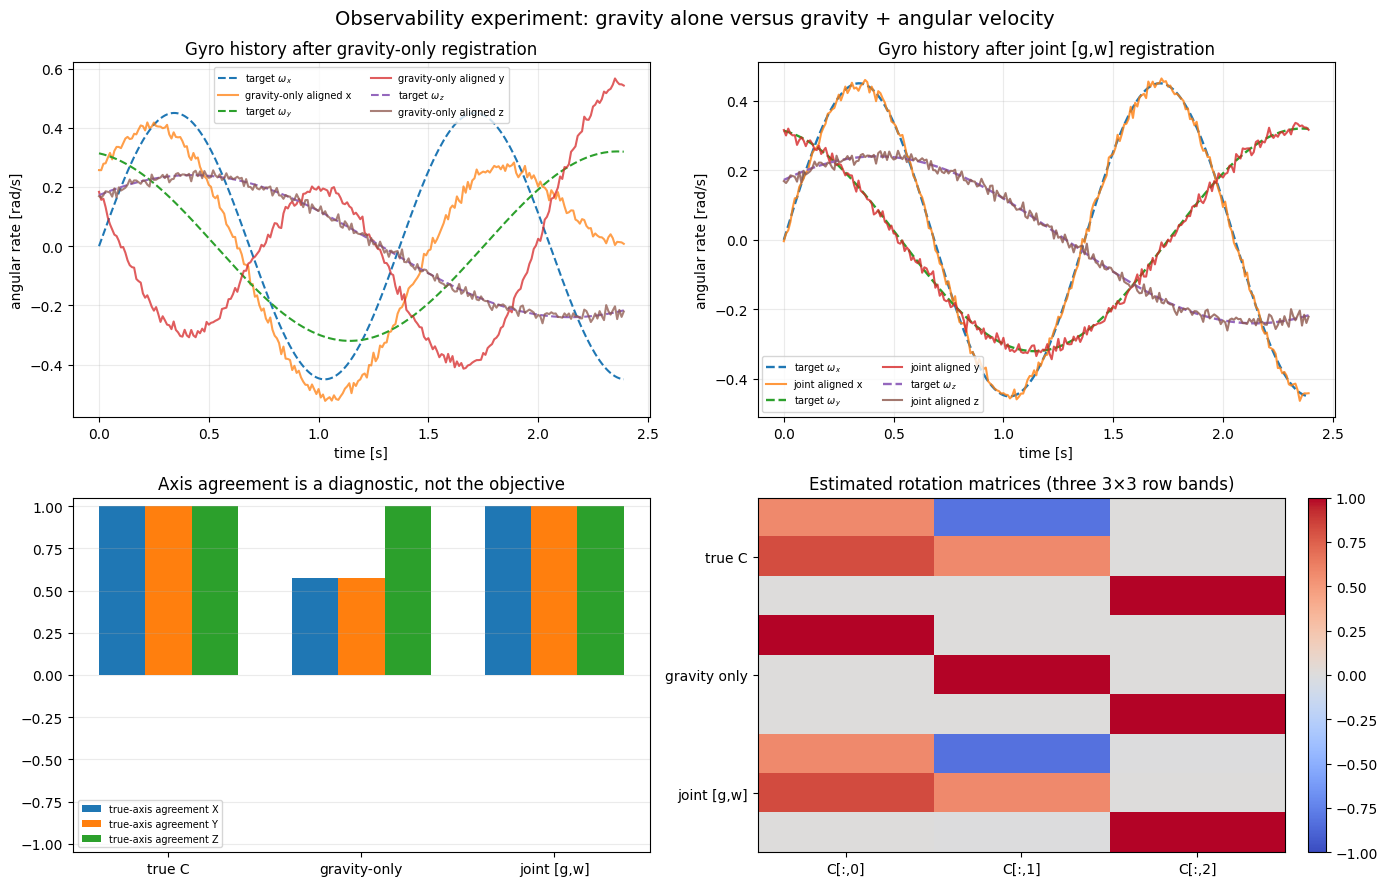

In [33]:
# Ground-truth mount rotation: source-sensor coordinates -> reference-body coordinates.
rng = np.random.default_rng(7)
n_demo = 240
t_demo = np.arange(n_demo) / 100.0
C_true_demo = Rot.from_euler("z", 55.0, degrees=True).as_matrix()

# In this idealized experiment the reference gravity is constant and vertical.
g_ref_demo = np.tile([0.0, 0.0, -G0], (n_demo, 1))
# A pure yaw mount rotation leaves this gravity vector unchanged.
g_src_demo = g_ref_demo @ C_true_demo

# Multi-axis rate excitation: each component changes over time.
w_ref_demo = np.column_stack([
    0.45 * np.sin(2*np.pi*0.73*t_demo),
    0.32 * np.cos(2*np.pi*0.41*t_demo + 0.2),
    0.24 * np.sin(2*np.pi*0.29*t_demo + 0.8),
])
sigma_w_demo = 0.012  # rad/s, standard deviation per gyro axis in this simulation
w_src_demo = w_ref_demo @ C_true_demo + rng.normal(0.0, sigma_w_demo, (n_demo, 3))

# Joint vectors use the exact order [g_x,g_y,g_z,w_x,w_y,w_z].
T_joint_demo = np.column_stack([g_ref_demo, w_ref_demo])
S_joint_demo = np.column_stack([g_src_demo, w_src_demo])
T_grav_demo = np.column_stack([g_ref_demo, np.zeros_like(w_ref_demo)])
S_grav_demo = np.column_stack([g_src_demo, np.zeros_like(w_src_demo)])

# Illustrative covariance: isotropic per block, with physical units retained.
P_demo = np.diag([0.025**2]*3 + [sigma_w_demo**2]*3)
PT_demo = np.repeat(P_demo[None, :, :], n_demo, axis=0)
PS_demo = np.repeat(P_demo[None, :, :], n_demo, axis=0)

# Gravity-only: gyro block is zero so it carries no directional information.
C0_g_demo = weighted_wahba_init(T_grav_demo, PT_demo, S_grav_demo, PS_demo)
C_g_demo, H_g_demo = weighted_wahba(T_grav_demo, PT_demo, S_grav_demo, PS_demo, C0_g_demo)

# Joint [g,w]: same covariance-aware implementation, now rate dynamics contribute.
C0_joint_demo = weighted_wahba_init(T_joint_demo, PT_demo, S_joint_demo, PS_demo)
C_joint_demo, H_joint_demo = weighted_wahba(T_joint_demo, PT_demo, S_joint_demo, PS_demo, C0_joint_demo)

def rotation_error_deg_demo(C_est, C_true):
    rel = C_est @ C_true.T
    cosine = np.clip((np.trace(rel) - 1.0) / 2.0, -1.0, 1.0)
    return float(np.degrees(np.arccos(cosine)))

err_g_demo = rotation_error_deg_demo(C_g_demo, C_true_demo)
err_joint_demo = rotation_error_deg_demo(C_joint_demo, C_true_demo)
print(f"True mounting yaw:                  55.00 deg")
print(f"Gravity-only registration error:    {err_g_demo:.3f} deg")
print(f"Joint gravity + gyro error:         {err_joint_demo:.3f} deg")
print(f"Gravity-only information eigenvalues: {np.linalg.eigvalsh(H_g_demo)}")
print(f"Joint information eigenvalues:        {np.linalg.eigvalsh(H_joint_demo)}")

fig = plt.figure(figsize=(14, 9))
ax1 = fig.add_subplot(2, 2, 1)
for j, label in enumerate("xyz"):
    ax1.plot(t_demo, w_ref_demo[:, j], linestyle="--", linewidth=1.5, label=f"target $\\omega_{label}$")
    ax1.plot(t_demo, (w_src_demo @ C_g_demo.T)[:, j], alpha=0.75, label=f"gravity-only aligned {label}")
ax1.set_title("Gyro history after gravity-only registration")
ax1.set_xlabel("time [s]"); ax1.set_ylabel("angular rate [rad/s]"); ax1.grid(alpha=0.25)
ax1.legend(fontsize=7, ncol=2)

ax2 = fig.add_subplot(2, 2, 2)
for j, label in enumerate("xyz"):
    ax2.plot(t_demo, w_ref_demo[:, j], linestyle="--", linewidth=1.7, label=f"target $\\omega_{label}$")
    ax2.plot(t_demo, (w_src_demo @ C_joint_demo.T)[:, j], alpha=0.8, label=f"joint aligned {label}")
ax2.set_title("Gyro history after joint [g,w] registration")
ax2.set_xlabel("time [s]"); ax2.set_ylabel("angular rate [rad/s]"); ax2.grid(alpha=0.25)
ax2.legend(fontsize=7, ncol=2)

ax3 = fig.add_subplot(2, 2, 3)
width = 0.24
for j, label in enumerate(["X", "Y", "Z"]):
    ax3.bar(np.arange(3) + (j-1)*width,
            [C_true_demo[:, j].dot(C_true_demo[:, j]), C_g_demo[:, j].dot(C_true_demo[:, j]), C_joint_demo[:, j].dot(C_true_demo[:, j])],
            width=width, label=f"true-axis agreement {label}")
ax3.set_xticks(np.arange(3), ["true C", "gravity-only", "joint [g,w]"])
ax3.set_ylim(-1.05, 1.05)
ax3.set_title("Axis agreement is a diagnostic, not the objective")
ax3.grid(axis="y", alpha=0.25); ax3.legend(fontsize=7)

ax4 = fig.add_subplot(2, 2, 4)
matrices = [C_true_demo, C_g_demo, C_joint_demo]
labels = ["true C", "gravity only", "joint [g,w]"]
im = ax4.imshow(np.vstack(matrices), vmin=-1, vmax=1, cmap="coolwarm", aspect="auto")
ax4.set_xticks([0, 1, 2], ["C[:,0]", "C[:,1]", "C[:,2]"])
ax4.set_yticks([1, 4, 7], labels)
ax4.set_title("Estimated rotation matrices (three 3×3 row bands)")
ax4.set_ylim(8.5, -0.5)
ax4.grid(False)
fig.colorbar(im, ax=ax4, fraction=0.046, pad=0.04)
fig.suptitle("Observability experiment: gravity alone versus gravity + angular velocity", fontsize=14)
fig.tight_layout()
plt.show()

### What to look for

1. The gravity-only rate-aligned curves do not match the target rates because the estimated relative yaw remains ambiguous.
2. The joint registration should recover the known mounting rotation closely, so the transformed gyro traces overlap the target.
3. The information matrix for gravity-only has a very small (ideally zero) eigenvalue associated with the missing yaw direction. The joint information matrix is full-rank under this multi-axis excitation.
4. With real data, covariance weighting prevents a noisy or nearly zero gyro vector from dominating. If angular motion is not excited, or its uncertainty is large, the yaw variance should remain large; the estimator cannot create information that the sensors did not measure.

The third panel is deliberately labelled a *diagnostic*: the trace-based registration objective, covariance structure, and geodesic rotation error are the meaningful criteria. Component-wise matrix comparisons alone are not an invariant accuracy measure.

## 11. Full-covariance information fusion

For sensor estimates `y_i` with covariance `P_i`, independent conditional estimates combine in information form:

\[
 \Lambda_f=\sum_i P_i^{-1},\quad P_f=\Lambda_f^{-1},\quad
 y_f=P_f\sum_i P_i^{-1}y_i.
\]

This is not a median and it is not a per-axis scalar average. A correlated covariance can encode that uncertainty along one combination of axes is larger than along another, and full matrix weighting uses that structure. The formulas assume the sensors’ errors are conditionally independent given the modeled state; shared modeling errors can violate that assumption.

### `fuse_information`

**Purpose.** Performs full-covariance information fusion for multiple sensors at each sample.

**Mathematical / physical interpretation.** For sensor `i`, precision is `Λᵢ=Pᵢ⁻¹`. The fused covariance is `(ΣΛᵢ)⁻¹`, and the fused mean is `P_f ΣΛᵢyᵢ`. The einsums are batched tensor contractions, and chunking limits peak memory use.

**Why the implementation is structured this way.** The statements below are interpreted in order; follow the dimensions, frames, and units alongside the values.

**Execution walk-through.** The bullets below are a guide to each top-level operation and important branch/loop. After reading them, run the source cell and inspect the values/shapes at a breakpoint or by adding a temporary print.

- **Assignment** — `Y = …`: evaluate `np.asarray(Y, float)` and store the result in `Y`. Check the shape and units of the right-hand side.
- **Assignment** — `P = …`: evaluate `np.asarray(P, float)` and store the result in `P`. Check the shape and units of the right-hand side.
- **Assignment** — `(m, n, d) = …`: evaluate `Y.shape` and store the result in `(m, n, d)`. Check the shape and units of the right-hand side.
- **Assignment** — `yf = …`: evaluate `np.empty((n, d))` and store the result in `yf`. Check the shape and units of the right-hand side.
- **Assignment** — `Pf = …`: evaluate `np.empty((n, d, d))` and store the result in `Pf`. Check the shape and units of the right-hand side.
- **Loop** — `for i0 in range(0, n, chunk)`. The indented body runs once per sample, sensor, axis, or iteration.
  - **Assignment** — `i1 = …`: evaluate `min(n, i0 + chunk)` and store the result in `i1`. Check the shape and units of the right-hand side.
  - **Assignment** — `L = …`: evaluate `psd_inverse(P[:, i0:i1])` and store the result in `L`. Check the shape and units of the right-hand side.
  - **Assignment** — `Pk = …`: evaluate `psd_inverse(L.sum(axis=0))` and store the result in `Pk`. Check the shape and units of the right-hand side.
  - **Assignment** — `bvec = …`: evaluate `np.einsum("mnij,mnj->ni", L, Y[:, i0:i1])` and store the result in `bvec`. Check the shape and units of the right-hand side.
  - **Assignment** — `yf[i0:i1] = …`: evaluate `np.einsum("nij,nj->ni", Pk, bvec)` and store the result in `yf[i0:i1]`. Check the shape and units of the right-hand side.
  - **Assignment** — `Pf[i0:i1] = …`: evaluate `0.5 * (Pk + np.swapaxes(Pk, -1, -2))` and store the result in `Pf[i0:i1]`. Check the shape and units of the right-hand side.
- **Return** — return `yf, Pf` to the caller; this is the function’s output contract.

In [34]:
def fuse_information(Y, P, chunk=20000):
    """Full covariance-weighted information fusion, sample by sample (batched).
    Y: (m,n,d) estimates of m sensors, P: (m,n,d,d) covariances."""
    Y = np.asarray(Y, float)
    P = np.asarray(P, float)
    m, n, d = Y.shape
    yf = np.empty((n, d)); Pf = np.empty((n, d, d))
    for i0 in range(0, n, chunk):
        i1 = min(n, i0 + chunk)
        L = psd_inverse(P[:, i0:i1])                       # (m,c,d,d)
        Pk = psd_inverse(L.sum(axis=0))                    # (c,d,d)
        bvec = np.einsum("mnij,mnj->ni", L, Y[:, i0:i1])
        yf[i0:i1] = np.einsum("nij,nj->ni", Pk, bvec)
        Pf[i0:i1] = 0.5 * (Pk + np.swapaxes(Pk, -1, -2))
    return yf, Pf

### `fused_Q_from_individuals`

**Purpose.** Approximates a fused process covariance for the second, post-fusion smoother.

**Mathematical / physical interpretation.** Each sensor’s acceleration and angular-rate process variance is rotated into Earth coordinates and averaged. This supplies a practical temporal-regularization scale, but it is not a complete exact joint process model.

**Why the implementation is structured this way.** The statements below are interpreted in order; follow the dimensions, frames, and units alongside the values.

**Execution walk-through.** The bullets below are a guide to each top-level operation and important branch/loop. After reading them, run the source cell and inspect the values/shapes at a breakpoint or by adding a temporary print.

- **Assignment** — `n = …`: evaluate `len(results[sensors[0]]["earth15"])` and store the result in `n`. Check the shape and units of the right-hand side.
- **Assignment** — `Q = …`: evaluate `np.zeros((n, 6, 6))` and store the result in `Q`. Check the shape and units of the right-hand side.
- **Loop** — `for s in sensors`. The indented body runs once per sample, sensor, axis, or iteration.
  - **Assignment** — `r = …`: evaluate `results[s]` and store the result in `r`. Check the shape and units of the right-hand side.
  - **Assignment** — `q = …`: evaluate `r["qhist"]` and store the result in `q`. Check the shape and units of the right-hand side.
  - **Assignment** — `C = …`: evaluate `r["C"]` and store the result in `C`. Check the shape and units of the right-hand side.
  - **Assignment** — `R = …`: evaluate `r["R_hist"]` and store the result in `R`. Check the shape and units of the right-hand side.
  - **Assignment** — `Qa_body = …`: evaluate `q[:, SL["a"], None] * np.eye(3)[None, :, :]` and store the result in `Qa_body`. Check the shape and units of the right-hand side.
  - **Assignment** — `Qw_body = …`: evaluate `q[:, SL["w"], None] * np.eye(3)[None, :, :]` and store the result in `Qw_body`. Check the shape and units of the right-hand side.
  - **Loop** — `for k in range(n)`. The indented body runs once per sample, sensor, axis, or iteration.
    - **Assignment** — `T = …`: evaluate `R[k] @ C` and store the result in `T`. Check the shape and units of the right-hand side.
    - **In-place-style update** — `Q[k, :3, :3] Add …`: update the existing value rather than creating a new named output.
    - **In-place-style update** — `Q[k, 3:, 3:] Add …`: update the existing value rather than creating a new named output.
- **Return** — return `Q / max(len(sensors), 1)` to the caller; this is the function’s output contract.

In [35]:
def fused_Q_from_individuals(results, sensors):
    """Approximate fused process covariance for the final random-walk RTS."""
    n = len(results[sensors[0]]["earth15"])
    Q = np.zeros((n, 6, 6))
    for s in sensors:
        r = results[s]
        q = r["qhist"]
        C = r["C"]
        R = r["R_hist"]
        Qa_body = q[:, SL["a"], None] * np.eye(3)[None, :, :]
        Qw_body = q[:, SL["w"], None] * np.eye(3)[None, :, :]
        for k in range(n):
            T = R[k] @ C
            Q[k, :3, :3] += T @ Qa_body[k] @ T.T
            Q[k, 3:, 3:] += T @ Qw_body[k] @ T.T
    return Q / max(len(sensors), 1)

### `second_rts_random_walk`

**Purpose.** Applies a second six-state identity-dynamics Kalman smoother to fused `[a_E,w_E]`.

**Mathematical / physical interpretation.** The model is `xₖ₊₁=xₖ+qₖ`, with observation `yₖ=xₖ+vₖ`. `r_inflation` scales measurement covariance and `q_scale` scales process covariance.

**Why the implementation is structured this way.** The source labels this a temporal regularizer, not an exact second Bayesian smoother: the per-IMU RTS estimates already have time correlations that are not represented in the stored per-sample covariance.

**Execution walk-through.** The bullets below are a guide to each top-level operation and important branch/loop. After reading them, run the source cell and inspect the values/shapes at a breakpoint or by adding a temporary print.

- **Assignment** — `(n, d) = …`: evaluate `y.shape` and store the result in `(n, d)`. Check the shape and units of the right-hand side.
- **Assignment** — `I = …`: evaluate `np.eye(d)` and store the result in `I`. Check the shape and units of the right-hand side.
- **Assignment** — `Rm = …`: evaluate `max(float(r_inflation), 1e-12) * P` and store the result in `Rm`. Check the shape and units of the right-hand side.
- **Assignment** — `Q = …`: evaluate `max(float(q_scale), 0.0) * Q` and store the result in `Q`. Check the shape and units of the right-hand side.
- **Assignment** — `xf = …`: evaluate `np.empty_like(y)` and store the result in `xf`. Check the shape and units of the right-hand side.
- **Assignment** — `Pf = …`: evaluate `np.empty_like(P)` and store the result in `Pf`. Check the shape and units of the right-hand side.
- **Assignment** — `xp = …`: evaluate `np.empty_like(y)` and store the result in `xp`. Check the shape and units of the right-hand side.
- **Assignment** — `Pp = …`: evaluate `np.empty_like(P)` and store the result in `Pp`. Check the shape and units of the right-hand side.
- **Assignment** — `x = …`: evaluate `y[0].copy()` and store the result in `x`. Check the shape and units of the right-hand side.
- **Assignment** — `Pc = …`: evaluate `P[0].copy()` and store the result in `Pc`. Check the shape and units of the right-hand side.
- **Assignment** — `(xf[0], Pf[0], xp[0], Pp[0]) = …`: evaluate `x, Pc, x, Pc` and store the result in `(xf[0], Pf[0], xp[0], Pp[0])`. Check the shape and units of the right-hand side.
- **Loop** — `for k in range(1, n)`. The indented body runs once per sample, sensor, axis, or iteration.
  - **Assignment** — `xpred = …`: evaluate `x` and store the result in `xpred`. Check the shape and units of the right-hand side.
  - **Assignment** — `Ppred = …`: evaluate `Pc + Q[k]` and store the result in `Ppred`. Check the shape and units of the right-hand side.
  - **Assignment** — `S = …`: evaluate `Ppred + Rm[k]` and store the result in `S`. Check the shape and units of the right-hand side.
  - **Assignment** — `K = …`: evaluate `Ppred @ psd_inverse(S)` and store the result in `K`. Check the shape and units of the right-hand side.
  - **Assignment** — `x = …`: evaluate `xpred + K @ (y[k] - xpred)` and store the result in `x`. Check the shape and units of the right-hand side.
  - **Assignment** — `IK = …`: evaluate `I - K` and store the result in `IK`. Check the shape and units of the right-hand side.
  - **Assignment** — `Pc = …`: evaluate `IK @ Ppred @ IK.T + K @ Rm[k] @ K.T` and store the result in `Pc`. Check the shape and units of the right-hand side.
  - **Assignment** — `Pc = …`: evaluate `0.5 * (Pc + Pc.T)` and store the result in `Pc`. Check the shape and units of the right-hand side.
  - **Assignment** — `(xf[k], Pf[k], xp[k], Pp[k]) = …`: evaluate `x, Pc, xpred, Ppred` and store the result in `(xf[k], Pf[k], xp[k], Pp[k])`. Check the shape and units of the right-hand side.
- **Assignment** — `xs = …`: evaluate `xf.copy()` and store the result in `xs`. Check the shape and units of the right-hand side.
- **Assignment** — `Ps = …`: evaluate `Pf.copy()` and store the result in `Ps`. Check the shape and units of the right-hand side.
- The function has 2 further top-level statement(s). Their control flow follows the same patterns visible above; the source cell preserves the complete implementation.

In [36]:
def second_rts_random_walk(y, P, Q, r_inflation=SECOND_RTS_R_INFLATION, q_scale=SECOND_RTS_Q_SCALE):
    """6-state H=I Kalman smoother with F=I random-walk dynamics."""
    n, d = y.shape
    I = np.eye(d)
    Rm = max(float(r_inflation), 1e-12) * P
    Q = max(float(q_scale), 0.0) * Q

    xf = np.empty_like(y); Pf = np.empty_like(P)
    xp = np.empty_like(y); Pp = np.empty_like(P)
    x = y[0].copy(); Pc = P[0].copy()
    xf[0], Pf[0], xp[0], Pp[0] = x, Pc, x, Pc

    for k in range(1, n):
        xpred = x
        Ppred = Pc + Q[k]
        S = Ppred + Rm[k]
        K = Ppred @ psd_inverse(S)
        x = xpred + K @ (y[k] - xpred)
        IK = I - K
        Pc = IK @ Ppred @ IK.T + K @ Rm[k] @ K.T
        Pc = 0.5 * (Pc + Pc.T)
        xf[k], Pf[k], xp[k], Pp[k] = x, Pc, xpred, Ppred

    xs = xf.copy(); Ps = Pf.copy()
    for k in range(n - 2, -1, -1):
        Ck = Pf[k] @ psd_inverse(Pp[k + 1])
        xs[k] = xf[k] + Ck @ (xs[k + 1] - xp[k + 1])
        Ps[k] = Pf[k] + Ck @ (Ps[k + 1] - Pp[k + 1]) @ Ck.T
        Ps[k] = 0.5 * (Ps[k] + Ps[k].T)
    return xs, Ps

## 12. Navigation integration and plotting

Only after the final `[a_E,w_E]` history is chosen do we integrate it. The trapezoidal updates are

\[
 v_{k+1}=v_k+\tfrac{dt}{2}(a_k+a_{k+1}),\qquad
 p_{k+1}=p_k+\tfrac{dt}{2}(v_k+v_{k+1}).
\]

Integration magnifies low-frequency errors: a constant acceleration bias creates velocity error growing roughly linearly and position error growing roughly quadratically. The position plots therefore diagnose combined bias, gravity compensation, attitude, and integration quality—not just the quality of the instantaneous acceleration estimate.

### `integrate_navigation`

**Purpose.** Integrates Earth-frame acceleration to velocity/position and angular rate to orientation.

**Mathematical / physical interpretation.** Trapezoidal acceleration integration updates velocity, and trapezoidal velocity integration updates position. Angular increments use the midpoint Earth-frame rate and an SO(3) exponential. Small bias/tilt errors can grow substantially after one or two integrations.

**Why the implementation is structured this way.** The statements below are interpreted in order; follow the dimensions, frames, and units alongside the values.

**Execution walk-through.** The bullets below are a guide to each top-level operation and important branch/loop. After reading them, run the source cell and inspect the values/shapes at a breakpoint or by adding a temporary print.

- **Assignment** — `n = …`: evaluate `len(aE)` and store the result in `n`. Check the shape and units of the right-hand side.
- **Assignment** — `R = …`: evaluate `np.empty((n, 3, 3))` and store the result in `R`. Check the shape and units of the right-hand side.
- **Assignment** — `theta = …`: evaluate `np.empty((n, 3))` and store the result in `theta`. Check the shape and units of the right-hand side.
- **Assignment** — `v = …`: evaluate `np.zeros((n, 3))` and store the result in `v`. Check the shape and units of the right-hand side.
- **Assignment** — `p = …`: evaluate `np.zeros((n, 3))` and store the result in `p`. Check the shape and units of the right-hand side.
- **Assignment** — `R[0] = …`: evaluate `np.eye(3)` and store the result in `R[0]`. Check the shape and units of the right-hand side.
- **Assignment** — `theta[0] = …`: evaluate `0.0` and store the result in `theta[0]`. Check the shape and units of the right-hand side.
- **Loop** — `for k in range(n - 1)`. The indented body runs once per sample, sensor, axis, or iteration.
  - **Assignment** — `wm = …`: evaluate `0.5 * (wE[k] + wE[k + 1])` and store the result in `wm`. Check the shape and units of the right-hand side.
  - **Assignment** — `R[k + 1] = …`: evaluate `exp_so3(wm * dt) @ R[k]` and store the result in `R[k + 1]`. Check the shape and units of the right-hand side.
  - **Assignment** — `theta[k + 1] = …`: evaluate `Rot.from_matrix(R[k + 1]).as_rotvec()` and store the result in `theta[k + 1]`. Check the shape and units of the right-hand side.
  - **Assignment** — `v[k + 1] = …`: evaluate `v[k] + 0.5 * dt * (aE[k] + aE[k + 1])` and store the result in `v[k + 1]`. Check the shape and units of the right-hand side.
  - **Assignment** — `p[k + 1] = …`: evaluate `p[k] + 0.5 * dt * (v[k] + v[k + 1])` and store the result in `p[k + 1]`. Check the shape and units of the right-hand side.
- **Return** — return `{ "aE": aE, "wE": wE, "v": v, "p": p, "theta": theta, "R": R, "q_xyzw": Rot.from_matrix(R).as_quat(), }` to the caller; this is the function’s output contract.

In [37]:
def integrate_navigation(aE, wE, dt):
    n = len(aE)
    R = np.empty((n, 3, 3)); theta = np.empty((n, 3))
    v = np.zeros((n, 3)); p = np.zeros((n, 3))
    R[0] = np.eye(3); theta[0] = 0.0
    for k in range(n - 1):
        wm = 0.5 * (wE[k] + wE[k + 1])
        R[k + 1] = exp_so3(wm * dt) @ R[k]
        theta[k + 1] = Rot.from_matrix(R[k + 1]).as_rotvec()
        v[k + 1] = v[k] + 0.5 * dt * (aE[k] + aE[k + 1])
        p[k + 1] = p[k] + 0.5 * dt * (v[k] + v[k + 1])
    return {
        "aE": aE, "wE": wE, "v": v, "p": p, "theta": theta,
        "R": R, "q_xyzw": Rot.from_matrix(R).as_quat(),
    }

### `nav_from_projected`

**Purpose.** Adapts a projected 15-state trajectory to the navigation integrator.

**Mathematical / physical interpretation.** The first six columns are `[a_E,w_E]`; bias and gravity blocks remain available elsewhere but are not needed for integration.

**Why the implementation is structured this way.** The statements below are interpreted in order; follow the dimensions, frames, and units alongside the values.

**Execution walk-through.** The bullets below are a guide to each top-level operation and important branch/loop. After reading them, run the source cell and inspect the values/shapes at a breakpoint or by adding a temporary print.

- **Return** — return `integrate_navigation(y15[:, :3], y15[:, 3:6], dt)` to the caller; this is the function’s output contract.

In [38]:
def nav_from_projected(y15, dt):
    return integrate_navigation(y15[:, :3], y15[:, 3:6], dt)

### `_time`

**Purpose.** Builds the sample time vector from an index and fixed sample period.

**Mathematical / physical interpretation.** The time grid is `tₖ=k·dt`, so the final time is `(n−1)dt` rather than `n·dt`.

**Why the implementation is structured this way.** The statements below are interpreted in order; follow the dimensions, frames, and units alongside the values.

**Execution walk-through.** The bullets below are a guide to each top-level operation and important branch/loop. After reading them, run the source cell and inspect the values/shapes at a breakpoint or by adding a temporary print.

- **Return** — return `np.arange(n) * dt` to the caller; this is the function’s output contract.

In [39]:
def _time(n, dt):
    return np.arange(n) * dt

### Plotting utilities: distinguish physical axes from algorithm variants

Each quantity is shown as three aligned time-history panels for X/Y/Z. Display scaling converts units for readability; it does not modify the underlying values. A smoother curve is not automatically more accurate—compare uncertainty, residuals, and known motion as well as visual smoothness.

### `plot_quantity`

**Purpose.** Plots each axis of a quantity for individual IMUs, fused estimates, and optionally second-RTS estimates.

**Mathematical / physical interpretation.** Scale factors are applied only for display. The stored data remain SI/rad units. Line style and color distinguish fusion stage, while row panels distinguish X/Y/Z.

**Why the implementation is structured this way.** The statements below are interpreted in order; follow the dimensions, frames, and units alongside the values.

**Execution walk-through.** The bullets below are a guide to each top-level operation and important branch/loop. After reading them, run the source cell and inspect the values/shapes at a breakpoint or by adding a temporary print.

- **Assignment** — `(label, field, scale, unit) = …`: evaluate `QTY[key]` and store the result in `(label, field, scale, unit)`. Check the shape and units of the right-hand side.
- **Assignment** — `(fig, ax) = …`: evaluate `plt.subplots(3, 1, figsize=(15, 9), sharex=True)` and store the result in `(fig, ax)`. Check the shape and units of the right-hand side.
- **Loop** — `for (s, r) in sensor_results.items()`. The indented body runs once per sample, sensor, axis, or iteration.
  - **Assignment** — `x = …`: evaluate `r[field] * scale` and store the result in `x`. Check the shape and units of the right-hand side.
  - **Loop** — `for j in range(3)`. The indented body runs once per sample, sensor, axis, or iteration.
    - **Expression / function call** — `ax[j].plot(t, x[:, j], lw=0.7, alpha=0.7, label=s if j == 0 else None)`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Conditional** — evaluate `fused_nav is not None`. This branch protects special cases or chooses an algorithmic path.
  - **Assignment** — `xf = …`: evaluate `fused_nav[field] if field in fused_nav else fused_y` and store the result in `xf`. Check the shape and units of the right-hand side.
  - **Conditional** — evaluate `xf is not None`. This branch protects special cases or chooses an algorithmic path.
    - **Loop** — `for j in range(3)`. The indented body runs once per sample, sensor, axis, or iteration.
      - **Expression / function call** — `ax[j].plot(t, xf[:, j] * scale, lw=2.0, color=COLORS["fused"], label="weighted fusion" if j == 0 else None)`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Conditional** — evaluate `fused_rts_nav is not None`. This branch protects special cases or chooses an algorithmic path.
  - **Assignment** — `xr = …`: evaluate `fused_rts_nav[field] if field in fused_rts_nav else fused_rts_y` and store the result in `xr`. Check the shape and units of the right-hand side.
  - **Conditional** — evaluate `xr is not None`. This branch protects special cases or chooses an algorithmic path.
    - **Loop** — `for j in range(3)`. The indented body runs once per sample, sensor, axis, or iteration.
      - **Expression / function call** — `ax[j].plot(t, xr[:, j] * scale, lw=2.0, ls="--", color=COLORS["fused_rts"], label="weighted fusion + second RTS" if j == 0 else None)`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Loop** — `for j in range(3)`. The indented body runs once per sample, sensor, axis, or iteration.
  - **Expression / function call** — `ax[j].set_ylabel(f"{AXES[j]} [{unit}]")`. Any function side-effects happen here; an unused return value is deliberately discarded.
  - **Expression / function call** — `ax[j].grid(alpha=0.25)`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Expression / function call** — `ax[0].set_title(label)`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Expression / function call** — `ax[0].legend(fontsize=8)`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Expression / function call** — `ax[-1].set_xlabel("time [s]")`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Expression / function call** — `fig.tight_layout()`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Expression / function call** — `fig.savefig(path, dpi=110)`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Expression / function call** — `plt.close(fig)`. Any function side-effects happen here; an unused return value is deliberately discarded.

In [40]:
def plot_quantity(path, t, sensor_results, fused_nav, fused_rts_nav, key, fused_y=None, fused_rts_y=None):
    label, field, scale, unit = QTY[key]
    fig, ax = plt.subplots(3, 1, figsize=(15, 9), sharex=True)
    for s, r in sensor_results.items():
        x = r[field] * scale
        for j in range(3):
            ax[j].plot(t, x[:, j], lw=0.7, alpha=0.7, label=s if j == 0 else None)
    if fused_nav is not None:
        xf = fused_nav[field] if field in fused_nav else fused_y
        if xf is not None:
            for j in range(3):
                ax[j].plot(t, xf[:, j] * scale, lw=2.0, color=COLORS["fused"], label="weighted fusion" if j == 0 else None)
    if fused_rts_nav is not None:
        xr = fused_rts_nav[field] if field in fused_rts_nav else fused_rts_y
        if xr is not None:
            for j in range(3):
                ax[j].plot(t, xr[:, j] * scale, lw=2.0, ls="--", color=COLORS["fused_rts"], label="weighted fusion + second RTS" if j == 0 else None)
    for j in range(3):
        ax[j].set_ylabel(f"{AXES[j]} [{unit}]")
        ax[j].grid(alpha=0.25)
    ax[0].set_title(label)
    ax[0].legend(fontsize=8)
    ax[-1].set_xlabel("time [s]")
    fig.tight_layout()
    fig.savefig(path, dpi=110)
    plt.close(fig)

### `plot_biases`

**Purpose.** Plots individual IMU bias estimates axis by axis.

**Mathematical / physical interpretation.** Biases are shown per sensor rather than fused into the navigation estimate; this keeps calibration diagnostics visible.

**Why the implementation is structured this way.** The statements below are interpreted in order; follow the dimensions, frames, and units alongside the values.

**Execution walk-through.** The bullets below are a guide to each top-level operation and important branch/loop. After reading them, run the source cell and inspect the values/shapes at a breakpoint or by adding a temporary print.

- **Assignment** — `(label, field, scale, unit) = …`: evaluate `QTY[key]` and store the result in `(label, field, scale, unit)`. Check the shape and units of the right-hand side.
- **Assignment** — `(fig, ax) = …`: evaluate `plt.subplots(3, 1, figsize=(15, 9), sharex=True)` and store the result in `(fig, ax)`. Check the shape and units of the right-hand side.
- **Loop** — `for (s, r) in sensor_results.items()`. The indented body runs once per sample, sensor, axis, or iteration.
  - **Assignment** — `x = …`: evaluate `r[field] * scale` and store the result in `x`. Check the shape and units of the right-hand side.
  - **Loop** — `for j in range(3)`. The indented body runs once per sample, sensor, axis, or iteration.
    - **Expression / function call** — `ax[j].plot(t, x[:, j], lw=0.75, alpha=0.75, label=s if j == 0 else None)`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Loop** — `for j in range(3)`. The indented body runs once per sample, sensor, axis, or iteration.
  - **Expression / function call** — `ax[j].set_ylabel(f"{AXES[j]} [{unit}]")`. Any function side-effects happen here; an unused return value is deliberately discarded.
  - **Expression / function call** — `ax[j].grid(alpha=0.25)`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Expression / function call** — `ax[0].set_title(label + " (individual IMUs)")`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Expression / function call** — `ax[0].legend(fontsize=8)`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Expression / function call** — `ax[-1].set_xlabel("time [s]")`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Expression / function call** — `fig.tight_layout()`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Expression / function call** — `fig.savefig(path, dpi=110)`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Expression / function call** — `plt.close(fig)`. Any function side-effects happen here; an unused return value is deliberately discarded.

In [41]:
def plot_biases(path, t, sensor_results, key):
    label, field, scale, unit = QTY[key]
    fig, ax = plt.subplots(3, 1, figsize=(15, 9), sharex=True)
    for s, r in sensor_results.items():
        x = r[field] * scale
        for j in range(3):
            ax[j].plot(t, x[:, j], lw=0.75, alpha=0.75, label=s if j == 0 else None)
    for j in range(3):
        ax[j].set_ylabel(f"{AXES[j]} [{unit}]")
        ax[j].grid(alpha=0.25)
    ax[0].set_title(label + " (individual IMUs)")
    ax[0].legend(fontsize=8)
    ax[-1].set_xlabel("time [s]")
    fig.tight_layout(); fig.savefig(path, dpi=110); plt.close(fig)

### `plot_fusion_comparison`

**Purpose.** Compares the immediate covariance-weighted fusion against fusion plus second RTS.

**Mathematical / physical interpretation.** Both curves should be interpreted as estimates under different temporal assumptions, not one automatically being “truth”. Less jagged does not always mean less biased.

**Why the implementation is structured this way.** The statements below are interpreted in order; follow the dimensions, frames, and units alongside the values.

**Execution walk-through.** The bullets below are a guide to each top-level operation and important branch/loop. After reading them, run the source cell and inspect the values/shapes at a breakpoint or by adding a temporary print.

- **Assignment** — `(label, field, scale, unit) = …`: evaluate `QTY[key]` and store the result in `(label, field, scale, unit)`. Check the shape and units of the right-hand side.
- **Assignment** — `(fig, ax) = …`: evaluate `plt.subplots(3, 1, figsize=(15, 9), sharex=True)` and store the result in `(fig, ax)`. Check the shape and units of the right-hand side.
- **Loop** — `for j in range(3)`. The indented body runs once per sample, sensor, axis, or iteration.
  - **Expression / function call** — `ax[j].plot(t, fused_nav[field][:, j] * scale, color=COLORS["fused"], lw=1.7, label="weighted fusion")`. Any function side-effects happen here; an unused return value is deliberately discarded.
  - **Conditional** — evaluate `fused_rts_nav is not None`. This branch protects special cases or chooses an algorithmic path.
    - **Expression / function call** — `ax[j].plot(t, fused_rts_nav[field][:, j] * scale, color=COLORS["fused_rts"], ls="--", lw=1.8, label="weighted fusion + second RTS")`. Any function side-effects happen here; an unused return value is deliberately discarded.
  - **Expression / function call** — `ax[j].set_ylabel(f"{AXES[j]} [{unit}]")`. Any function side-effects happen here; an unused return value is deliberately discarded.
  - **Expression / function call** — `ax[j].grid(alpha=0.25)`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Expression / function call** — `ax[0].set_title(label + " — fusion comparison")`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Expression / function call** — `ax[0].legend(fontsize=8)`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Expression / function call** — `ax[-1].set_xlabel("time [s]")`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Expression / function call** — `fig.tight_layout()`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Expression / function call** — `fig.savefig(path, dpi=110)`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Expression / function call** — `plt.close(fig)`. Any function side-effects happen here; an unused return value is deliberately discarded.

In [42]:
def plot_fusion_comparison(path, t, fused_nav, fused_rts_nav, key):
    label, field, scale, unit = QTY[key]
    fig, ax = plt.subplots(3, 1, figsize=(15, 9), sharex=True)
    for j in range(3):
        ax[j].plot(t, fused_nav[field][:, j] * scale, color=COLORS["fused"], lw=1.7, label="weighted fusion")
        if fused_rts_nav is not None:
            ax[j].plot(t, fused_rts_nav[field][:, j] * scale, color=COLORS["fused_rts"], ls="--", lw=1.8, label="weighted fusion + second RTS")
        ax[j].set_ylabel(f"{AXES[j]} [{unit}]"); ax[j].grid(alpha=0.25)
    ax[0].set_title(label + " — fusion comparison")
    ax[0].legend(fontsize=8); ax[-1].set_xlabel("time [s]")
    fig.tight_layout(); fig.savefig(path, dpi=110); plt.close(fig)

### `plot_norm`

**Purpose.** Plots the Euclidean norm of a three-vector trajectory quantity.

**Mathematical / physical interpretation.** For position and angular position, the norm provides a compact magnitude comparison, but it discards direction information; inspect the component plots too.

**Why the implementation is structured this way.** The statements below are interpreted in order; follow the dimensions, frames, and units alongside the values.

**Execution walk-through.** The bullets below are a guide to each top-level operation and important branch/loop. After reading them, run the source cell and inspect the values/shapes at a breakpoint or by adding a temporary print.

- **Assignment** — `(label, field, scale, unit) = …`: evaluate `QTY[key]` and store the result in `(label, field, scale, unit)`. Check the shape and units of the right-hand side.
- **Assignment** — `(fig, ax) = …`: evaluate `plt.subplots(figsize=(15, 5))` and store the result in `(fig, ax)`. Check the shape and units of the right-hand side.
- **Loop** — `for (s, r) in sensor_results.items()`. The indented body runs once per sample, sensor, axis, or iteration.
  - **Assignment** — `x = …`: evaluate `r[field] * scale` and store the result in `x`. Check the shape and units of the right-hand side.
  - **Expression / function call** — `ax.plot(t, np.linalg.norm(x, axis=1), lw=0.8, alpha=0.75, label=s)`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Conditional** — evaluate `fused_nav is not None and field in fused_nav`. This branch protects special cases or chooses an algorithmic path.
  - **Assignment** — `xf = …`: evaluate `fused_nav[field] * scale` and store the result in `xf`. Check the shape and units of the right-hand side.
  - **Expression / function call** — `ax.plot(t, np.linalg.norm(xf, axis=1), lw=2.2, color=COLORS["fused"], label="weighted fusion")`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Conditional** — evaluate `fused_rts_nav is not None and field in fused_rts_nav`. This branch protects special cases or chooses an algorithmic path.
  - **Assignment** — `xr = …`: evaluate `fused_rts_nav[field] * scale` and store the result in `xr`. Check the shape and units of the right-hand side.
  - **Expression / function call** — `ax.plot(t, np.linalg.norm(xr, axis=1), lw=2.2, ls="--", color=COLORS["fused_rts"], label="weighted fusion + second RTS")`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Expression / function call** — `ax.set_ylabel(f"|{field}| [{unit}]")`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Expression / function call** — `ax.set_xlabel("time [s]")`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Expression / function call** — `ax.set_title(f"{label} — modulus |{field}|")`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Expression / function call** — `ax.grid(alpha=0.25)`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Expression / function call** — `ax.legend(fontsize=8, ncol=2)`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Expression / function call** — `fig.tight_layout()`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Expression / function call** — `fig.savefig(path, dpi=110)`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Expression / function call** — `plt.close(fig)`. Any function side-effects happen here; an unused return value is deliberately discarded.

In [43]:
def plot_norm(path, t, sensor_results, fused_nav, fused_rts_nav, key):
    """Plot the modulus (Euclidean norm) of a 3-vector quantity.

    Useful for position and angular position, where the norm is the natural
    scalar to compare per-IMU vs covariance-weighted fusion.
    """
    label, field, scale, unit = QTY[key]
    fig, ax = plt.subplots(figsize=(15, 5))

    # Individual IMUs
    for s, r in sensor_results.items():
        x = r[field] * scale
        ax.plot(t, np.linalg.norm(x, axis=1), lw=0.8, alpha=0.75, label=s)

    # Covariance-weighted fusion
    if fused_nav is not None and field in fused_nav:
        xf = fused_nav[field] * scale
        ax.plot(t, np.linalg.norm(xf, axis=1), lw=2.2,
                color=COLORS["fused"], label="weighted fusion")

    # Fusion + second RTS
    if fused_rts_nav is not None and field in fused_rts_nav:
        xr = fused_rts_nav[field] * scale
        ax.plot(t, np.linalg.norm(xr, axis=1), lw=2.2, ls="--",
                color=COLORS["fused_rts"], label="weighted fusion + second RTS")

    ax.set_ylabel(f"|{field}| [{unit}]")
    ax.set_xlabel("time [s]")
    ax.set_title(f"{label} — modulus |{field}|")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8, ncol=2)
    fig.tight_layout()
    fig.savefig(path, dpi=110)
    plt.close(fig)

### Gravity-magnitude sanity check

The gravity direction is estimated, while its magnitude is known to be about `G0`. `constrain_gnorm` is a final-output normalization used for display/diagnostics; it does not feed a corrected vector back into the filter. This distinction prevents post-processing from being mistaken for a measurement update.

### `constrain_gnorm`

**Purpose.** Normalizes a gravity history to a prescribed magnitude without changing direction.

**Mathematical / physical interpretation.** The function is explicitly post-processing only. It does not feed modified gravity back into the EKF or registration.

**Why the implementation is structured this way.** The statements below are interpreted in order; follow the dimensions, frames, and units alongside the values.

**Execution walk-through.** The bullets below are a guide to each top-level operation and important branch/loop. After reading them, run the source cell and inspect the values/shapes at a breakpoint or by adding a temporary print.

- **Assignment** — `g = …`: evaluate `np.asarray(g, float)` and store the result in `g`. Check the shape and units of the right-hand side.
- **Return** — return `g * (g0 / np.maximum(np.linalg.norm(g, axis=-1, keepdims=True), 1e-12))` to the caller; this is the function’s output contract.

In [44]:
def constrain_gnorm(g, g0=G0):
    """Gravity-vector constraint ||g|| = G0: same direction, modulus fixed to G0.
    Applied to the final g outputs only (nothing upstream is modified)."""
    g = np.asarray(g, float)
    return g * (g0 / np.maximum(np.linalg.norm(g, axis=-1, keepdims=True), 1e-12))

### `plot_gnorm`

**Purpose.** Checks whether projected gravity magnitudes remain close to standard gravity.

**Mathematical / physical interpretation.** A norm plot is a useful sanity check for scaling, filter drift, or frame-transformation problems. A flat norm alone does not prove a correct attitude.

**Why the implementation is structured this way.** The statements below are interpreted in order; follow the dimensions, frames, and units alongside the values.

**Execution walk-through.** The bullets below are a guide to each top-level operation and important branch/loop. After reading them, run the source cell and inspect the values/shapes at a breakpoint or by adding a temporary print.

- **Assignment** — `(fig, ax) = …`: evaluate `plt.subplots(figsize=(15, 5))` and store the result in `(fig, ax)`. Check the shape and units of the right-hand side.
- **Loop** — `for (s, r) in sensor_results.items()`. The indented body runs once per sample, sensor, axis, or iteration.
  - **Expression / function call** — `ax.plot(t, np.linalg.norm(r["gE"], axis=1), lw=0.9, alpha=0.8, label=s)`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Conditional** — evaluate `fused_g is not None`. This branch protects special cases or chooses an algorithmic path.
  - **Expression / function call** — `ax.plot(t, np.linalg.norm(fused_g, axis=1), lw=2.0, ls="--", color=COLORS["fused"], label="consensus")`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Expression / function call** — `ax.axhline(G0, color="r", ls=":", lw=1.2, label=f"G0 = {G0:.5f}")`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Expression / function call** — `ax.set_ylabel(r"$|g|$ [m/s$^2$]")`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Expression / function call** — `ax.set_xlabel("time [s]")`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Expression / function call** — `ax.set_title("gravity vector — modulus |g|")`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Expression / function call** — `ax.grid(alpha=0.25)`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Expression / function call** — `ax.legend(fontsize=8, ncol=3)`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Expression / function call** — `fig.tight_layout()`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Expression / function call** — `fig.savefig(path, dpi=110)`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Expression / function call** — `plt.close(fig)`. Any function side-effects happen here; an unused return value is deliberately discarded.

In [45]:
def plot_gnorm(path, t, sensor_results, fused_g=None):
    """History of the modulus of the gravity vector |g| (per IMU, Earth-projected)."""
    fig, ax = plt.subplots(figsize=(15, 5))
    for s, r in sensor_results.items():
        ax.plot(t, np.linalg.norm(r["gE"], axis=1), lw=0.9, alpha=0.8, label=s)
    if fused_g is not None:
        ax.plot(t, np.linalg.norm(fused_g, axis=1), lw=2.0, ls="--", color=COLORS["fused"],
                label="consensus")
    ax.axhline(G0, color="r", ls=":", lw=1.2, label=f"G0 = {G0:.5f}")
    ax.set_ylabel(r"$|g|$ [m/s$^2$]"); ax.set_xlabel("time [s]")
    ax.set_title("gravity vector — modulus |g|")
    ax.grid(alpha=0.25); ax.legend(fontsize=8, ncol=3)
    fig.tight_layout(); fig.savefig(path, dpi=110); plt.close(fig)

## 13. Embedded IMU dynamics GIF renderer

The GIF is a diagnostic, not part of the state estimator. It synchronizes two views of the same time index:

- **Left:** the trajectory through Earth XYZ, with a plate-like body and coloured local axes attached to its current pose.
- **Right/top:** estimated attitude at a common pivot, making orientation differences visible without translation obscuring them.
- **Right/middle:** position X/Y/Z versus time.
- **Right/bottom:** cumulative component-wise integrated angular rate versus time.

Solid lines show the individual IMU and dashed lines show the final fusion. A shared time cursor links the 3D pose to the histories. Frame sampling is based on cumulative angular/linear activity, so the animation devotes more frames to motion and skips more quickly through still intervals.

In [46]:
MAX_FRAMES = 220
FPS = 20
DPI = 70
GIF_COLORS = ("tab:orange", "tab:blue", "tab:green", "tab:red", "tab:brown", "tab:pink", "tab:olive", "tab:cyan")


def frame_indices(w, p, dt, max_frames=MAX_FRAMES, rest=0.15):
    """Choose frames uniformly in accumulated angular + linear activity."""
    wn = np.linalg.norm(w, axis=1)
    sp = np.linalg.norm(np.gradient(p, dt, axis=0), axis=1)
    r = (wn / max(np.percentile(wn, 95), 1e-12)
         + sp / max(np.percentile(sp, 95), 1e-12) + rest)
    s = np.concatenate([[0.0], np.cumsum(0.5 * (r[1:] + r[:-1]) * dt)])
    idx = np.unique(np.clip(
        np.searchsorted(s, np.linspace(0.0, s[-1], max_frames)),
        0, len(p) - 1))
    if idx[-1] != len(p) - 1:
        idx = np.append(idx, len(p) - 1)
    return idx


def _plate(R, center, half):
    """Six rectangular faces for a small cuboid, rotated into Earth axes."""
    sx, sy, sz = half
    v = np.array([[x, y, z]
                  for x in (-sx, sx)
                  for y in (-sy, sy)
                  for z in (-sz, sz)])
    v = center + v @ R.T
    faces = [(0, 1, 3, 2), (4, 5, 7, 6), (0, 1, 5, 4),
             (2, 3, 7, 6), (0, 2, 6, 4), (1, 3, 7, 5)]
    return [v[list(face)] for face in faces]


def geodesic_deg(Ra, Rb):
    """SO(3) angular separation between paired rotation matrices, in degrees."""
    c = 0.5 * (np.einsum("nij,nij->n", Ra, Rb) - 1.0)
    return np.degrees(np.arccos(np.clip(c, -1.0, 1.0)))


def make_imu_dynamics_gif(path, sensor, dt, imu, fused,
                          imu_color="tab:orange", fused_color="black",
                          fused_label="fused", fps=20, max_frames=220, dpi=70):
    """Animate one IMU and the fused estimate in a common Earth frame.

    Each track must contain R:(n,3,3) body-to-Earth attitude, p:(n,3) metres,
    and w:(n,3) Earth-frame angular rate in rad/s.
    """
    n = len(imu["R"])
    t = np.arange(n) * dt
    tracks = {"imu": imu, "fused": fused}
    colors = {"imu": imu_color, "fused": fused_color}
    labels = {"imu": sensor, "fused": fused_label}
    R = {k: np.asarray(v["R"], float) for k, v in tracks.items()}
    P = {k: np.asarray(v["p"], float) * 1e3 for k, v in tracks.items()}  # display in mm
    TH = {k: np.degrees(np.cumsum(np.asarray(v["w"], float) * dt, axis=0))
          for k, v in tracks.items()}
    angle_gap = geodesic_deg(R["imu"], R["fused"])
    idx = frame_indices(np.asarray(fused["w"], float),
                        np.asarray(fused["p"], float), dt, max_frames=max_frames)

    # One common cubic box avoids the view changing from frame to frame.
    allp = np.concatenate([P["imu"], P["fused"]])
    lo, hi = allp.min(0), allp.max(0)
    ctr = 0.5 * (lo + hi)
    half = max(0.6 * float(np.max(hi - lo)), 1.0)
    body = (0.10 * half, 0.06 * half, 0.012 * half)
    Lax = 0.16 * half
    axis_colors = ("tab:red", "tab:green", "tab:blue")

    fig = plt.figure(figsize=(14.5, 8.2))
    gs = fig.add_gridspec(3, 2, width_ratios=[1.3, 1.0],
                          height_ratios=[1.25, 0.8, 0.8], hspace=0.55,
                          wspace=0.10, left=0.01, right=0.985,
                          top=0.93, bottom=0.06)
    ax = fig.add_subplot(gs[:, 0], projection="3d")
    axr = fig.add_subplot(gs[0, 1], projection="3d")
    axp = fig.add_subplot(gs[1, 1])
    axt = fig.add_subplot(gs[2, 1])
    title = fig.suptitle("", fontsize=12, weight="bold", family="monospace",
                         x=0.01, ha="left")

    # Left: trajectory scene. Limits are fixed across frames for fair comparison.
    ax.set_xlim(ctr[0] - half, ctr[0] + half)
    ax.set_ylim(ctr[1] - half, ctr[1] + half)
    ax.set_zlim(ctr[2] - half, ctr[2] + half)
    ax.set_box_aspect((1, 1, 1))
    ax.set_xlabel("X [mm]"); ax.set_ylabel("Y [mm]"); ax.set_zlabel("Z [mm] (up)")
    ax.view_init(elev=22, azim=-58)
    ax.plot([P["imu"][0, 0]], [P["imu"][0, 1]], [P["imu"][0, 2]],
            marker="*", ms=12, color="gold", mec="k", ls="none", label="start")
    art = {}
    for k in tracks:
        trail, = ax.plot([], [], [], color=colors[k], lw=1.8 if k == "imu" else 1.4,
                         ls="-" if k == "imu" else "--", label=labels[k])
        head, = ax.plot([], [], [], marker="o", ms=5, color=colors[k], ls="none")
        faces = Poly3DCollection(_plate(np.eye(3), np.zeros(3), body),
                                 facecolors=colors[k],
                                 edgecolors=colors[k] if k == "imu" else "k",
                                 alpha=0.35 if k == "imu" else 0.15,
                                 linewidths=1.0)
        ax.add_collection3d(faces)
        axes = [ax.plot([], [], [], color=axis_colors[j],
                        lw=2.6 if k == "imu" else 1.4,
                        ls="-" if k == "imu" else "--")[0] for j in range(3)]
        art[k] = {"trail": trail, "head": head, "faces": faces, "axes": axes}
    ax.legend(loc="upper left", fontsize=8)

    # Right/top: both attitudes share the origin so only rotational disagreement is seen.
    axr.set_xlim(-1, 1); axr.set_ylim(-1, 1); axr.set_zlim(-1, 1)
    axr.set_box_aspect((1, 1, 1)); axr.view_init(elev=20, azim=-58)
    axr.set_xticklabels([]); axr.set_yticklabels([]); axr.set_zticklabels([])
    axr.set_title("rotation in Earth frame (common pivot); body axes x/y/z = red/green/blue",
                  fontsize=8.5, pad=-4)
    for e, txt in zip(np.eye(3), "XYZ"):
        axr.plot([0, e[0]], [0, e[1]], [0, e[2]], color="0.4", lw=1.0, ls=":")
        axr.text(*(1.1 * e), txt, color="0.25", fontsize=9)
    rart = {}
    for k in tracks:
        faces = Poly3DCollection(_plate(np.eye(3), np.zeros(3), (0.5, 0.32, 0.06)),
                                 facecolors=colors[k],
                                 edgecolors=colors[k] if k == "imu" else "k",
                                 alpha=0.30 if k == "imu" else 0.12,
                                 linewidths=1.0)
        axr.add_collection3d(faces)
        axes = [axr.plot([], [], [], color=axis_colors[j],
                         lw=3.0 if k == "imu" else 1.5,
                         ls="-" if k == "imu" else "--")[0] for j in range(3)]
        rart[k] = {"faces": faces, "axes": axes}

    # Right/bottom: full histories plus animated cursors.
    prog = {}
    def style(a, ylabel, title_text):
        a.set_ylabel(ylabel, fontsize=8)
        a.set_title(title_text, fontsize=8.5, loc="left", pad=2)
        a.grid(alpha=0.25); a.tick_params(labelsize=7); a.set_xlim(t[0], t[-1])
    style(axp, "mm", "position p (x/y/z = red/green/blue; solid IMU, dashed fused)")
    style(axt, "deg", "cumulative component-wise integral ∫ω_E dt (illustrative, not Euler angles)")
    for axh, series, tag in ((axp, P, "p"), (axt, TH, "t")):
        for k in tracks:
            for j in range(3):
                axh.plot(t, series[k][:, j], color=axis_colors[j],
                         lw=2.0 if k == "imu" else 1.2,
                         ls="-" if k == "imu" else "--", alpha=0.25)
                prog[(tag, k, j)] = axh.plot([], [], color=axis_colors[j],
                                              lw=2.0 if k == "imu" else 1.2,
                                              ls="-" if k == "imu" else "--")[0]
    axt.set_xlabel("time [s]", fontsize=8)
    cursors = [axp.axvline(0, color="k", lw=0.9), axt.axvline(0, color="k", lw=0.9)]

    def setline(line, a, b):
        line.set_data([a[0], b[0]], [a[1], b[1]])
        line.set_3d_properties([a[2], b[2]])

    def update(fi):
        kk = int(idx[fi])
        playback = (t[idx[fi + 1]] - t[kk]) * fps if fi + 1 < len(idx) else 0.0
        title.set_text(f"{sensor} vs {fused_label}   t={t[kk]:6.2f}s   playback x{playback:.1f}   ΔR={angle_gap[kk]:.2f}°")
        slc = slice(0, kk + 1, max(1, kk // 1500 + 1))
        for k in tracks:
            Rk, pk, a = R[k][kk], P[k][kk], art[k]
            seg = P[k][slc]
            a["trail"].set_data(seg[:, 0], seg[:, 1])
            a["trail"].set_3d_properties(seg[:, 2])
            a["head"].set_data([pk[0]], [pk[1]])
            a["head"].set_3d_properties([pk[2]])
            a["faces"].set_verts(_plate(Rk, pk, body))
            rr = rart[k]
            rr["faces"].set_verts(_plate(Rk, np.zeros(3), (0.5, 0.32, 0.06)))
            for j in range(3):
                setline(a["axes"][j], pk, pk + Lax * Rk[:, j])
                setline(rr["axes"][j], np.zeros(3), 0.85 * Rk[:, j])
                prog[("p", k, j)].set_data(t[slc], P[k][slc, j])
                prog[("t", k, j)].set_data(t[slc], TH[k][slc, j])
        for cursor in cursors:
            cursor.set_xdata([t[kk], t[kk]])
        return []

    ani = FuncAnimation(fig, update, frames=len(idx), blit=False)
    ani.save(str(path), writer=PillowWriter(fps=fps), dpi=dpi)
    plt.close(fig)

### GIF renderer — line-by-line concepts

- **`frame_indices`** computes angular-rate magnitude and translational speed, normalizes each against its 95th percentile, adds a small `rest` term, integrates the activity score with trapezoidal quadrature, and samples equal intervals in that activity coordinate. The small constant ensures a nonzero progress score when the device is stationary.
- **`_plate`** defines eight vertices in the body’s local coordinates, rotates row-wise vertices with `v @ R.T`, adds the Earth-frame center, and returns six face vertex lists for Matplotlib's 3D polygon collection.
- **`geodesic_deg`** uses `cos(Δθ)=(tr(R_a^T R_b)-1)/2`. It clips the cosine to `[-1,1]` before `arccos` because floating-point roundoff can make a theoretically valid cosine slightly exceed that interval.
- **`make_imu_dynamics_gif`** precomputes the tracks and plot artists once. `update(fi)` only changes data/vertices for frame `fi`; rebuilding the whole figure every frame would be much slower.
- The right-bottom curve labelled `∫ω_E dt` is a **component-wise integral for visualization**, not a replacement for the rotation-matrix integration. Finite rotations do not generally commute, so integrated vector components are not identical to Euler angles or the SO(3) logarithm.
- The renderer receives positions in metres and displays them in millimetres. The rotation matrices are body-to-Earth and the rates are Earth-frame rad/s, matching the main pipeline wrapper below.

### `make_dynamics_gifs`: connect the pipeline outputs to the renderer

This wrapper chooses the final fused track (`nav_rts` if present, otherwise `nav_f`) and sets a label/color accordingly. For each sensor, it uses `R_hist[0] @ C_i` as the sensor’s initial Earth attitude, then composes that initial attitude with the integrated relative rotation history. The same initial pose is used when visualizing the fused rate, so the comparison emphasizes the difference caused by each IMU’s estimate rather than an arbitrary initial-coordinate offset.

In [47]:
def make_dynamics_gifs(file_out, sensors, results, nav_f, nav_rts, dt):
    """Write one Earth-frame motion GIF per IMU against the final fused track."""
    nav_fin = nav_rts if nav_rts is not None else nav_f
    fused_label = "fused + 2nd RTS" if nav_rts is not None else "fused"
    fused_color = COLORS["fused_rts"] if nav_rts is not None else COLORS["fused"]
    gif_dir = Path(file_out) / "gifs"
    gif_dir.mkdir(exist_ok=True)
    for i, sensor in enumerate(sensors):
        R0_sensor = results[sensor]["R_hist"][0] @ results[sensor]["C"]
        nav = results[sensor]["nav"]
        imu_track = {"R": nav["R"] @ R0_sensor, "p": nav["p"], "w": nav["wE"]}
        fused_track = {"R": nav_fin["R"] @ R0_sensor, "p": nav_fin["p"], "w": nav_fin["wE"]}
        out = gif_dir / f"dynamics_{sensor}_vs_fused.gif"
        make_imu_dynamics_gif(
            out, sensor, dt, imu_track, fused_track,
            imu_color=GIF_COLORS[i % len(GIF_COLORS)],
            fused_color=fused_color, fused_label=fused_label,
        )
        print(f"  saved {out.name}", flush=True)

### Small synthetic GIF preview (no sensor file required)

This next cell intentionally creates a short artificial trajectory so you can see the renderer before loading your experiment. It is not a performance test and its path is not a physical result; its purpose is to demonstrate how differences in position and attitude appear in the animation. The GIF is written to `imu_dynamics_gif_preview.gif` in the notebook's working directory and embedded below.

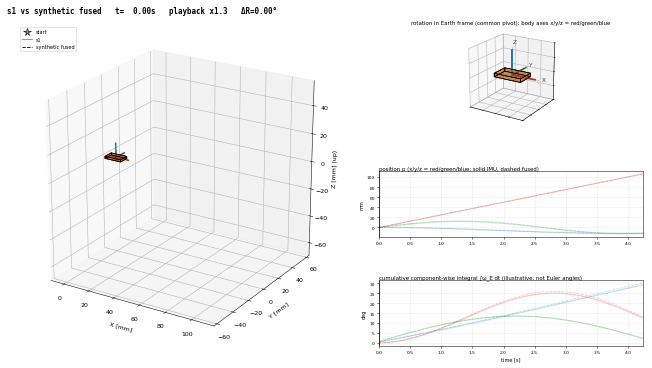

In [48]:
from IPython.display import Image, display

n_gif_demo = 54
dt_gif_demo = 0.08
t_gif_demo = np.arange(n_gif_demo) * dt_gif_demo
w_gif_demo = np.column_stack([
    0.24*np.sin(1.1*t_gif_demo),
    0.16*np.cos(0.7*t_gif_demo),
    0.10 + 0.025*np.sin(0.5*t_gif_demo),
])
R_gif_demo = np.empty((n_gif_demo, 3, 3))
R_gif_demo[0] = np.eye(3)
for k in range(n_gif_demo-1):
    w_mid = 0.5*(w_gif_demo[k] + w_gif_demo[k+1])
    R_gif_demo[k+1] = Rot.from_rotvec(w_mid*dt_gif_demo).as_matrix() @ R_gif_demo[k]
p_gif_demo = np.column_stack([
    0.025*t_gif_demo,
    0.012*np.sin(1.2*t_gif_demo),
    0.006*(np.cos(0.8*t_gif_demo)-1.0),
])
R_gif_fused_demo = np.empty_like(R_gif_demo)
R_gif_fused_demo[0] = np.eye(3)
w_gif_fused_demo = w_gif_demo + np.column_stack([
    0.008*np.sin(t_gif_demo), np.zeros(n_gif_demo), 0.004*np.ones(n_gif_demo)
])
for k in range(n_gif_demo-1):
    w_mid = 0.5*(w_gif_fused_demo[k] + w_gif_fused_demo[k+1])
    R_gif_fused_demo[k+1] = Rot.from_rotvec(w_mid*dt_gif_demo).as_matrix() @ R_gif_fused_demo[k]
imu_track_demo = {"R": R_gif_demo, "p": p_gif_demo, "w": w_gif_demo}
fused_track_demo = {"R": R_gif_fused_demo, "p": p_gif_demo + np.column_stack([np.zeros(n_gif_demo), 0.001*np.sin(t_gif_demo), np.zeros(n_gif_demo)]), "w": w_gif_fused_demo}
gif_preview_path = Path("imu_dynamics_gif_preview.gif")
make_imu_dynamics_gif(gif_preview_path, "s1", dt_gif_demo, imu_track_demo, fused_track_demo,
                      imu_color="tab:orange", fused_color="black",
                      fused_label="synthetic fused", max_frames=32, fps=8, dpi=45)
display(Image(filename=str(gif_preview_path), format="gif"))

## 14. The end-to-end per-file orchestrator

`process_file` is the point where all components meet. It is intentionally not called automatically: a notebook should not assume a particular `DATA/` directory exists or start writing a potentially large set of plots/GIFs without the user choosing the input path.

### `process_file`

**Purpose.** Runs the full per-CSV multi-IMU pipeline and writes plots, diagnostics, arrays, and animations.

**Mathematical / physical interpretation.** The sequence matters: filter/smooth each sensor; estimate constant mount rotations; form body-frame gravity/rate consensus; reconstruct attitude; project each sensor and covariance to Earth; fuse `[a,w]`; optionally smooth again; only then integrate velocity, position, and angular position.

**Why the implementation is structured this way.** The initial alignment interval is assumed stationary. Relative rotations are assumed constant, all IMUs synchronized, and acceleration origins coincident or close enough that lever-arm effects are negligible. See the assumptions section before interpreting position.

**Execution walk-through.** The bullets below are a guide to each top-level operation and important branch/loop. After reading them, run the source cell and inspect the values/shapes at a breakpoint or by adding a temporary print.

- **Assignment** — `(data, sensors, n) = …`: evaluate `load_csv(path, nmax=nmax)` and store the result in `(data, sensors, n)`. Check the shape and units of the right-hand side.
- **Assignment** — `file_out = …`: evaluate `out_root / path.stem` and store the result in `file_out`. Check the shape and units of the right-hand side.
- **Expression / function call** — `file_out.mkdir(parents=True, exist_ok=True)`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Assignment** — `xs = …`: evaluate `{}` and store the result in `xs`. Check the shape and units of the right-hand side.
- **Assignment** — `Ps = …`: evaluate `{}` and store the result in `Ps`. Check the shape and units of the right-hand side.
- **Assignment** — `qhist = …`: evaluate `{}` and store the result in `qhist`. Check the shape and units of the right-hand side.
- **Assignment** — `raw_acc = …`: evaluate `{}` and store the result in `raw_acc`. Check the shape and units of the right-hand side.
- **Assignment** — `raw_gyro = …`: evaluate `{}` and store the result in `raw_gyro`. Check the shape and units of the right-hand side.
- **Assignment** — `cfgs = …`: evaluate `{}` and store the result in `cfgs`. Check the shape and units of the right-hand side.
- **Expression / function call** — `print(f"\n=== {path.name}: {n} samples, {len(sensors)} IMUs ({', '.join(sensors)}) ===", flush=True)`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Loop** — `for s in sensors`. The indented body runs once per sample, sensor, axis, or iteration.
  - **Assignment** — `(acc, gyro) = …`: evaluate `data[s]` and store the result in `(acc, gyro)`. Check the shape and units of the right-hand side.
  - **Assignment** — `cfg = …`: evaluate `make_cfg(acc, gyro, dt)` and store the result in `cfg`. Check the shape and units of the right-hand side.
  - **Assignment** — `na = …`: evaluate `max(1, min(n, int(round(align_s / dt))))` and store the result in `na`. Check the shape and units of the right-hand side.
  - **Assignment** — `x0 = …`: evaluate `AEKFRTS.stationary_initial_state(acc[:na].mean(0), gyro[:na].mean(0), cfg.G0)` and store the result in `x0`. Check the shape and units of the right-hand side.
  - **Assignment** — `ekf = …`: evaluate `AEKFRTS(cfg, x0)` and store the result in `ekf`. Check the shape and units of the right-hand side.
  - **Assignment** — `out = …`: evaluate `ekf.run(acc, gyro, do_smooth=True)` and store the result in `out`. Check the shape and units of the right-hand side.
  - **Assignment** — `xs[s] = …`: evaluate `out["xs"]` and store the result in `xs[s]`. Check the shape and units of the right-hand side.
  - **Assignment** — `Ps[s] = …`: evaluate `out["Ps"]` and store the result in `Ps[s]`. Check the shape and units of the right-hand side.
  - **Assignment** — `qhist[s] = …`: evaluate `np.asarray(out["qhist"])` and store the result in `qhist[s]`. Check the shape and units of the right-hand side.
  - **Assignment** — `raw_acc[s] = …`: evaluate `acc` and store the result in `raw_acc[s]`. Check the shape and units of the right-hand side.
  - **Assignment** — `raw_gyro[s] = …`: evaluate `gyro` and store the result in `raw_gyro[s]`. Check the shape and units of the right-hand side.
  - **Assignment** — `cfgs[s] = …`: evaluate `cfg` and store the result in `cfgs[s]`. Check the shape and units of the right-hand side.
  - **Expression / function call** — `print(f" finished AEKF+RTS {s}", flush=True)`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Assignment** — `(C, active_mask, reg_stats) = …`: evaluate `register_sensors( xs, Ps, sensors, stride=registration_stride, active_thr_dps=active_thr_dps, refine_i...` and store the result in `(C, active_mask, reg_stats)`. Check the shape and units of the right-hand side.
- **Loop** — `for s in sensors[1:]`. The indented body runs once per sample, sensor, axis, or iteration.
  - **Expression / function call** — `print(f" registration {s}->{sensors[0]}: 1-sigma [deg] = " f"{np.array2string(reg_stats[s]['sigma_deg'], precision=3)}", flush=True)`. Any function side-effects happen here; an unused return value is deliberately discarded.
- **Assignment** — `(g_cons, w_cons, P_cons) = …`: evaluate `consensus_body_history(xs, Ps, C, sensors)` and store the result in `(g_cons, w_cons, P_cons)`. Check the shape and units of the right-hand side.
- The function has 31 further top-level statement(s). Their control flow follows the same patterns visible above; the source cell preserves the complete implementation.

In [49]:
def process_file(path: Path, out_root: Path, dt: float, align_s: float,
                 second_rts: bool, r_inflation: float, q_scale: float,
                 registration_stride: int, active_thr_dps: float,
                 nmax: Optional[int], registration_refine_iters: int = 2):
    data, sensors, n = load_csv(path, nmax=nmax)
    file_out = out_root / path.stem
    file_out.mkdir(parents=True, exist_ok=True)

    xs = {}; Ps = {}; qhist = {}; raw_acc = {}; raw_gyro = {}; cfgs = {}
    print(f"\n=== {path.name}: {n} samples, {len(sensors)} IMUs ({', '.join(sensors)}) ===", flush=True)

    for s in sensors:
        acc, gyro = data[s]
        cfg = make_cfg(acc, gyro, dt)
        na = max(1, min(n, int(round(align_s / dt))))
        x0 = AEKFRTS.stationary_initial_state(acc[:na].mean(0), gyro[:na].mean(0), cfg.G0)
        ekf = AEKFRTS(cfg, x0)
        out = ekf.run(acc, gyro, do_smooth=True)
        xs[s] = out["xs"]
        Ps[s] = out["Ps"]
        qhist[s] = np.asarray(out["qhist"])
        raw_acc[s] = acc
        raw_gyro[s] = gyro
        cfgs[s] = cfg
        print(f"  finished AEKF+RTS {s}", flush=True)

    C, active_mask, reg_stats = register_sensors(
        xs, Ps, sensors, stride=registration_stride, active_thr_dps=active_thr_dps,
        refine_iters=registration_refine_iters,
    )
    for s in sensors[1:]:
        print(f"  registration {s}->{sensors[0]}: 1-sigma [deg] = "
              f"{np.array2string(reg_stats[s]['sigma_deg'], precision=3)}", flush=True)
    g_cons, w_cons, P_cons = consensus_body_history(xs, Ps, C, sensors)
    R0 = gravity_alignment_R(g_cons[0])  # yaw(t=0)=0 convention
    R_base = integrate_orientation(w_cons, R0, dt)

    results = {}
    for s in sensors:
        g_ref = np.einsum("ij,nj->ni", C[s], xs[s][:, SL["g"]])
        R_hist = gravity_corrected_orientation(R_base, g_ref)
        Y15, P15 = project_earth_with_cov(xs[s], Ps[s], C[s], R_hist, G0)
        nav = nav_from_projected(Y15, dt)
        results[s] = {
            "xs": xs[s], "Ps": Ps[s], "qhist": qhist[s], "C": C[s],
            "R_hist": R_hist, "earth15": Y15, "earthP15": P15,
            "aE": Y15[:, 0:3], "wE": Y15[:, 3:6],
            "baE": Y15[:, 6:9], "bwE": Y15[:, 9:12], "gE": constrain_gnorm(Y15[:, 12:15]),
            "aE_P": P15[:, 0:3, 0:3], "wE_P": P15[:, 3:6, 3:6],
            "nav": nav,
            "raw_acc": raw_acc[s], "raw_gyro": raw_gyro[s],
        }
        print(f"  projected Earth frame {s}", flush=True)

    Y = np.stack([results[s]["earth15"][:, 0:6] for s in sensors])
    P = np.stack([results[s]["earthP15"][:, 0:6, 0:6] for s in sensors])
    y_f, p_f = fuse_information(Y, P)
    nav_f = integrate_navigation(y_f[:, :3], y_f[:, 3:6], dt)

    y_rts = p_rts = nav_rts = None
    if second_rts:
        Q = fused_Q_from_individuals(results, sensors)
        y_rts, p_rts = second_rts_random_walk(
            y_f, p_f, Q, r_inflation=r_inflation, q_scale=q_scale
        )
        nav_rts = integrate_navigation(y_rts[:, :3], y_rts[:, 3:6], dt)

    t = _time(n, dt)
    sensor_plot = {s: {
        "aE": results[s]["aE"], "wE": results[s]["wE"],
        "baE": results[s]["baE"], "bwE": results[s]["bwE"], "gE": results[s]["gE"],
        "v": results[s]["nav"]["v"], "p": results[s]["nav"]["p"], "theta": results[s]["nav"]["theta"],
    } for s in sensors}

    # Plots: all requested quantities in Earth frame. Biases are individual-only.
    for q in ("a", "w", "v", "p", "theta"):
        plot_quantity(file_out / f"{q}.png", t, sensor_plot, nav_f, nav_rts, q,
                      fused_y=y_f, fused_rts_y=y_rts)
        plot_fusion_comparison(file_out / f"{q}_fusion_compare.png", t, nav_f, nav_rts, q)
        # Modulus plots for position and angular position (per-IMU vs fused).
    for q in ("p", "theta"):
        plot_norm(file_out / f"{q}_norm.png", t, sensor_plot,
                  nav_f, nav_rts, q)
        plot_norm(file_out / f"{q}_norm_fusion_compare.png", t, {}, nav_f, nav_rts, q)
    for q in ("ba", "bw", "g"):
        plot_biases(file_out / f"{q}.png", t, sensor_plot, q)
    plot_gnorm(file_out / "g_norm.png", t, sensor_plot, constrain_gnorm(g_cons))

    # Additional diagnostics directly at the filter output, before registration.
    diag_rows = []
    for s in sensors:
        w_raw = raw_gyro[s]
        w_est = xs[s][:, SL["w"]]
        raw_rms = np.sqrt(np.mean(np.sum(w_raw * w_raw, axis=1)))
        est_rms = np.sqrt(np.mean(np.sum(w_est * w_est, axis=1)))
        diag_rows.append({
            "file": path.name, "sensor": s,
            "raw_gyro_rms_dps": np.rad2deg(raw_rms),
            "aekf_rts_w_rms_dps": np.rad2deg(est_rms),
            "aekf_rts_w_max_dps": np.rad2deg(np.max(np.linalg.norm(w_est, axis=1))),
            "registration_sigma_max_deg": reg_stats[s]["sigma_max_deg"],
        })
    pd.DataFrame(diag_rows).to_csv(file_out / "filter_diagnostic.csv", index=False)

    # Save compact output for downstream analysis.
    save_dict = {"t": t, "sensors": np.array(sensors, dtype=object), "R0": R0,
                 "g_consensus_B": g_cons, "w_consensus_B": w_cons, "P_consensus_gw_B": P_cons,
                 "active_mask": active_mask, "y_fused": y_f, "P_fused": p_f}
    if y_rts is not None:
        save_dict.update({"y_fused_rts": y_rts, "P_fused_rts": p_rts})
    for s in sensors:
        r = results[s]
        save_dict.update({
            f"{s}_xf": np.asarray(r["xs"]),
            f"{s}_Pf": np.asarray(r["Ps"]),
            f"{s}_C": r["C"], f"{s}_C_cov_rad2": reg_stats[s]["cov"], f"{s}_R_hist": r["R_hist"],
            f"{s}_earth15": r["earth15"], f"{s}_earthP15": r["earthP15"],
            f"{s}_aE": r["aE"], f"{s}_wE": r["wE"],
            f"{s}_baE": r["baE"], f"{s}_bwE": r["bwE"], f"{s}_gE": r["gE"],
            f"{s}_v": r["nav"]["v"], f"{s}_p": r["nav"]["p"], f"{s}_theta": r["nav"]["theta"],
        })
    save_dict.update({
        "a_fused": nav_f["aE"], "w_fused": nav_f["wE"], "v_fused": nav_f["v"],
        "p_fused": nav_f["p"], "theta_fused": nav_f["theta"],
    })
    if nav_rts is not None:
        save_dict.update({
            "a_fused_rts": nav_rts["aE"], "w_fused_rts": nav_rts["wE"],
            "v_fused_rts": nav_rts["v"], "p_fused_rts": nav_rts["p"], "theta_fused_rts": nav_rts["theta"],
        })
    np.savez_compressed(file_out / "results.npz", **save_dict)

    make_dynamics_gifs(file_out, sensors, results, nav_f, nav_rts, dt)

    # One-line numerical summary useful for batch runs.
    summary = {
        "file": path.name, "n_samples": n, "n_imus": len(sensors), "dt_s": dt,
        "duration_s": (n - 1) * dt,
        "fused_a_rms_mps2": float(np.sqrt(np.mean(np.sum(nav_f["aE"]**2, axis=1)))),
        "fused_w_rms_dps": float(np.rad2deg(np.sqrt(np.mean(np.sum(nav_f["wE"]**2, axis=1))))),
        "fused_v_end_mmps": float(1e3 * np.linalg.norm(nav_f["v"][-1])),
        "fused_p_end_mm": float(1e3 * np.linalg.norm(nav_f["p"][-1])),
        "fused_theta_end_mdeg": float(np.rad2deg(1e3 * np.linalg.norm(nav_f["theta"][-1]))),
        "second_rts": bool(second_rts),
    }
    if nav_rts is not None:
        summary.update({
            "fused_rts_a_rms_mps2": float(np.sqrt(np.mean(np.sum(nav_rts["aE"]**2, axis=1)))),
            "fused_rts_w_rms_dps": float(np.rad2deg(np.sqrt(np.mean(np.sum(nav_rts["wE"]**2, axis=1))))),
            "fused_rts_v_end_mmps": float(1e3 * np.linalg.norm(nav_rts["v"][-1])),
            "fused_rts_p_end_mm": float(1e3 * np.linalg.norm(nav_rts["p"][-1])),
            "fused_rts_theta_end_mdeg": float(np.rad2deg(1e3 * np.linalg.norm(nav_rts["theta"][-1]))),
        })
    pd.DataFrame([summary]).to_csv(file_out / "summary.csv", index=False)
    print(f"  saved {file_out}", flush=True)
    return summary

## 15. Notebook-friendly batch runner

The original command-line `main()` parses shell arguments, discovers a `DATA` folder relative to the Python script, and processes CSVs. In a notebook, explicit function arguments are easier to inspect and safer. This wrapper keeps the same processing path while asking you to pass the input/output locations directly.

In [50]:
def run_batch(data_dir, output_dir="outputs_general_dynamic", pattern="*.csv",
              files=None, dt=DT_FALLBACK, align_s=DEFAULT_ALIGN_S,
              second_rts=SECOND_RTS_DEFAULT,
              r_inflation=SECOND_RTS_R_INFLATION,
              q_scale=SECOND_RTS_Q_SCALE,
              registration_stride=REGISTRATION_STRIDE,
              active_thr_dps=REGISTRATION_MIN_ACTIVE_DPS,
              nmax=None, registration_refine_iters=2):
    """Process selected CSV files and return a dataframe of per-file summaries."""
    data_dir = Path(data_dir)
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    if not data_dir.exists():
        raise FileNotFoundError(f"Input data directory does not exist: {data_dir}")
    if files is not None:
        paths = [data_dir / f for f in files]
    else:
        paths = sorted(data_dir.glob(pattern))
    paths = [p for p in paths if p.suffix.lower() == ".csv"]
    if not paths:
        raise FileNotFoundError(f"No CSV files found in {data_dir} matching {pattern!r}")
    summaries = []
    for path in paths:
        summaries.append(process_file(
            path=path, out_root=output_dir, dt=float(dt), align_s=float(align_s),
            second_rts=bool(second_rts), r_inflation=float(r_inflation),
            q_scale=float(q_scale), registration_stride=int(registration_stride),
            active_thr_dps=float(active_thr_dps), nmax=nmax,
            registration_refine_iters=int(registration_refine_iters),
        ))
    summary_df = pd.DataFrame(summaries)
    summary_df.to_csv(output_dir / "batch_summary.csv", index=False)
    return summary_df

## 16. How to run the real-data pipeline

### Before running

- Confirm the CSV schema: complete `s1...sN` axis groups with exact names such as `s1_acc_x [mg]` and `s1_gyro_x [dps]`.
- Confirm the *actual numerical units* rather than trusting the header. A stationary accelerometer magnitude near 1 suggests g-units; a magnitude near 1000 suggests milli-g.
- Confirm the first `align_s` seconds are genuinely stationary; initialization sets `a≈0`, `w≈0`, estimates gravity direction from the mean accelerometer value, and attributes offsets to biases.
- Confirm all sensor rows are synchronized and the given `dt` is right. If the sensor clocks have dropped samples or variable sample periods, the current fixed-`dt` assumption is not adequate.
- Expect position drift even with good instantaneous estimates; double integration is highly sensitive to bias, small tilt errors, and lever-arm effects.

### Run cell

Edit `DATA_DIR` and `OUTPUT_DIR` below, then execute. The pipeline writes a folder for each CSV with PNG plots, a compressed `results.npz`, CSV diagnostics, and one GIF per IMU. This cell is deliberately opt-in and is not executed during notebook validation.

In [51]:
# EDIT THESE TWO PATHS before running on your data.
DATA_DIR = Path("DATA")
OUTPUT_DIR = Path("outputs_general_dynamic")

# Uncomment when DATA_DIR contains the CSV experiments you want to process:
# summary = run_batch(
#     data_dir=DATA_DIR,
#     output_dir=OUTPUT_DIR,
#     pattern="*.csv",
#     dt=1/104,
#     align_s=10.0,
#     second_rts=True,
# )
# display(summary)

## 17. Inspecting and interpreting outputs

| Output | What it contains | What to check |
|---|---|---|
| `summary.csv` / `batch_summary.csv` | One-line numerical summary per file | Duration, sample count, final speed/position/angle magnitudes, with and without second RTS. |
| `filter_diagnostic.csv` | Raw versus estimated gyro RMS and registration uncertainty | If estimated rates collapse near zero under clear motion, revisit process noise and adaptation guards. If registration uncertainty is large, the relative orientation is weakly observed. |
| `results.npz` | State means, covariances, mount rotations, Earth-projected estimates, fused outputs | Use keys and shapes rather than relying only on plots. NPZ arrays are in internal SI units unless the key says otherwise. |
| `a.png`, `w.png`, `v.png`, `p.png`, `theta.png` | Individual IMU components plus fused tracks | Divergence after integration often indicates small systematic errors, not necessarily a large instantaneous residual. |
| `*_fusion_compare.png` | Weighted fusion versus weighted fusion plus second RTS | Look for noise suppression, but also inspect lag and attenuation of genuine peaks. |
| `g_norm.png` | Norm of Earth-projected gravity | A useful unit/scaling sanity check; does not by itself establish correct yaw or correct motion. |
| `gifs/dynamics_sN_vs_fused.gif` | Animated pose/trajectory and time histories | Look for mounting-axis mistakes, timing offset, relative pose disagreement, and trajectory differences. |

## 18. Known limitations to keep in mind

1. **Gravity cannot provide absolute yaw.** The initial yaw is set by convention (`yaw(t=0)=0`). The gyro history propagates orientation afterwards; gyro bias can cause drift.
2. **Covariance is conditional on estimated transforms.** The propagated Earth covariance treats the estimated mount rotation and attitude history as fixed. It does not include all registration or cross-time attitude uncertainty.
3. **The second RTS pass is a regularizer.** It is not an exact second Bayesian smoother over the original raw measurements because temporal correlations induced by the first RTS smoother are not stored.
4. **Rigid-body acceleration depends on sensor location.** For separated IMUs with a meaningful lever arm, local accelerations differ by angular-acceleration and centripetal terms. Correct those before fusing accelerations.
5. **Integration is fragile.** Velocity and position depend on initial conditions, gravity compensation, gyro-derived attitude, bias estimates, sampling period, and numerical integration. A plausible plot is not proof of accuracy.
6. **Noise independence is an approximation.** Information fusion assumes the per-sensor estimation errors are conditionally independent enough for their covariance matrices to combine as stated. Shared unmodelled dynamics or common calibration errors can make the reported covariance optimistic.

## 19. Final checklist for a trustworthy run

- [ ] Accelerometer numerical units verified (g versus milli-g).
- [ ] Gyro units verified (degrees/second before conversion).
- [ ] The alignment interval is stationary.
- [ ] Sensor rows are synchronized and `dt` is correct.
- [ ] Relative mounting orientations remain constant within a file.
- [ ] Angular-rate excitation is sufficient for relative yaw registration.
- [ ] The weakest registration uncertainty is inspected, not ignored.
- [ ] Gravity norm and Earth-frame rate/acceleration plots are checked before interpreting position.
- [ ] Lever-arm effects are negligible or explicitly corrected.
- [ ] The second RTS output is described as regularized, not as unquestioned ground truth.